# Formula 1 Podium Prediction Companion

## Milestone 1

### Objective
The goal of this project is to predict whether a Formula 1 driver will finish on the podium
(P1, P2, or P3) using only information available after qualifying and before the race starts.

The dataset contains relational Formula 1 data from 1950–2024 across 14 CSV tables.

The unit of analysis for the final modeling table is one driver entering one race.

In [1]:
# ============================================================
# 1. IMPORTS AND CONFIGURATION
# ============================================================

import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
os.environ["CUDA_VISIBLE_DEVICES"] = "-1"

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns",None)
pd.set_option("display.max_rows",100)
pd.set_option("display.width",150)

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
# ============================================================
# 2. LOAD RAW DATA
# ============================================================

DATA_PATH = Path(
    "/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020"
)

file_names = [
    "circuits",
    "constructor_results",
    "constructor_standings",
    "constructors",
    "driver_standings",
    "drivers",
    "lap_times",
    "pit_stops",
    "qualifying",
    "races",
    "results",
    "seasons",
    "sprint_results",
    "status",
]

raw_tables = {
    name: pd.read_csv(DATA_PATH / f"{name}.csv", low_memory=False)
    for name in file_names
}

circuits = raw_tables["circuits"]
constructor_results = raw_tables["constructor_results"]
constructor_standings = raw_tables["constructor_standings"]
constructors = raw_tables["constructors"]
driver_standings = raw_tables["driver_standings"]
drivers = raw_tables["drivers"]
lap_times = raw_tables["lap_times"]
pit_stops = raw_tables["pit_stops"]
qualifying = raw_tables["qualifying"]
races = raw_tables["races"]
results = raw_tables["results"]
seasons = raw_tables["seasons"]
sprint_results = raw_tables["sprint_results"]
status = raw_tables["status"]

print(f"Loaded {len(raw_tables)} raw tables successfully.")

Loaded 14 raw tables successfully.


# 3. Initial Data Audit

Before cleaning, the raw dataset is audited to identify structural issues,
missing values, historical coverage differences, duplicate driver-race records,
and relational key inconsistencies.

The raw tables are not modified during this stage. Cleaning will be performed
on separate copies so that the original data remain unchanged.

Before cleaning and joining the relational tables, primary-key and foreign-key integrity is checked.

A primary key should uniquely identify each record and contain no missing values.
A foreign key should reference an existing record in its corresponding parent table.

These checks help identify structural inconsistencies before constructing the final modeling table.

In [3]:
# ============================================================
# 3.1 DATASET OVERVIEW
# ============================================================

inventory = []

for name, df in raw_tables.items():
    inventory.append({
        "table": name,
        "rows": df.shape[0],
        "columns": df.shape[1]
    })

inventory_df = (
    pd.DataFrame(inventory)
    .sort_values("rows", ascending=False)
    .reset_index(drop=True)
)

display(inventory_df)

print("\nDataset coverage")
print("----------------")
print("Earliest season:", races["year"].min())
print("Latest season:", races["year"].max())
print("Seasons:", races["year"].nunique())
print("Races:", races["raceId"].nunique())
print("Drivers:", drivers["driverId"].nunique())
print("Constructors:", constructors["constructorId"].nunique())
print("Circuits:", circuits["circuitId"].nunique())

,table,rows,columns
0,lap_times,589081,6
1,driver_standings,34863,7
2,results,26759,18
3,constructor_standings,13391,7
4,constructor_results,12625,5
5,pit_stops,11371,7
6,qualifying,10494,9
7,races,1125,18
8,drivers,861,9
9,sprint_results,360,16



Dataset coverage
----------------
Earliest season: 1950
Latest season: 2024
Seasons: 75
Races: 1125
Drivers: 861
Constructors: 212
Circuits: 77


In [4]:
# ============================================================
# 3.2 MISSING-VALUE AND SENTINEL AUDIT
# ============================================================

missing_summary = []

for table_name, df in raw_tables.items():
    for column in df.columns:

        sentinel_count = (
            df[column].astype(str).eq(r"\N").sum()
        )

        nan_count = df[column].isna().sum()

        total_missing = sentinel_count + nan_count

        if total_missing > 0:
            missing_summary.append({
                "table": table_name,
                "column": column,
                "sentinel_\\N": sentinel_count,
                "actual_NaN": nan_count,
                "total_missing": total_missing,
                "missing_%": 100 * total_missing / len(df)
            })

missing_audit = (
    pd.DataFrame(missing_summary)
    .sort_values("missing_%", ascending=False)
    .reset_index(drop=True)
)

missing_audit

,table,column,sentinel_\N,actual_NaN,total_missing,missing_%
0,constructor_results,status,12608,0,12608,99.865347
1,races,sprint_time,1110,0,1110,98.666667
2,races,sprint_date,1107,0,1107,98.400000
3,races,fp3_time,1072,0,1072,95.288889
4,races,fp1_time,1057,0,1057,93.955556
5,races,fp2_time,1057,0,1057,93.955556
6,races,quali_time,1057,0,1057,93.955556
7,races,fp3_date,1053,0,1053,93.600000
8,drivers,number,802,0,802,93.147503
9,races,fp1_date,1035,0,1035,92.000000


In [5]:
# ============================================================
# 3.4 DRIVER-RACE GRAIN AUDIT
# ============================================================

driver_race_duplicates = results[
    results.duplicated(
        subset=["raceId", "driverId"],
        keep=False
    )
].sort_values(["raceId", "driverId"])

print(
    "Number of rows involved in duplicate (raceId, driverId) combinations:",
    len(driver_race_duplicates)
)

print(
    "Number of duplicated driver-race combinations:",
    driver_race_duplicates[
        ["raceId", "driverId"]
    ].drop_duplicates().shape[0]
)

display(driver_race_duplicates.head(20))

Number of rows involved in duplicate (raceId, driverId) combinations: 176
Number of duplicated driver-race combinations: 85


,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId
13188,13189,540,229,54,10,0,\N,F,26,0.0,0,\N,\N,\N,\N,\N,\N,81
13191,13192,540,229,57,23,0,\N,F,29,0.0,0,\N,\N,\N,\N,\N,\N,97
17362,17363,717,373,172,1,1,7,7,7,0.0,102,\N,\N,\N,\N,\N,\N,60
24298,24304,717,373,172,2,1,\N,R,12,0.0,54,\N,\N,\N,\N,\N,\N,98
17740,17741,733,465,172,48,0,\N,W,22,0.0,0,\N,\N,\N,\N,\N,\N,54
17743,17744,733,465,97,50,0,\N,W,25,0.0,0,\N,\N,\N,\N,\N,\N,54
17961,17962,742,475,102,26,20,\N,D,19,0.0,56,\N,\N,\N,\N,\N,\N,2
17963,17964,742,475,172,28,5,\N,R,21,0.0,44,\N,\N,\N,\N,\N,\N,23
18062,18063,745,418,172,22,11,\N,R,17,0.0,23,\N,\N,\N,\N,\N,\N,6
24297,24303,745,418,172,21,15,11,11,11,0.0,92,\N,\N,\N,\N,\N,\N,18


In [6]:
# ============================================================
# 3.5 GRID POSITION AUDIT
# ============================================================

grid_zero = (
    results[results["grid"] == 0]
    .merge(status, on="statusId", how="left")
)

print("Grid range:")
print(results["grid"].min(), "to", results["grid"].max())

print("\nNumber of grid == 0 records:")
print(len(grid_zero))

print("\nMost common statuses among grid == 0 records:")
display(
    grid_zero["status"]
    .value_counts()
    .head(15)
    .rename_axis("status")
    .reset_index(name="count")
)

Grid range:
0 to 34

Number of grid == 0 records:
1638

Most common statuses among grid == 0 records:


,status,count
0,Did not qualify,1013
1,Did not prequalify,331
2,Withdrew,164
3,+1 Lap,27
4,Finished,22
5,Accident,20
6,Injury,8
7,+2 Laps,7
8,Engine,6
9,Excluded,6


Counts:
positionOrder
0    23362
1     3397
Name: count, dtype: int64

Percentages:
positionOrder
0    87.305206
1    12.694794
Name: proportion, dtype: float64


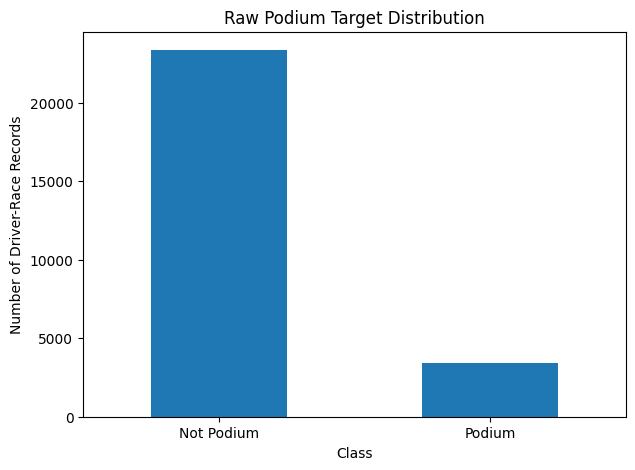

In [7]:
# ============================================================
# 3.6 TARGET CLASS DISTRIBUTION
# ============================================================

podium_raw = (results["positionOrder"] <= 3).astype(int)

target_distribution = podium_raw.value_counts().sort_index()

target_percentages = (
    podium_raw.value_counts(normalize=True)
    .sort_index()
    .mul(100)
)

print("Counts:")
print(target_distribution)

print("\nPercentages:")
print(target_percentages)

plot_counts = target_distribution.rename({
    0: "Not Podium",
    1: "Podium"
})

fig, ax = plt.subplots(figsize=(7, 5))

plot_counts.plot(kind="bar", ax=ax)

ax.set_title("Raw Podium Target Distribution")
ax.set_xlabel("Class")
ax.set_ylabel("Number of Driver-Race Records")

plt.xticks(rotation=0)
plt.show()

In [8]:
# ============================================================
# 3.7 PRIMARY KEY INTEGRITY
# ============================================================

primary_keys = {
    "circuits": ["circuitId"],
    "constructors": ["constructorId"],
    "constructor_results": ["constructorResultsId"],
    "constructor_standings": ["constructorStandingsId"],
    "drivers": ["driverId"],
    "driver_standings": ["driverStandingsId"],
    "races": ["raceId"],
    "results": ["resultId"],
    "qualifying": ["qualifyId"],
    "seasons": ["year"],
    "status": ["statusId"],

    # These tables use composite keys
    "lap_times": ["raceId", "driverId", "lap"],
    "pit_stops": ["raceId", "driverId", "stop"],

    "sprint_results": ["resultId"]
}

pk_results = []

for table_name, key_cols in primary_keys.items():
    df = raw_tables[table_name]

    null_rows = df[key_cols].isna().any(axis=1).sum()
    duplicate_rows = df.duplicated(subset=key_cols).sum()

    pk_results.append({
        "table": table_name,
        "primary_key": ", ".join(key_cols),
        "null_key_rows": null_rows,
        "duplicate_key_rows": duplicate_rows,
        "valid": (null_rows == 0) and (duplicate_rows == 0)
    })

pk_audit = pd.DataFrame(pk_results)

pk_audit

,table,primary_key,null_key_rows,duplicate_key_rows,valid
0,circuits,circuitId,0,0,True
1,constructors,constructorId,0,0,True
2,constructor_results,constructorResultsId,0,0,True
3,constructor_standings,constructorStandingsId,0,0,True
4,drivers,driverId,0,0,True
5,driver_standings,driverStandingsId,0,0,True
6,races,raceId,0,0,True
7,results,resultId,0,0,True
8,qualifying,qualifyId,0,0,True
9,seasons,year,0,0,True


In [9]:
# ============================================================
# 3.8 FOREIGN KEY INTEGRITY
# ============================================================

foreign_keys = [
    # child table, child column, parent table, parent column

    ("races", "circuitId", "circuits", "circuitId"),
    ("races", "year", "seasons", "year"),

    ("results", "raceId", "races", "raceId"),
    ("results", "driverId", "drivers", "driverId"),
    ("results", "constructorId", "constructors", "constructorId"),
    ("results", "statusId", "status", "statusId"),

    ("qualifying", "raceId", "races", "raceId"),
    ("qualifying", "driverId", "drivers", "driverId"),
    ("qualifying", "constructorId", "constructors", "constructorId"),

    ("driver_standings", "raceId", "races", "raceId"),
    ("driver_standings", "driverId", "drivers", "driverId"),

    ("constructor_standings", "raceId", "races", "raceId"),
    ("constructor_standings", "constructorId", "constructors", "constructorId"),

    ("constructor_results", "raceId", "races", "raceId"),
    ("constructor_results", "constructorId", "constructors", "constructorId"),

    ("lap_times", "raceId", "races", "raceId"),
    ("lap_times", "driverId", "drivers", "driverId"),

    ("pit_stops", "raceId", "races", "raceId"),
    ("pit_stops", "driverId", "drivers", "driverId"),

    ("sprint_results", "raceId", "races", "raceId"),
    ("sprint_results", "driverId", "drivers", "driverId"),
    ("sprint_results", "constructorId", "constructors", "constructorId"),
    ("sprint_results", "statusId", "status", "statusId"),
]

fk_results = []

for child_table, child_col, parent_table, parent_col in foreign_keys:

    child_values = set(
        raw_tables[child_table][child_col].dropna().unique()
    )

    parent_values = set(
        raw_tables[parent_table][parent_col].dropna().unique()
    )

    orphan_values = child_values - parent_values

    fk_results.append({
        "child_table": child_table,
        "foreign_key": child_col,
        "parent_table": parent_table,
        "parent_key": parent_col,
        "orphan_values": len(orphan_values),
        "valid": len(orphan_values) == 0
    })

fk_audit = pd.DataFrame(fk_results)

fk_audit

,child_table,foreign_key,parent_table,parent_key,orphan_values,valid
0,races,circuitId,circuits,circuitId,0,True
1,races,year,seasons,year,0,True
2,results,raceId,races,raceId,0,True
3,results,driverId,drivers,driverId,0,True
4,results,constructorId,constructors,constructorId,0,True
5,results,statusId,status,statusId,0,True
6,qualifying,raceId,races,raceId,0,True
7,qualifying,driverId,drivers,driverId,0,True
8,qualifying,constructorId,constructors,constructorId,0,True
9,driver_standings,raceId,races,raceId,0,True


In [10]:
print("Primary key issues:")
display(pk_audit[~pk_audit["valid"]])

print("\nForeign key issues:")
display(fk_audit[~fk_audit["valid"]])

Primary key issues:


,table,primary_key,null_key_rows,duplicate_key_rows,valid



Foreign key issues:


,child_table,foreign_key,parent_table,parent_key,orphan_values,valid


### Initial Audit Findings

The raw dataset contains 14 relational tables covering 75 Formula 1 seasons from 1950 to 2024.
The tables operate at different levels of granularity, ranging from one record per race to
driver-race, driver-lap and driver-pit-stop records. Therefore, tables must be aggregated to
the required driver-race grain before modeling where necessary.

Missing values are represented using both the `\N` sentinel and actual null values. These
representations will be standardized during cleaning. Qualifying data contain substantial
missingness, particularly in Q2 and Q3. Some of this missingness is structural because drivers
eliminated from an earlier qualifying session do not participate in later sessions, while
historical changes in qualifying format and data coverage introduce additional missingness.

The required modeling grain is one row per `(raceId, driverId)`. The raw results table violates
this assumption: 85 driver-race combinations are duplicated, involving 176 rows. These records
require a documented duplicate-handling rule before the modeling table is created.

There are also 1,638 records with `grid == 0`. Inspection shows that many correspond to drivers
who did not qualify, did not prequalify, or withdrew, although some represent other situations.
Therefore, grid position zero cannot be interpreted as a normal starting position and requires
further treatment when defining eligible race starters.

The raw target is imbalanced: 3,397 of 26,759 driver-race result records (12.69%) are podium
finishes. Consequently, accuracy alone would be misleading, and imbalance-sensitive evaluation
metrics will be important during modeling.

Finally, all tested primary keys were unique and non-null, and all tested foreign keys
successfully reconciled with their parent tables. The relational structure is therefore
internally consistent even though the results table still requires cleaning to satisfy the
modeling grain.

# 4. Pre-Cleaning Exploratory Data Analysis

Before modifying the raw dataset, several high-level patterns are explored.

The purpose of this stage is to understand how Formula 1 data coverage and race structure
change over time, identify potential modeling issues, and provide a baseline that can later
be compared with the cleaned dataset.

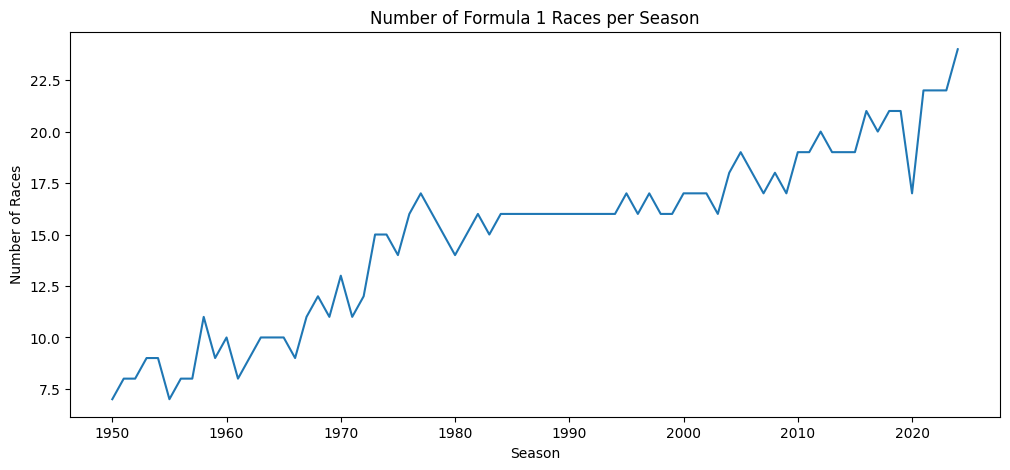

In [11]:
# ============================================================
# 4.1 RACES PER SEASON
# ============================================================

races_per_season = (
    races.groupby("year")["raceId"]
    .nunique()
)

plt.figure(figsize=(12, 5))
plt.plot(races_per_season.index, races_per_season.values)

plt.title("Number of Formula 1 Races per Season")
plt.xlabel("Season")
plt.ylabel("Number of Races")

plt.show()

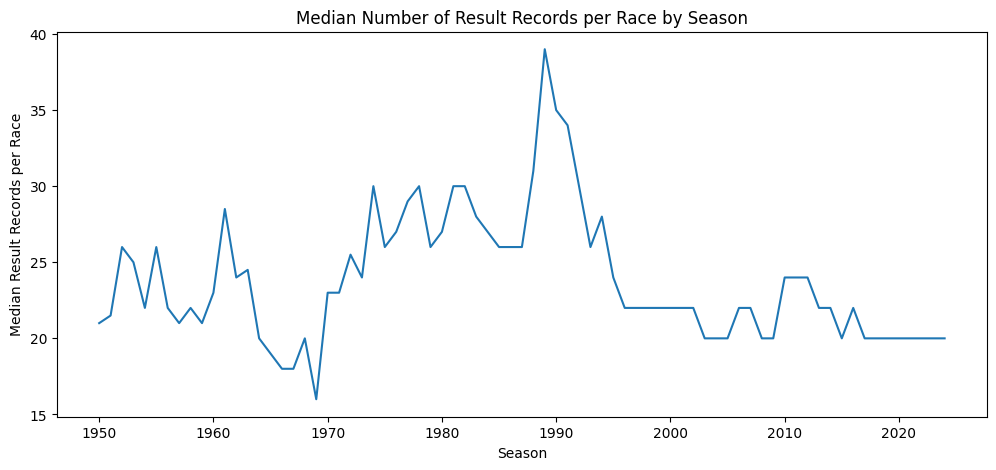

In [12]:
# ============================================================
# 4.2 DRIVER-RESULT RECORDS PER RACE OVER TIME
# ============================================================

race_field_size = (
    results
    .groupby("raceId")
    .size()
    .rename("result_records")
    .reset_index()
    .merge(
        races[["raceId", "year"]],
        on="raceId",
        how="left"
    )
)

field_size_by_year = (
    race_field_size
    .groupby("year")["result_records"]
    .median()
)

plt.figure(figsize=(12, 5))
plt.plot(
    field_size_by_year.index,
    field_size_by_year.values
)

plt.title("Median Number of Result Records per Race by Season")
plt.xlabel("Season")
plt.ylabel("Median Result Records per Race")

plt.show()

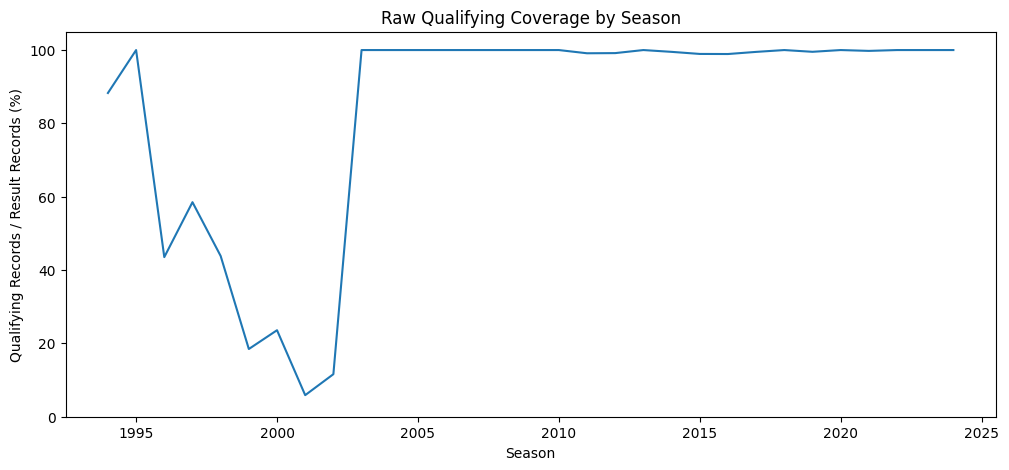

In [13]:
# ============================================================
# 4.3 QUALIFYING COVERAGE BY SEASON
# ============================================================

results_with_year = results.merge(
    races[["raceId", "year"]],
    on="raceId",
    how="left"
)

qualifying_with_year = qualifying.merge(
    races[["raceId", "year"]],
    on="raceId",
    how="left"
)

result_entries_per_year = (
    results_with_year
    .groupby("year")
    .size()
)

qualifying_entries_per_year = (
    qualifying_with_year
    .groupby("year")
    .size()
)

qualifying_coverage = (
    qualifying_entries_per_year
    / result_entries_per_year
    * 100
)

qualifying_coverage = qualifying_coverage.reindex(
    result_entries_per_year.index,
    fill_value=0
)

plt.figure(figsize=(12, 5))

plt.plot(
    qualifying_coverage.index,
    qualifying_coverage.values
)

plt.title("Raw Qualifying Coverage by Season")
plt.xlabel("Season")
plt.ylabel("Qualifying Records / Result Records (%)")

plt.ylim(0, 105)

plt.show()

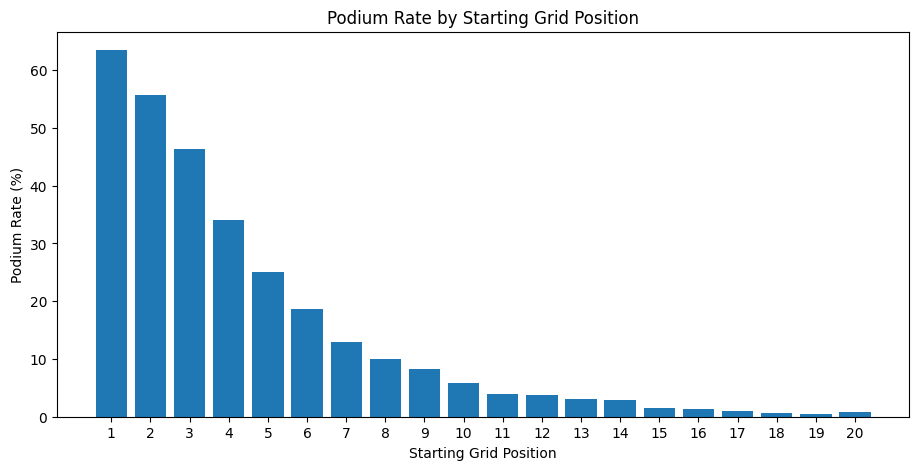

In [14]:
# ============================================================
# 4.4 GRID POSITION VS PODIUM RATE
# ============================================================

grid_analysis = results.loc[
    results["grid"] > 0,
    ["grid", "positionOrder"]
].copy()

grid_analysis["podium"] = (
    grid_analysis["positionOrder"] <= 3
).astype(int)

grid_podium_rate = (
    grid_analysis
    .groupby("grid")["podium"]
    .mean()
    .mul(100)
)

# Focus on the normal modern grid range for readability
grid_podium_rate_plot = grid_podium_rate.loc[
    grid_podium_rate.index <= 20
]

plt.figure(figsize=(11, 5))

plt.bar(
    grid_podium_rate_plot.index,
    grid_podium_rate_plot.values
)

plt.title("Podium Rate by Starting Grid Position")
plt.xlabel("Starting Grid Position")
plt.ylabel("Podium Rate (%)")

plt.xticks(range(1, 21))

plt.show()

### Pre-Cleaning EDA Findings

The raw historical data show substantial changes in Formula 1 across the 1950–2024 period.

The number of races per season and the number of driver-result records per race vary
considerably across eras, meaning that raw historical counts may not be directly comparable
between early and modern Formula 1.

Qualifying coverage also changes strongly over time. This is important because qualifying
features cannot be assumed to exist consistently across the full historical dataset. The
coverage pattern will therefore be considered when selecting the modeling period and
engineering qualifying-based features.

Starting grid position shows a clear relationship with podium probability, supporting its use
as an important pre-race predictive feature. Grid position is known before the race starts and
therefore satisfies the prediction cutoff.

# 5. Data Cleaning

Cleaning is performed in two layers.

### Layer 1 — Cleaned relational tables
All 14 raw tables are copied and cleaned without removing rows. Sentinel missing values are
standardized, semantic data types are applied, and relational integrity is revalidated.

These tables remain suitable for EDA and the three data-engineering questions.

### Layer 2 — Modeling cohort
A separate driver-race table is constructed from the cleaned data. Rows that are known before
the race not to represent eligible race entrants are removed, historical shared-drive duplicates
are resolved, and the final grain is enforced as one row per `(raceId, driverId)`.

The original `raw_tables` are never modified.

In [15]:
# ============================================================
# 5.1 CREATE CLEAN COPIES AND NORMALIZE MISSING VALUES
# ============================================================

clean_tables = {
    name: df.copy(deep=True)
    for name, df in raw_tables.items()
}

missing_conversion = []

for table_name, df in clean_tables.items():

    sentinel_count = sum(
        (raw_tables[table_name][col].astype(str) == r"\N").sum()
        for col in raw_tables[table_name].columns
    )

    existing_nan = int(
        raw_tables[table_name].isna().sum().sum()
    )

    # Convert only the F1 sentinel to true missing values.
    # Existing NaNs remain NaNs.
    clean_tables[table_name] = df.replace({
        r"\N": np.nan
    })

    after_nan = int(
        clean_tables[table_name].isna().sum().sum()
    )

    missing_conversion.append({
        "table": table_name,
        "existing_NaN": existing_nan,
        "sentinels_converted": sentinel_count,
        "NaN_after_cleaning": after_nan
    })

    # Every \N should become one additional NaN
    assert after_nan == existing_nan + sentinel_count

missing_conversion_df = (
    pd.DataFrame(missing_conversion)
    .sort_values("sentinels_converted", ascending=False)
    .reset_index(drop=True)
)

display(missing_conversion_df)

print(
    "Total \\N sentinels converted:",
    missing_conversion_df["sentinels_converted"].sum()
)

,table,existing_NaN,sentinels_converted,NaN_after_cleaning
0,results,0,122887,122887
1,constructor_results,0,12608,12608
2,qualifying,68,11600,11668
3,races,0,11349,11349
4,drivers,0,1559,1559
5,sprint_results,0,73,73
6,driver_standings,0,0,0
7,constructors,0,0,0
8,constructor_standings,0,0,0
9,circuits,0,0,0


Total \N sentinels converted: 160076


## 5.2 Semantic Type Conversion

After missing-value normalization, columns are converted to data types that reflect their
actual meaning.

Dates are converted to datetime values, numeric fields stored as strings are converted to
numbers, and lap-time/duration strings such as `1:23.456` are converted to seconds.

Original time-string columns are retained for traceability, while new `_s` columns contain
their numeric representations.

In [16]:
# ============================================================
# 5.2 SEMANTIC TYPE CONVERSION
# ============================================================

def to_seconds(value):
    """
    Convert a colon-separated time string to seconds.

    Examples:
    1:23.456    -> 83.456
    23.456      -> 23.456
    1:02:03.500 -> 3723.5
    """
    if pd.isna(value):
        return np.nan

    parts = str(value).strip().split(":")

    try:
        seconds = 0.0

        for part in parts:
            seconds = seconds * 60 + float(part)

        return seconds

    except ValueError:
        return np.nan


# ------------------------------------------------------------
# Dates
# ------------------------------------------------------------

race_date_columns = [
    "date",
    "fp1_date",
    "fp2_date",
    "fp3_date",
    "quali_date",
    "sprint_date"
]

for column in race_date_columns:
    clean_tables["races"][column] = pd.to_datetime(
        clean_tables["races"][column],
        errors="coerce"
    )

clean_tables["drivers"]["dob"] = pd.to_datetime(
    clean_tables["drivers"]["dob"],
    errors="coerce"
)


# ------------------------------------------------------------
# Numeric fields that were originally strings because of \N
# ------------------------------------------------------------

numeric_columns = {
    "results": [
        "number",
        "position",
        "milliseconds",
        "fastestLap",
        "rank",
        "fastestLapSpeed"
    ],

    "sprint_results": [
        "position",
        "milliseconds",
        "fastestLap"
    ],

    "drivers": [
        "number"
    ]
}

for table_name, columns in numeric_columns.items():
    for column in columns:
        clean_tables[table_name][column] = pd.to_numeric(
            clean_tables[table_name][column],
            errors="coerce"
        )


# ------------------------------------------------------------
# Duration / lap-time strings -> seconds
# ------------------------------------------------------------

for column in ["q1", "q2", "q3"]:
    clean_tables["qualifying"][f"{column}_s"] = (
        clean_tables["qualifying"][column]
        .map(to_seconds)
    )

clean_tables["results"]["fastestLapTime_s"] = (
    clean_tables["results"]["fastestLapTime"]
    .map(to_seconds)
)

clean_tables["sprint_results"]["fastestLapTime_s"] = (
    clean_tables["sprint_results"]["fastestLapTime"]
    .map(to_seconds)
)

clean_tables["lap_times"]["time_s"] = (
    clean_tables["lap_times"]["time"]
    .map(to_seconds)
)

clean_tables["pit_stops"]["duration_s"] = (
    clean_tables["pit_stops"]["duration"]
    .map(to_seconds)
)


# ------------------------------------------------------------
# Qualifying availability flags
# ------------------------------------------------------------

clean_tables["qualifying"]["q2_recorded"] = (
    clean_tables["qualifying"]["q2_s"].notna()
).astype(int)

clean_tables["qualifying"]["q3_recorded"] = (
    clean_tables["qualifying"]["q3_s"].notna()
).astype(int)


# ------------------------------------------------------------
# Chronological race order
# ------------------------------------------------------------

clean_tables["races"] = (
    clean_tables["races"]
    .sort_values(["year", "round"])
    .reset_index(drop=True)
)

clean_tables["races"]["race_order"] = np.arange(
    len(clean_tables["races"])
)

print("Semantic type conversion complete.")

Semantic type conversion complete.


In [17]:
# ============================================================
# 5.3 CLEANING VALIDATION
# ============================================================

# No literal \N values should remain
remaining_sentinels = 0

for table_name, df in clean_tables.items():
    for column in df.columns:
        remaining_sentinels += (
            df[column].astype(str).eq(r"\N").sum()
        )

assert remaining_sentinels == 0


# Check parsing of important time columns
parse_checks = {
    "qualifying_q1": (
        clean_tables["qualifying"]["q1"].notna()
        & clean_tables["qualifying"]["q1_s"].isna()
    ).sum(),

    "qualifying_q2": (
        clean_tables["qualifying"]["q2"].notna()
        & clean_tables["qualifying"]["q2_s"].isna()
    ).sum(),

    "qualifying_q3": (
        clean_tables["qualifying"]["q3"].notna()
        & clean_tables["qualifying"]["q3_s"].isna()
    ).sum(),

    "lap_times": (
        clean_tables["lap_times"]["time"].notna()
        & clean_tables["lap_times"]["time_s"].isna()
    ).sum(),

    "pit_stops": (
        clean_tables["pit_stops"]["duration"].notna()
        & clean_tables["pit_stops"]["duration_s"].isna()
    ).sum()
}

display(
    pd.Series(
        parse_checks,
        name="unparseable_values"
    ).to_frame()
)


# Pit-stop duration should agree with milliseconds
pit_check = clean_tables["pit_stops"].dropna(
    subset=["duration_s", "milliseconds"]
)

max_difference = (
    pit_check["duration_s"]
    - pit_check["milliseconds"] / 1000
).abs().max()

print(
    "Maximum pit-stop duration difference:",
    max_difference
)

print(
    "Remaining literal \\N values:",
    remaining_sentinels
)

,unparseable_values
qualifying_q1,0
qualifying_q2,0
qualifying_q3,0
lap_times,0
pit_stops,0


Maximum pit-stop duration difference: 2.2737367544323206e-13
Remaining literal \N values: 0


In [18]:
# ============================================================
# 5.4 POST-CLEANING KEY VALIDATION
# ============================================================

for table_name, key_columns in primary_keys.items():

    assert not clean_tables[table_name][key_columns].isna().any(axis=1).any(), (
        f"Missing primary key in {table_name}"
    )

    assert not clean_tables[table_name].duplicated(key_columns).any(), (
        f"Duplicate primary key in {table_name}"
    )


for child_table, child_col, parent_table, parent_col in foreign_keys:

    child_values = set(
        clean_tables[child_table][child_col]
        .dropna()
        .unique()
    )

    parent_values = set(
        clean_tables[parent_table][parent_col]
        .dropna()
        .unique()
    )

    assert child_values.issubset(parent_values), (
        f"Foreign-key problem: {child_table}.{child_col}"
    )


print("All primary and foreign-key checks still pass after cleaning.")

All primary and foreign-key checks still pass after cleaning.


# 5.5 Constructing the Driver-Race Modeling Cohort

The cleaned relational tables retain the complete historical dataset.

A separate modeling cohort is now constructed for podium prediction. Because the prediction
is made after qualifying and before the race starts, drivers who are already known not to
participate should not be treated as ordinary negative examples.

The cohort is therefore restricted to drivers who remain race-eligible at the prediction cutoff.
Historical exceptions are handled separately and documented below.

In [19]:
# ============================================================
# 5.5 REMOVE KNOWN NON-STARTERS
# ============================================================

base = (
    clean_tables["results"]

    .merge(
        clean_tables["races"][
            [
                "raceId",
                "year",
                "round",
                "race_order",
                "name",
                "circuitId",
                "date"
            ]
        ],
        on="raceId",
        how="left"
    )

    .merge(
        clean_tables["status"],
        on="statusId",
        how="left"
    )
)

model_df = base.copy()


NON_START_STATUS = [
    "Did not qualify",
    "Did not prequalify",
    "Withdrew"
]

no_grid_slot = (
    model_df["positionText"].isin(["F", "W"])
    & model_df["grid"].eq(0)
)

known_nonstarter = (
    model_df["status"].isin(NON_START_STATUS)
    | no_grid_slot
)


print("Rows before:", len(model_df))

print("\nRemoved by status:")
display(
    model_df.loc[
        known_nonstarter,
        "status"
    ].value_counts()
)


model_df = (
    model_df.loc[~known_nonstarter]
    .copy()
)


# grid = 0 among remaining race-eligible entries
model_df["grid_zero_start"] = (
    model_df["grid"] == 0
).astype(int)


print("\nRows after removing known non-starters:", len(model_df))
print(
    "Remaining race-eligible grid=0 records:",
    model_df["grid_zero_start"].sum()
)

Rows before: 26759

Removed by status:


status
Did not qualify       1025
Did not prequalify     331
Withdrew               248
Accident                18
Injury                   8
Engine                   6
107% Rule                2
Safety concerns          2
Injured                  2
Fuel system              2
Suspension               1
Fatal accident           1
Brakes                   1
Name: count, dtype: int64


Rows after removing known non-starters: 25112
Remaining race-eligible grid=0 records: 87


### Indianapolis 500

The Indianapolis 500 counted toward the Formula 1 World Championship from 1950 to 1960,
but it operated largely separately from the regular Formula 1 championship and contained
many drivers who did not participate in other Grands Prix.

It is excluded from the modeling cohort because its unusually different field composition and
grid structure could distort historical patterns, particularly the home-race analysis.

The original records remain available in the cleaned relational tables.

In [20]:
# ============================================================
# 5.6 EXCLUDE INDIANAPOLIS 500 FROM MODELING COHORT
# ============================================================

indy_mask = (
    model_df["name"].eq("Indianapolis 500")
    & model_df["year"].between(1950, 1960)
)

print(
    "Indianapolis 500 races:",
    model_df.loc[indy_mask, "raceId"].nunique()
)

print(
    "Rows removed:",
    indy_mask.sum()
)

model_df = (
    model_df.loc[~indy_mask]
    .copy()
)

print(
    "Rows remaining:",
    len(model_df)
)

Indianapolis 500 races: 11
Rows removed: 405
Rows remaining: 24707


In [21]:
# ============================================================
# 5.7 SHARED-DRIVE DUPLICATES
# ============================================================

key = ["raceId", "driverId"]

duplicates = model_df[
    model_df.duplicated(
        key,
        keep=False
    )
].copy()

duplicate_groups = duplicates.groupby(key)

print(
    "Duplicate driver-race pairs:",
    duplicate_groups.ngroups
)

print(
    "Rows involved:",
    len(duplicates)
)

print(
    "Seasons:",
    duplicates["year"].min(),
    "-",
    duplicates["year"].max()
)


# Can grid identify the original car?
positive_grid_counts = (
    duplicates
    .assign(has_grid=duplicates["grid"] > 0)
    .groupby(key)["has_grid"]
    .sum()
    .value_counts()
)

print("\nNumber of positive-grid records per duplicate pair:")
display(positive_grid_counts)


# Compare two deterministic rules
first_rule = (
    duplicates
    .sort_values("resultId")
    .drop_duplicates(key)
)

best_finish_rule = (
    duplicates
    .sort_values("positionOrder")
    .drop_duplicates(key)
)


pairs_with_any_podium = (duplicate_groups["positionOrder"].min().le(3).sum())

comparison = pd.DataFrame({
    "rule": [
        "Keep first record",
        "Keep best positionOrder"
    ],

    "podium rows preserved": [
        (first_rule["positionOrder"] <= 3).sum(),
        (best_finish_rule["positionOrder"] <= 3).sum()
    ],

    "total duplicate pairs containing a podium": [
        pairs_with_any_podium,
        pairs_with_any_podium
    ]
})

display(comparison)

Duplicate driver-race pairs: 61
Rows involved: 125
Seasons: 1950 - 1964

Number of positive-grid records per duplicate pair:


has_grid
2    58
3     3
Name: count, dtype: int64

,rule,podium rows preserved,total duplicate pairs containing a podium
0,Keep first record,6,21
1,Keep best positionOrder,21,21


In [22]:
before_duplicates = len(model_df)

model_df = (model_df.sort_values(["raceId", "driverId", "positionOrder"])
    .drop_duplicates(["raceId", "driverId"],keep="first")
    .sort_values(["race_order", "positionOrder"])
    .reset_index(drop=True))

print("Rows removed by duplicate resolution:", before_duplicates - len(model_df))

print("Rows remaining:", len(model_df))

Rows removed by duplicate resolution: 64
Rows remaining: 24643


### Shared-Drive Duplicate Rule

Historical shared drives create multiple result rows for the same `(raceId, driverId)`. Grid
position cannot reliably identify which record should represent the driver because almost all
duplicate pairs contain multiple positive-grid records.

Two deterministic rules were compared. Keeping the first result record preserved only 6 of the
21 duplicate driver-race pairs containing a podium, while keeping the best `positionOrder`
preserved all 21.

The best finishing position is therefore retained as the single historical representation of each
duplicated driver-race pair.

This rule uses post-race outcome information and is therefore a historical deduplication rule rather
than a predictive feature. All affected duplicates occur between 1950 and 1964, well before the
2003–2024 modeling period, so this decision cannot leak current-race outcomes into model training,
validation or testing.

In [23]:
# ============================================================
# 5.8 FINAL MODELING-COHORT VALIDATION
# ============================================================

model_df["podium"] = (model_df["positionOrder"] <= 3).astype(int)

# Required grain
assert not model_df.duplicated(["raceId", "driverId"]).any()

# Target must exist
assert model_df["podium"].notna().all()

# There can only be three distinct finishing positions representing podium places in a race
podium_positions = (model_df.loc[model_df["podium"] == 1]
    .groupby("raceId")["positionOrder"]
    .nunique())

assert podium_positions.max() <= 3

print("Final modeling cohort validation passed.")

print("\nRows:", len(model_df))

print("Unique driver-race pairs:", model_df[["raceId", "driverId"]].drop_duplicates().shape[0])

print("Podium rate:", round(model_df["podium"].mean() * 100, 2),"%")

Final modeling cohort validation passed.

Rows: 24643
Unique driver-race pairs: 24643
Podium rate: 13.63 %


# 6. Post-Cleaning Exploratory Data Analysis

The cleaned relational tables preserve the complete historical dataset, while the modeling
cohort applies the eligibility and grain rules required for podium prediction.

This section compares the raw `results` table with the final driver-race modeling cohort to
measure the effect of cleaning and filtering.

In [24]:
# ============================================================
# 6.1 CLEANING IMPACT SUMMARY
# ============================================================

raw_podium = (results["positionOrder"] <= 3).astype(int)

raw_duplicate_pairs = (
    results.loc[
        results.duplicated(["raceId", "driverId"], keep=False),
        ["raceId", "driverId"]
    ]
    .drop_duplicates()
    .shape[0]
)

final_duplicate_pairs = (
    model_df.loc[
        model_df.duplicated(["raceId", "driverId"], keep=False),
        ["raceId", "driverId"]
    ]
    .drop_duplicates()
    .shape[0]
)

cleaning_impact = pd.DataFrame({
    "Metric": [
        "Driver-race rows",
        "Podium rate (%)",
        "Duplicate (raceId, driverId) pairs",
        "grid == 0 rows"
    ],

    "Before": [
        len(results),
        raw_podium.mean() * 100,
        raw_duplicate_pairs,
        (results["grid"] == 0).sum()
    ],

    "After": [
        len(model_df),
        model_df["podium"].mean() * 100,
        final_duplicate_pairs,
        (model_df["grid"] == 0).sum()
    ]
})

display(cleaning_impact)

rows_removed = len(results) - len(model_df)

print(
    f"\nRows removed from modeling cohort: "
    f"{rows_removed:,} "
    f"({rows_removed / len(results) * 100:.2f}%)"
)

,Metric,Before,After
0,Driver-race rows,26759.000000,24643.000000
1,Podium rate (%),12.694794,13.630646
2,"Duplicate (raceId, driverId) pairs",85.000000,0.000000
3,grid == 0 rows,1638.000000,87.000000



Rows removed from modeling cohort: 2,116 (7.91%)


,Raw results,Modeling cohort
Not Podium,87.305206,86.369354
Podium,12.694794,13.630646


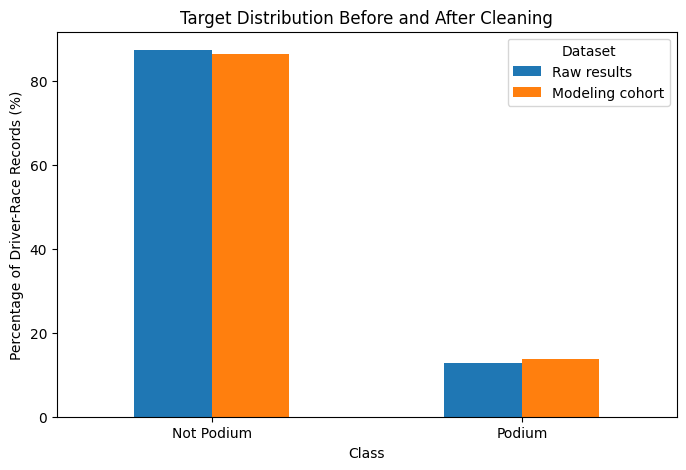

In [25]:
# ============================================================
# 6.2 TARGET DISTRIBUTION BEFORE VS AFTER CLEANING
# ============================================================

target_comparison = pd.DataFrame({
    "Raw results": [
        (raw_podium == 0).mean() * 100,
        (raw_podium == 1).mean() * 100
    ],

    "Modeling cohort": [
        (model_df["podium"] == 0).mean() * 100,
        (model_df["podium"] == 1).mean() * 100
    ]
},
index=["Not Podium", "Podium"])

display(target_comparison)

ax = target_comparison.plot(
    kind="bar",
    figsize=(8, 5)
)

ax.set_title("Target Distribution Before and After Cleaning")
ax.set_xlabel("Class")
ax.set_ylabel("Percentage of Driver-Race Records (%)")

plt.xticks(rotation=0)
plt.legend(title="Dataset")
plt.show()

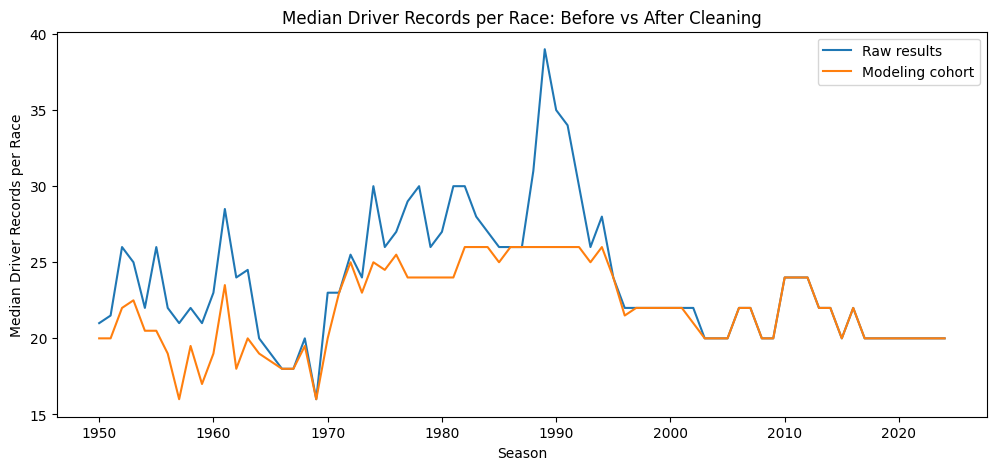

In [26]:
# ============================================================
# 6.3 FIELD SIZE BEFORE VS AFTER CLEANING
# ============================================================

raw_field_size = (
    results
    .groupby("raceId")
    .size()
    .rename("raw_records")
    .reset_index()
)

clean_field_size = (
    model_df
    .groupby("raceId")
    .size()
    .rename("modeling_records")
    .reset_index()
)

raw_field_size = raw_field_size.merge(
    clean_tables["races"][["raceId", "year"]],
    on="raceId",
    how="left"
)

clean_field_size = clean_field_size.merge(
    clean_tables["races"][["raceId", "year"]],
    on="raceId",
    how="left"
)

raw_yearly_field = (
    raw_field_size
    .groupby("year")["raw_records"]
    .median()
)

clean_yearly_field = (
    clean_field_size
    .groupby("year")["modeling_records"]
    .median()
)

plt.figure(figsize=(12, 5))

plt.plot(
    raw_yearly_field.index,
    raw_yearly_field.values,
    label="Raw results"
)

plt.plot(
    clean_yearly_field.index,
    clean_yearly_field.values,
    label="Modeling cohort"
)

plt.title("Median Driver Records per Race: Before vs After Cleaning")
plt.xlabel("Season")
plt.ylabel("Median Driver Records per Race")

plt.legend()
plt.show()

### Post-Cleaning EDA Findings

The modeling-cohort construction reduced the raw results table from 26,759 to 24,643
driver-race rows, removing 2,116 records (7.91%).

The podium rate increased only slightly, from 12.69% to 13.63%. This indicates that removing
known non-starters mainly eliminated trivial negative examples rather than substantially
changing the target distribution.

All 85 duplicated `(raceId, driverId)` combinations were resolved, so the final modeling
cohort now satisfies the required one-driver-per-race grain.

The number of `grid == 0` records fell from 1,638 to 87. Most zero-grid records therefore
represented drivers who were already known not to participate, while the remaining cases are
retained because they were still race-eligible at the prediction cutoff.

The historical field-size comparison also shows why filtering is especially important for
older Formula 1 seasons, where the raw results table includes considerably more entrants who
did not ultimately compete in the race.

# 7. Data-Engineering Questions

Each question is answered using the cleaned driver-race cohort and multi-table joins.

For every analysis, one row represents one driver in one race. The analyses also document
missing data and distinguish information known before the race from post-race outcomes.

## 7.1 Front-Row Start to Podium Conversion by Circuit

A front-row start is defined primarily using the actual race grid (`grid = 1 or 2`).

Qualifying position is analysed separately because penalties can cause qualifying position and
starting grid position to differ. The comparison is restricted to 2003–2024 because detailed
qualifying coverage is complete from 2003 onward.

The periods compared are 2003–2013 and 2014–2024. Circuits must have at least 10 front-row
starts in each period to be included in the ranking comparison.

In [27]:
# ============================================================
# 7.1 FRONT-ROW -> PODIUM BY CIRCUIT
# ============================================================

circuit_info = clean_tables["circuits"][["circuitId","name","country"]].rename(columns={"name":"circuit_name","country":"circuit_country"})
qual_info = clean_tables["qualifying"][["raceId","driverId","position"]].rename(columns={"position":"qualifying_position"})

q1 = (model_df.merge(circuit_info, on="circuitId", how="left", validate="many_to_one")
      .merge(qual_info, on=["raceId","driverId"], how="left", validate="one_to_one"))
q1 = q1[q1["year"].between(2003,2024)].copy()
q1["era"] = np.where(q1["year"]<=2013, "2003–2013", "2014–2024")
q1["front_row_grid"] = q1["grid"].isin([1,2])
q1["front_row_qualifying"] = q1["qualifying_position"].isin([1,2])

grid_rates = (q1[q1["front_row_grid"]].groupby(["circuit_name","era"])
              .agg(front_row_starts=("podium","size"), podiums=("podium","sum"), podium_rate=("podium","mean")).reset_index())
grid_rates["podium_rate_pct"] = grid_rates["podium_rate"]*100

sprint_21_22 = (clean_tables["sprint_results"][["raceId"]].drop_duplicates()
                .merge(clean_tables["races"][["raceId","year"]], on="raceId", how="left"))
sprint_21_22_ids = set(sprint_21_22.loc[sprint_21_22["year"].isin([2021,2022]), "raceId"])

q1_qual = q1[~q1["raceId"].isin(sprint_21_22_ids)].copy()
qual_rates = (q1_qual[q1_qual["front_row_qualifying"]].groupby(["circuit_name","era"])
              .agg(qual_front_rows=("podium","size"), qual_podiums=("podium","sum"), qual_podium_rate=("podium","mean")).reset_index())
qual_rates["qual_podium_rate_pct"] = qual_rates["qual_podium_rate"]*100

display(grid_rates.sort_values(["era","podium_rate"], ascending=[True,False]).head(20))

,circuit_name,era,front_row_starts,podiums,podium_rate,podium_rate_pct
26,Circuit of the Americas,2003–2013,4,4,1.000000,100.000000
45,Red Bull Ring,2003–2013,2,2,1.000000,100.000000
23,Circuit de Nevers Magny-Cours,2003–2013,12,11,0.916667,91.666667
33,Indianapolis Motor Speedway,2003–2013,8,7,0.875000,87.500000
14,Buddh International Circuit,2003–2013,6,5,0.833333,83.333333
34,Istanbul Park,2003–2013,14,11,0.785714,78.571429
5,Autodromo Nazionale di Monza,2003–2013,22,17,0.772727,77.272727
21,Circuit de Monaco,2003–2013,22,17,0.772727,77.272727
51,Silverstone Circuit,2003–2013,22,16,0.727273,72.727273
24,Circuit de Spa-Francorchamps,2003–2013,18,13,0.722222,72.222222


Spearman rank correlation: 0.303
p-value: 0.292
Eligible circuits: 14


,rate_2003_2013,rate_2014_2024,starts_2003_2013,starts_2014_2024,rank_2003_2013,rank_2014_2024,rank_change
circuit_name,,,,,,,
Suzuka Circuit,72.222222,88.888889,18.0,18.0,4.0,1.0,3.0
Yas Marina Circuit,60.000000,86.363636,10.0,22.0,10.0,2.0,8.0
Circuit de Monaco,77.272727,85.000000,22.0,20.0,1.0,3.0,-2.0
Circuit de Barcelona-Catalunya,68.181818,81.818182,22.0,22.0,6.0,4.0,2.0
Circuit de Spa-Francorchamps,72.222222,81.818182,18.0,22.0,4.0,4.0,0.0
Autódromo José Carlos Pace,59.090909,78.947368,22.0,19.0,12.0,6.0,6.0
Shanghai International Circuit,65.000000,78.571429,20.0,14.0,8.0,7.0,1.0
Circuit Gilles Villeneuve,60.000000,77.777778,20.0,18.0,10.0,8.0,2.0
Silverstone Circuit,72.727273,75.000000,22.0,24.0,3.0,9.0,-6.0


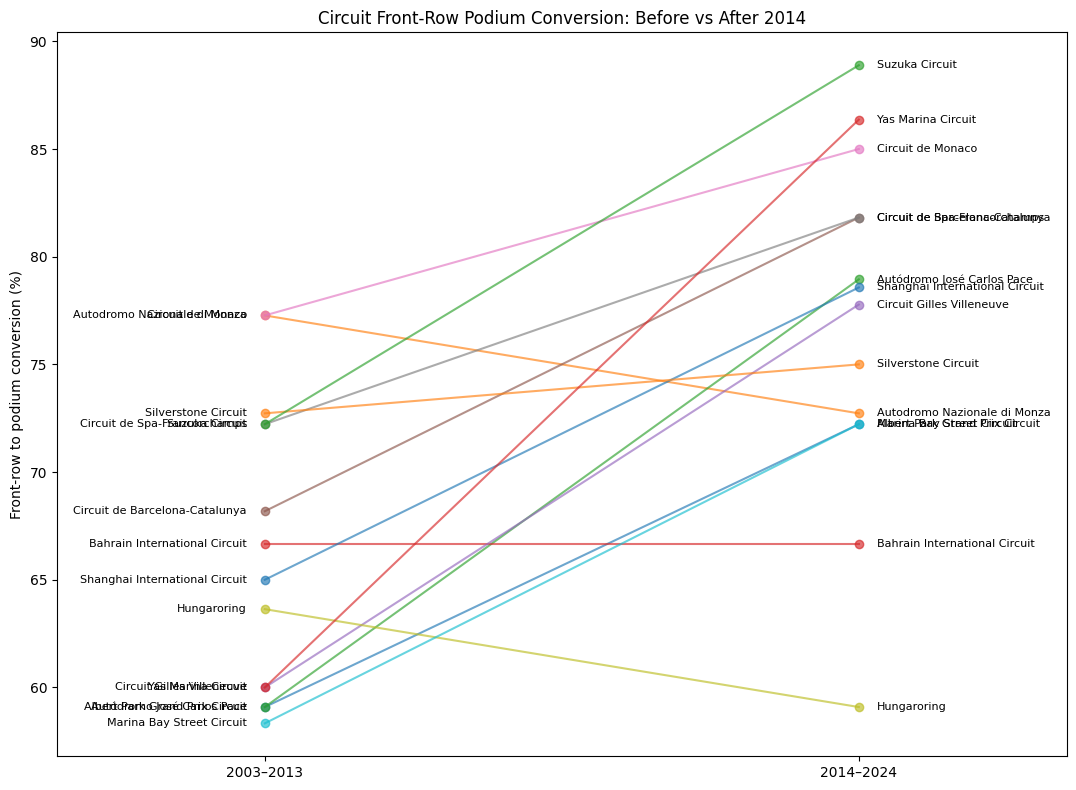

In [28]:
from scipy.stats import spearmanr

MIN_STARTS = 10

rates = grid_rates.pivot(index="circuit_name", columns="era", values=["front_row_starts","podium_rate_pct"])
eligible = rates[(rates[("front_row_starts","2003–2013")]>=MIN_STARTS) & (rates[("front_row_starts","2014–2024")]>=MIN_STARTS)].copy()

rank_compare = pd.DataFrame({
    "rate_2003_2013":eligible[("podium_rate_pct","2003–2013")],
    "rate_2014_2024":eligible[("podium_rate_pct","2014–2024")],
    "starts_2003_2013":eligible[("front_row_starts","2003–2013")],
    "starts_2014_2024":eligible[("front_row_starts","2014–2024")]
})

rank_compare["rank_2003_2013"] = rank_compare["rate_2003_2013"].rank(ascending=False, method="min")
rank_compare["rank_2014_2024"] = rank_compare["rate_2014_2024"].rank(ascending=False, method="min")
rank_compare["rank_change"] = rank_compare["rank_2003_2013"] - rank_compare["rank_2014_2024"]

rho, p = spearmanr(rank_compare["rate_2003_2013"], rank_compare["rate_2014_2024"])
print(f"Spearman rank correlation: {rho:.3f}")
print(f"p-value: {p:.3f}")

print("Eligible circuits:", len(rank_compare))
display(rank_compare.sort_values("rank_2014_2024"))

fig, ax = plt.subplots(figsize=(11,8))
for circuit,row in rank_compare.iterrows():
    ax.plot([0,1], [row["rate_2003_2013"],row["rate_2014_2024"]], marker="o", alpha=.65)
    ax.text(-.03,row["rate_2003_2013"],circuit,ha="right",va="center",fontsize=8)
    ax.text(1.03,row["rate_2014_2024"],circuit,ha="left",va="center",fontsize=8)
ax.set_xlim(-.35,1.35)
ax.set_xticks([0,1],["2003–2013","2014–2024"])
ax.set_ylabel("Front-row to podium conversion (%)")
ax.set_title("Circuit Front-Row Podium Conversion: Before vs After 2014")
plt.tight_layout()
plt.show()

In [29]:
q1_compare = q1_qual[q1_qual["qualifying_position"].notna()].copy()

qualified_front_started_back = (q1_compare["front_row_qualifying"] & ~q1_compare["front_row_grid"]).sum()
promoted_to_front = (~q1_compare["front_row_qualifying"] & q1_compare["front_row_grid"]).sum()
exact_match = (q1_compare["qualifying_position"]==q1_compare["grid"]).mean()*100

definition_rates = grid_rates.merge(qual_rates, on=["circuit_name","era"], how="outer")
print(f"Exact qualifying/grid position match: {exact_match:.2f}%")
print("Qualified front row but did not start front row:", qualified_front_started_back)
print("Did not qualify front row but started front row:", promoted_to_front)

display(definition_rates[["circuit_name","era","front_row_starts","podium_rate_pct","qual_front_rows","qual_podium_rate_pct"]]
        .sort_values(["era","podium_rate_pct"], ascending=[True,False]))

Exact qualifying/grid position match: 73.15%
Qualified front row but did not start front row: 32
Did not qualify front row but started front row: 31


,circuit_name,era,front_row_starts,podium_rate_pct,qual_front_rows,qual_podium_rate_pct
26,Circuit of the Americas,2003–2013,4,100.000000,4,100.000000
45,Red Bull Ring,2003–2013,2,100.000000,2,100.000000
23,Circuit de Nevers Magny-Cours,2003–2013,12,91.666667,12,91.666667
33,Indianapolis Motor Speedway,2003–2013,8,87.500000,8,87.500000
14,Buddh International Circuit,2003–2013,6,83.333333,6,83.333333
34,Istanbul Park,2003–2013,14,78.571429,14,78.571429
5,Autodromo Nazionale di Monza,2003–2013,22,77.272727,22,72.727273
21,Circuit de Monaco,2003–2013,22,77.272727,22,68.181818
51,Silverstone Circuit,2003–2013,22,72.727273,22,77.272727
24,Circuit de Spa-Francorchamps,2003–2013,18,72.222222,18,72.222222


In [30]:
qual_pivot = qual_rates.pivot(index="circuit_name", columns="era", values=["qual_front_rows","qual_podium_rate"])

qual_eligible = qual_pivot[
    (qual_pivot[("qual_front_rows","2003–2013")]>=MIN_STARTS) &
    (qual_pivot[("qual_front_rows","2014–2024")]>=MIN_STARTS)
]

qual_rho, qual_p = spearmanr(
    qual_eligible[("qual_podium_rate","2003–2013")],
    qual_eligible[("qual_podium_rate","2014–2024")]
)

print(f"Qualifying-defined Spearman rho: {qual_rho:.3f}")
print(f"p-value: {qual_p:.3f}")

Qualifying-defined Spearman rho: 0.547
p-value: 0.043


**Grain:** one driver in one race.

**Missing data:** detailed qualifying data are used only from 2003 onward, where coverage is
complete. The six 2021–2022 sprint weekends are excluded from the qualifying-vs-grid version
because qualifying did not directly determine the Sunday race grid.

**Pre-race cutoff:** both qualifying position and actual starting grid are known before the race
and are therefore valid pre-race information. Finishing position is post-race information used
only to calculate the historical podium outcome for this analysis.

### Question 1 Answer

Among circuits with at least 10 front-row starts in both periods, the front-row-to-podium
ranking changed considerably between 2003–2013 and 2014–2024.

In 2003–2013, Monaco and Monza had the highest conversion rate among the comparable
circuits at 77.27%. In 2014–2024, Suzuka ranked highest at 88.89%, followed by Yas Marina
at 86.36% and Monaco at 85.00%.

Using the actual starting grid, the Spearman rank correlation between the two circuit rankings
was approximately 0.30 (p = 0.292), indicating that the circuit ordering changed substantially.

Qualifying position and actual grid position are not interchangeable. After excluding the
2021–2022 sprint weekends, the exact qualifying and grid positions matched only 73.15% of
the time. 32 drivers qualified on the front row but did not start there, while 31 drivers were
promoted onto the front row.

Using qualifying-defined front rows produced a higher rank correlation of approximately
0.55 (p = 0.043), compared with approximately 0.30 using the actual grid. This suggests that
penalties and other changes between qualifying and the final starting grid contribute to some
of the difference between the two era rankings.

Therefore, actual starting grid is used as the primary definition of a front-row start because
the question concerns where the driver actually started the race.

## 7.2 Home-Race Podium Performance

A driver is considered to be racing at home when the driver's nationality matches the country
of the circuit.

Because nationality and country labels use different formats, the values are standardized before
comparison. Podium rates are then compared within similar starting-grid groups so that any
observed difference is not simply caused by home drivers starting further forward.

In [31]:
# ============================================================
# 7.2 HOME-RACE PODIUM PERFORMANCE
# ============================================================

driver_info = clean_tables["drivers"][["driverId","nationality"]].copy()
circuit_country = clean_tables["circuits"][["circuitId","country"]].rename(columns={"country":"circuit_country"})

q2 = (model_df.merge(driver_info, on="driverId", how="left", validate="many_to_one")
      .merge(circuit_country, on="circuitId", how="left", validate="many_to_one"))
q2["nationality_clean"] = q2["nationality"].astype("string").str.strip()
q2["circuit_country_clean"] = q2["circuit_country"].replace({"United States":"USA"})

nationality_map = {
    "American":{"USA"},"American-Italian":{"USA","Italy"},"Argentine":{"Argentina"},"Argentine-Italian":{"Argentina","Italy"},
    "Argentinian":{"Argentina"},"Australian":{"Australia"},"Austrian":{"Austria"},"Belgian":{"Belgium"},"Brazilian":{"Brazil"},
    "British":{"UK"},"Canadian":{"Canada"},"Chilean":{"Chile"},"Chinese":{"China"},"Colombian":{"Colombia"},
    "Czech":{"Czech Republic"},"Danish":{"Denmark"},"Dutch":{"Netherlands"},"East German":{"Germany"},"Finnish":{"Finland"},
    "French":{"France"},"German":{"Germany"},"Hungarian":{"Hungary"},"Indian":{"India"},"Indonesian":{"Indonesia"},
    "Irish":{"Ireland"},"Italian":{"Italy"},"Japanese":{"Japan"},"Liechtensteiner":{"Liechtenstein"},"Malaysian":{"Malaysia"},
    "Mexican":{"Mexico"},"Monegasque":{"Monaco"},"New Zealander":{"New Zealand"},"Polish":{"Poland"},"Portuguese":{"Portugal"},
    "Rhodesian":{"Rhodesia"},"Russian":{"Russia"},"South African":{"South Africa"},"Spanish":{"Spain"},"Swedish":{"Sweden"},
    "Swiss":{"Switzerland"},"Thai":{"Thailand"},"Uruguayan":{"Uruguay"},"Venezuelan":{"Venezuela"}
}

q2["mapped"] = q2["nationality_clean"].isin(nationality_map)
q2["home_race"] = q2.apply(lambda r: r["circuit_country_clean"] in nationality_map.get(r["nationality_clean"],set()), axis=1)
q2["grid_group"] = pd.cut(q2["grid"], bins=[0,3,6,10,np.inf], labels=["1–3","4–6","7–10","11+"])

print("Rows with unmapped nationality:", (~q2["mapped"]).sum())
print("Grid-zero rows excluded from grouped comparison:", q2["grid_group"].isna().sum())

q2_analysis = q2[q2["mapped"] & q2["grid_group"].notna()].copy()

Rows with unmapped nationality: 0
Grid-zero rows excluded from grouped comparison: 87


,grid_group,home_race,starts,podiums,podium_rate,podium_rate_pct
0,1–3,False,3101,1725,0.556272,55.627217
1,1–3,True,229,131,0.572052,57.205240
2,4–6,False,3103,812,0.261682,26.168224
3,4–6,True,224,61,0.272321,27.232143
4,7–10,False,4101,385,0.093880,9.387954
5,7–10,True,336,25,0.074405,7.440476
6,11+,False,12317,207,0.016806,1.680604
7,11+,True,1145,13,0.011354,1.135371


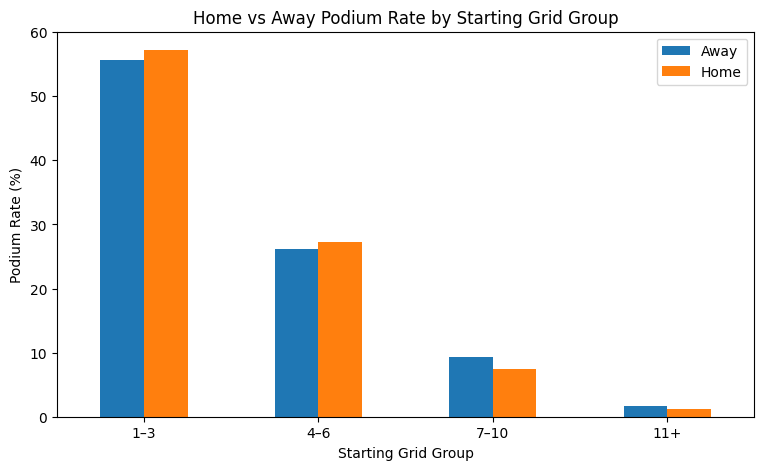

In [32]:
home_rates = (q2_analysis.groupby(["grid_group","home_race"], observed=True)["podium"]
              .agg(starts="size", podiums="sum", podium_rate="mean").reset_index())
home_rates["podium_rate_pct"] = home_rates["podium_rate"]*100

display(home_rates)

home_plot = home_rates.pivot(index="grid_group", columns="home_race", values="podium_rate_pct")
home_plot.columns = ["Away","Home"]

home_plot.plot(kind="bar", figsize=(9,5))
plt.title("Home vs Away Podium Rate by Starting Grid Group")
plt.xlabel("Starting Grid Group")
plt.ylabel("Podium Rate (%)")
plt.xticks(rotation=0)
plt.show()

In [33]:
import statsmodels.formula.api as smf

q2_analysis["home_int"] = q2_analysis["home_race"].astype(int)
home_model = smf.logit("podium ~ home_int + C(grid_group)", data=q2_analysis).fit(disp=False)

home_coef = home_model.params["home_int"]
home_or = np.exp(home_coef)
home_ci = np.exp(home_model.conf_int().loc["home_int"])
home_p = home_model.pvalues["home_int"]

print(f"Adjusted home odds ratio: {home_or:.3f}")
print(f"95% CI: [{home_ci.iloc[0]:.3f}, {home_ci.iloc[1]:.3f}]")
print(f"p-value: {home_p:.4f}")

Adjusted home odds ratio: 0.955
95% CI: [0.806, 1.132]
p-value: 0.5966


**Grain:** one driver in one race.

**Missing data:** nationality strings were stripped and mapped to circuit-country labels.
`USA` and `United States` were normalized to the same country. No driver nationalities in
the analysis remained unmapped. Grid-zero records were excluded because they cannot be
assigned to one of the defined grid-position groups.

Hyphenated nationalities are treated as home in either represented country. For example,
an American-Italian driver is considered to be racing at home in either the USA or Italy.

**Pre-race cutoff:** starting grid and driver nationality are known before the race. Podium
outcome is post-race and is used only as the dependent variable.

The grouped comparison and logistic regression describe an association, not a causal effect.

### Question 2 Answer

Home drivers had slightly higher podium rates from grid positions 1–3 and 4–6, but slightly
lower podium rates from positions 7–10 and 11+, so the pattern is not consistently favourable
to home drivers.

After adjusting for starting-grid group using logistic regression, the estimated home-race
odds ratio was 0.955 (95% CI: 0.806–1.132, p = 0.597).

Because the odds ratio is close to 1 and the confidence interval includes 1, the data provide
no evidence of a meaningful association between racing in a driver's home country and podium
probability once starting position is accounted for.

This is an observational association and should not be interpreted causally.

## 7.3 Constructor Mechanical-Retirement Rates

Mechanical-retirement rate is defined as the percentage of a constructor's car starts that ended
because of a technical or component failure.

Statuses are divided into a strict mechanical group, a clearly non-mechanical group, and an
ambiguous group. The analysis is repeated with ambiguous statuses included to test whether
the constructor ranking is sensitive to the classification choice.

In [34]:
# ============================================================
# 7.3 MECHANICAL RETIREMENTS BY CONSTRUCTOR
# ============================================================

strict_mechanical = {
    "Engine","Gearbox","Transmission","Clutch","Hydraulics","Electrical","Radiator","Suspension","Brakes",
    "Differential","Overheating","Mechanical","Driveshaft","Fuel pressure","Water pressure","Throttle","Steering",
    "Technical","Electronics","Exhaust","Oil leak","Water leak","Fuel pump","Battery","Power loss","Oil pressure",
    "Fuel system","ERS","Power Unit","Turbo","Cooling system","Water pump","Fuel leak","Drivetrain","Brake duct","Spark plugs"
}

unclear_mechanical = {"Retired","Puncture","Wheel","Front wing","Tyre","Wheel nut","Undertray",
                      "Rear wing","Vibrations","Damage","Seat","Debris","Out of fuel"}

constructor_info = clean_tables["constructors"][["constructorId","name"]].rename(columns={"name":"constructor_name"})

q3 = model_df[model_df["year"].between(2014,2024)].copy()
q3 = q3[q3["positionText"] != "W"].copy()

q3 = q3.merge(constructor_info, on="constructorId", how="left", validate="many_to_one")
q3["era"] = np.where(q3["year"]<=2021, "2014–2021", "2022–2024")
q3["mechanical_strict"] = q3["status"].isin(strict_mechanical)
q3["mechanical_inclusive"] = q3["status"].isin(strict_mechanical | unclear_mechanical)

display(q3["status"].value_counts().rename_axis("status").reset_index(name="count"))
print("Pre-start withdrawals excluded:", ((model_df["year"].between(2014,2024)) & (model_df["positionText"]=="W")).sum())

,status,count
0,Finished,2403
1,+1 Lap,1178
2,+2 Laps,208
3,Collision,150
4,Accident,85
5,Engine,79
6,Collision damage,59
7,Retired,49
8,Brakes,48
9,Gearbox,40


Pre-start withdrawals excluded: 14


In [35]:
constructor_rates = (q3.groupby(["era","constructor_name"])
                     .agg(car_starts=("raceId","size"), strict_failures=("mechanical_strict","sum"),
                          inclusive_failures=("mechanical_inclusive","sum")).reset_index())

constructor_rates["strict_rate"] = constructor_rates["strict_failures"]/constructor_rates["car_starts"]*100
constructor_rates["inclusive_rate"] = constructor_rates["inclusive_failures"]/constructor_rates["car_starts"]*100

MIN_CAR_STARTS = 60

for era in ["2014–2021","2022–2024"]:
    era_all = constructor_rates[constructor_rates["era"]==era].sort_values("strict_rate", ascending=False)
    era_ranked = era_all[era_all["car_starts"]>=MIN_CAR_STARTS]

    print(f"\n{era} — all constructors")
    display(era_all[["constructor_name","car_starts","strict_failures","strict_rate","inclusive_rate"]])

    print(f"\n{era} — ranking with at least {MIN_CAR_STARTS} car starts")
    display(era_ranked[["constructor_name","car_starts","strict_failures","strict_rate","inclusive_rate"]])

    rho = era_all["strict_rate"].rank(ascending=False).corr(era_all["inclusive_rate"].rank(ascending=False))
    print(f"Strict vs inclusive rank correlation: {rho:.3f}")


2014–2021 — all constructors


,constructor_name,car_starts,strict_failures,strict_rate,inclusive_rate
4,Caterham,33,7,21.212121,30.303030
8,Lotus F1,75,13,17.333333,24.000000
17,Toro Rosso,242,39,16.115702,18.181818
15,Renault,199,26,13.065327,16.080402
11,McLaren,315,40,12.698413,15.238095
14,Red Bull,318,34,10.691824,11.635220
16,Sauber,199,21,10.552764,13.065327
10,Marussia,31,3,9.677419,9.677419
1,AlphaTauri,77,7,9.090909,10.389610
13,Racing Point,75,6,8.000000,9.333333



2014–2021 — ranking with at least 60 car starts


,constructor_name,car_starts,strict_failures,strict_rate,inclusive_rate
8,Lotus F1,75,13,17.333333,24.000000
17,Toro Rosso,242,39,16.115702,18.181818
15,Renault,199,26,13.065327,16.080402
11,McLaren,315,40,12.698413,15.238095
14,Red Bull,318,34,10.691824,11.635220
16,Sauber,199,21,10.552764,13.065327
1,AlphaTauri,77,7,9.090909,10.389610
13,Racing Point,75,6,8.000000,9.333333
7,Haas F1 Team,240,18,7.500000,12.083333
18,Williams,319,23,7.210031,9.717868


Strict vs inclusive rank correlation: 0.963

2022–2024 — all constructors


,constructor_name,car_starts,strict_failures,strict_rate,inclusive_rate
19,Alfa Romeo,88,11,12.500000,12.500000
21,Alpine F1 Team,135,14,10.370370,10.370370
20,AlphaTauri,88,6,6.818182,7.954545
30,Williams,134,7,5.223881,8.208955
23,Ferrari,134,6,4.477612,6.716418
24,Haas F1 Team,135,6,4.444444,5.185185
26,Mercedes,136,6,4.411765,4.411765
27,RB F1 Team,48,2,4.166667,10.416667
28,Red Bull,136,5,3.676471,4.411765
25,McLaren,136,5,3.676471,3.676471



2022–2024 — ranking with at least 60 car starts


,constructor_name,car_starts,strict_failures,strict_rate,inclusive_rate
19,Alfa Romeo,88,11,12.500000,12.500000
21,Alpine F1 Team,135,14,10.370370,10.370370
20,AlphaTauri,88,6,6.818182,7.954545
30,Williams,134,7,5.223881,8.208955
23,Ferrari,134,6,4.477612,6.716418
24,Haas F1 Team,135,6,4.444444,5.185185
26,Mercedes,136,6,4.411765,4.411765
28,Red Bull,136,5,3.676471,4.411765
25,McLaren,136,5,3.676471,3.676471
22,Aston Martin,133,4,3.007519,6.015038


Strict vs inclusive rank correlation: 0.633


In [36]:
non_mechanical = {"Finished","Accident","Collision","Collision damage","Disqualified","Excluded","Illness","Spun off"}
non_mechanical |= {s for s in q3["status"].dropna().unique() if str(s).startswith("+") and "Lap" in str(s)}

unclassified_statuses = set(q3["status"].dropna().unique()) - strict_mechanical - unclear_mechanical - non_mechanical
print("Unclassified statuses:", sorted(unclassified_statuses))
assert len(unclassified_statuses) == 0

overall_reliability = q3.groupby("era")["mechanical_strict"].agg(car_starts="size", mechanical_failures="sum", mechanical_rate="mean")
overall_reliability["mechanical_rate_pct"] = overall_reliability["mechanical_rate"]*100
display(overall_reliability)

Unclassified statuses: []


,car_starts,mechanical_failures,mechanical_rate,mechanical_rate_pct
era,,,,
2014–2021,3244,287,0.088471,8.847102
2022–2024,1351,73,0.054034,5.403405


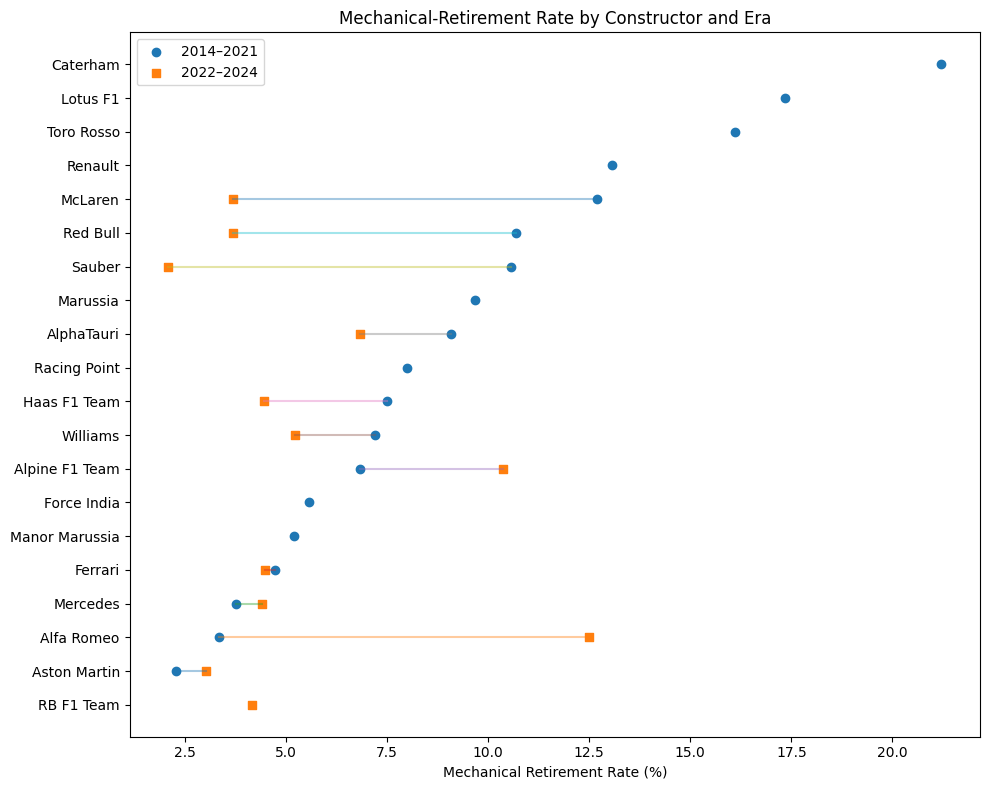

In [37]:
strict_plot = constructor_rates.pivot(index="constructor_name", columns="era", values="strict_rate")
strict_plot = strict_plot.sort_values("2014–2021", ascending=True, na_position="first")

y = np.arange(len(strict_plot))
fig, ax = plt.subplots(figsize=(10,8))

for i,(_,row) in enumerate(strict_plot.iterrows()):
    if row.notna().all(): ax.plot([row["2014–2021"],row["2022–2024"]],[i,i],alpha=.4)

ax.scatter(strict_plot["2014–2021"], y, label="2014–2021", marker="o")
ax.scatter(strict_plot["2022–2024"], y, label="2022–2024", marker="s")
ax.set_yticks(y)
ax.set_yticklabels(strict_plot.index)
ax.set_xlabel("Mechanical Retirement Rate (%)")
ax.set_title("Mechanical-Retirement Rate by Constructor and Era")
ax.legend()
plt.tight_layout()
plt.show()

**Grain:** one constructor car entry in one race. Rates use car starts rather than raw failure
counts because the two comparison periods contain different numbers of races.

**Missing/ambiguous data:** clear component failures form the strict mechanical definition.
Ambiguous statuses such as `Retired`, `Wheel`, `Puncture` and bodywork-related failures are
added only in the sensitivity analysis. The strict and inclusive rankings are compared to show
how dependent the result is on this judgment.

**Pre-race cutoff:** status is only known after the race, so it would be leakage in the prediction
model. It is valid here because this question is a retrospective historical analysis rather than
a predictive feature.

Constructor names follow the dataset's `constructorId`; renamed teams are therefore treated
as separate constructors.

### Question 3 Answer

After excluding drivers who withdrew before taking the race start, the overall strict
mechanical-retirement rate fell from approximately 8.85% of car starts in 2014–2021 to
5.40% in 2022–2024.

Among all constructors, Caterham recorded the highest 2014–2021 strict rate at 21.21%, but
this result is based on only 33 car starts. Restricting the main ranking to constructors with at
least 60 car starts, Lotus F1 ranked highest at 17.33%, followed by Toro Rosso at 16.12%
and Renault at 13.07%.

In 2022–2024, Alfa Romeo had the highest strict mechanical-retirement rate at 12.50%,
followed by Alpine at 10.37% and AlphaTauri at 6.82%.

The strict and inclusive rankings were very similar in 2014–2021, showing that the earlier
ranking is robust to the treatment of ambiguous statuses. The 2022–2024 ranking was less
stable, so conclusions about constructors lower in that ranking should be interpreted more
cautiously.

Constructor identities follow the dataset's `constructorId`, so renamed teams are treated as
separate constructors.

# 8. Feature Engineering & Selection

Features are restricted to information available after qualifying and before the race starts.

Four feature groups are constructed:

1. **Grid:** actual starting position and grid-zero flag.
2. **Qualifying:** qualifying position, Q1 pace gap, Q2/Q3 availability and grid change from qualifying.
3. **Standings:** driver and constructor championship position and points share relative to the championship leader before the race.
4. **Form:** recent driver performance, recent constructor performance and driver experience.

Features are created on the complete historical dataset before restricting modeling to 2003 onward.
This allows early-2003 form features to use races from previous seasons.

Raw championship points are not used directly because Formula 1 scoring systems changed historically
and cumulative point totals naturally increase through a season. Instead, each driver's and
constructor's points are expressed as a share of the championship leader's points before the race,
making the feature more comparable across seasons and rounds.

`q1_gap_pct` compares each driver's Q1 time with the fastest Q1 time from the same race. Q1 has the
broadest per-driver qualifying coverage and avoids comparing lap times set in different elimination
stages or session conditions.

Driver and constructor IDs are not used as predictors because this would encourage memorization
of identities rather than transferable performance patterns. Current-race post-race variables and
sprint results are also excluded.

In [38]:
# ============================================================
# 8.1 GRID AND QUALIFYING FEATURES
# ============================================================

feature_df = model_df.copy()

qual_feat = clean_tables["qualifying"][["raceId","driverId","position","q1_s","q2_recorded","q3_recorded"]].copy()
qual_feat = qual_feat.rename(columns={"position":"qualifying_position"})
qual_feat["q1_best_s"] = qual_feat.groupby("raceId")["q1_s"].transform("min")
qual_feat["q1_gap_pct"] = (qual_feat["q1_s"]/qual_feat["q1_best_s"]-1)*100

feature_df = feature_df.merge(qual_feat[["raceId","driverId","qualifying_position","q1_gap_pct","q2_recorded","q3_recorded"]], on=["raceId","driverId"], how="left", validate="one_to_one")

feature_df["qualifying_missing"] = feature_df["qualifying_position"].isna().astype(int)
feature_df["qual_time_missing"] = feature_df["q1_gap_pct"].isna().astype(int)
feature_df["q2_recorded"] = feature_df["q2_recorded"].fillna(0).astype(int)
feature_df["q3_recorded"] = feature_df["q3_recorded"].fillna(0).astype(int)
feature_df["grid_penalty"] = np.where(feature_df["grid"]>0, feature_df["grid"]-feature_df["qualifying_position"], np.nan)

print("Qualifying rows missing:", feature_df["qualifying_missing"].sum())
print("Q1 pace values missing:", feature_df["qual_time_missing"].sum())
display(feature_df[["year","grid","grid_zero_start","qualifying_position","q1_gap_pct","q2_recorded","q3_recorded","grid_penalty"]].head())

Qualifying rows missing: 14194
Q1 pace values missing: 14349


,year,grid,grid_zero_start,qualifying_position,q1_gap_pct,q2_recorded,q3_recorded,grid_penalty
0,1950,1,0,NaN,NaN,0,0,NaN
1,1950,2,0,NaN,NaN,0,0,NaN
2,1950,4,0,NaN,NaN,0,0,NaN
3,1950,6,0,NaN,NaN,0,0,NaN
4,1950,9,0,NaN,NaN,0,0,NaN


In [39]:
# ============================================================
# 8.2 PRE-RACE STANDINGS FEATURES
# ============================================================

race_prev = clean_tables["races"][["raceId","year","round"]].sort_values(["year","round"]).copy()
race_prev["prev_raceId"] = race_prev.groupby("year")["raceId"].shift(1)
feature_df = feature_df.merge(race_prev[["raceId","prev_raceId"]], on="raceId", how="left", validate="many_to_one")

driver_stand = clean_tables["driver_standings"][["raceId","driverId","points","position"]].copy()
driver_stand = driver_stand.rename(columns={"raceId":"prev_raceId","points":"driver_points_before","position":"driver_position_before"})
driver_stand["driver_leader_points"] = driver_stand.groupby("prev_raceId")["driver_points_before"].transform("max")
driver_stand["driver_points_share"] = np.where(driver_stand["driver_leader_points"]>0, driver_stand["driver_points_before"]/driver_stand["driver_leader_points"], np.nan)

constructor_stand = clean_tables["constructor_standings"][["raceId","constructorId","points","position"]].copy()
constructor_stand = constructor_stand.rename(columns={"raceId":"prev_raceId","points":"constructor_points_before","position":"constructor_position_before"})
constructor_stand["constructor_leader_points"] = constructor_stand.groupby("prev_raceId")["constructor_points_before"].transform("max")
constructor_stand["constructor_points_share"] = np.where(constructor_stand["constructor_leader_points"]>0, constructor_stand["constructor_points_before"]/constructor_stand["constructor_leader_points"], np.nan)

feature_df = feature_df.merge(driver_stand, on=["prev_raceId","driverId"], how="left", validate="many_to_one")
feature_df = feature_df.merge(constructor_stand, on=["prev_raceId","constructorId"], how="left", validate="many_to_one")

feature_df["driver_standing_missing"] = feature_df["driver_position_before"].isna().astype(int)
feature_df["constructor_standing_missing"] = feature_df["constructor_position_before"].isna().astype(int)

assert feature_df["driver_points_share"].dropna().between(0,1).all()
assert feature_df["constructor_points_share"].dropna().between(0,1).all()

display(feature_df[["year","round","driver_position_before","driver_points_share",
                    "constructor_position_before","constructor_points_share"]].head(25))

,year,round,driver_position_before,driver_points_share,constructor_position_before,constructor_points_share
0,1950,1,NaN,NaN,NaN,NaN
1,1950,1,NaN,NaN,NaN,NaN
2,1950,1,NaN,NaN,NaN,NaN
3,1950,1,NaN,NaN,NaN,NaN
4,1950,1,NaN,NaN,NaN,NaN
5,1950,1,NaN,NaN,NaN,NaN
6,1950,1,NaN,NaN,NaN,NaN
7,1950,1,NaN,NaN,NaN,NaN
8,1950,1,NaN,NaN,NaN,NaN
9,1950,1,NaN,NaN,NaN,NaN


In [40]:
# ============================================================
# 8.3 PAST-RACE FORM FEATURES
# ============================================================

feature_df = feature_df.sort_values(["race_order","driverId"]).copy()

form_rows = []
for driver_id, g in feature_df.groupby("driverId", sort=False):
    podium_history, finish_history, starts = [], [], 0
    for idx,row in g.sort_values("race_order").iterrows():
        form_rows.append((idx, np.mean(podium_history[-5:]) if podium_history else np.nan, np.mean(finish_history[-5:]) if finish_history else np.nan, starts))
        if row["positionText"] != "W":
            podium_history.append(row["podium"])
            finish_history.append(row["positionOrder"])
            starts += 1

driver_form = pd.DataFrame(form_rows, columns=["idx","driver_podium_last5","driver_avg_finish_last5","career_starts"]).set_index("idx")
feature_df = feature_df.join(driver_form)

constructor_history = model_df.copy()
constructor_history["podium_actual"] = constructor_history["podium"].where(constructor_history["positionText"]!="W")
constructor_history = (constructor_history.groupby(["constructorId","raceId","race_order"], as_index=False)
                       .agg(constructor_podium_rate=("podium_actual","mean"))
                       .sort_values(["constructorId","race_order"]))
constructor_history["constructor_podium_last5"] = constructor_history.groupby("constructorId")["constructor_podium_rate"].transform(lambda s: s.shift(1).rolling(5,min_periods=1).mean())

feature_df = feature_df.merge(constructor_history[["raceId","constructorId","constructor_podium_last5"]], on=["raceId","constructorId"], how="left", validate="many_to_one")

feature_df["driver_form_missing"] = feature_df["driver_podium_last5"].isna().astype(int)
feature_df["constructor_form_missing"] = feature_df["constructor_podium_last5"].isna().astype(int)
feature_df = feature_df.sort_values(["race_order","positionOrder"]).reset_index(drop=True)

display(feature_df[["year","driver_podium_last5","driver_avg_finish_last5","constructor_podium_last5","career_starts"]].head(20))

,year,driver_podium_last5,driver_avg_finish_last5,constructor_podium_last5,career_starts
0,1950,NaN,NaN,NaN,0
1,1950,NaN,NaN,NaN,0
2,1950,NaN,NaN,NaN,0
3,1950,NaN,NaN,NaN,0
4,1950,NaN,NaN,NaN,0
5,1950,NaN,NaN,NaN,0
6,1950,NaN,NaN,NaN,0
7,1950,NaN,NaN,NaN,0
8,1950,NaN,NaN,NaN,0
9,1950,NaN,NaN,NaN,0


In [41]:
# ============================================================
# 8.4 FEATURE GROUPS
# ============================================================

FEATURE_GROUPS = {
    "grid":["grid","grid_zero_start"],
    "qualifying":["qualifying_position","q1_gap_pct","q2_recorded","q3_recorded","grid_penalty","qualifying_missing","qual_time_missing"],
    "standings":["driver_position_before","driver_points_share","constructor_position_before","constructor_points_share",
                 "driver_standing_missing","constructor_standing_missing"],
    "form":["driver_podium_last5","driver_avg_finish_last5","constructor_podium_last5","career_starts",
            "driver_form_missing","constructor_form_missing"]
}

FEATURES = sum(FEATURE_GROUPS.values(), [])

for group,features in FEATURE_GROUPS.items():
    print(f"{group}: {features}")

forbidden = {"positionOrder","position","points","laps","status","statusId","milliseconds","fastestLap",
             "fastestLapTime","fastestLapSpeed","driver_points_before","constructor_points_before"}
assert forbidden.isdisjoint(FEATURES)

print("\nTotal selected features:", len(FEATURES))

grid: ['grid', 'grid_zero_start']
qualifying: ['qualifying_position', 'q1_gap_pct', 'q2_recorded', 'q3_recorded', 'grid_penalty', 'qualifying_missing', 'qual_time_missing']
standings: ['driver_position_before', 'driver_points_share', 'constructor_position_before', 'constructor_points_share', 'driver_standing_missing', 'constructor_standing_missing']
form: ['driver_podium_last5', 'driver_avg_finish_last5', 'constructor_podium_last5', 'career_starts', 'driver_form_missing', 'constructor_form_missing']

Total selected features: 21


In [42]:
# ============================================================
# 8.5 LEAKAGE CHECK
# ============================================================

check_pool = feature_df[(feature_df["year"]>=2003) & (feature_df["driver_podium_last5"]>0)].copy()
check_rows = check_pool.sample(n=min(300,len(check_pool)), random_state=42)

driver_history = {d:g[g["positionText"]!="W"].sort_values("race_order")
                  for d,g in model_df.groupby("driverId")}

for _,row in check_rows.iterrows():
    past = driver_history[row["driverId"]]
    past = past[past["race_order"]<row["race_order"]].tail(5)
    expected = past["podium"].mean()
    assert np.isclose(row["driver_podium_last5"], expected)

constructor_history_check = model_df[model_df["positionText"]!="W"].copy()
constructor_history_check = (constructor_history_check.groupby(["constructorId","raceId","race_order"],as_index=False)
                             .agg(podium_rate=("podium","mean")))

constructor_checks = feature_df[(feature_df["year"]>=2003) & feature_df["constructor_podium_last5"].notna()]
constructor_checks = constructor_checks.sample(n=min(300,len(constructor_checks)), random_state=42)

for _,row in constructor_checks.iterrows():
    past = constructor_history_check[(constructor_history_check["constructorId"]==row["constructorId"]) &
                                     (constructor_history_check["race_order"]<row["race_order"])]
    expected = past.sort_values("race_order").tail(5)["podium_rate"].mean()
    assert np.isclose(row["constructor_podium_last5"], expected)

example = check_rows.iloc[0]
print(f"Checked {len(check_rows)} non-zero driver-form rows.")
print(f"Checked {len(constructor_checks)} constructor-form rows.")
print(f"Example stored driver form: {example['driver_podium_last5']:.3f}")
print("All rolling-form leakage checks passed.")

Checked 300 non-zero driver-form rows.
Checked 300 constructor-form rows.
Example stored driver form: 0.400
All rolling-form leakage checks passed.


In [43]:
# ============================================================
# 8.6 TEMPORAL TRAIN / VALIDATION / TEST SPLIT
# ============================================================

ml_df = feature_df[feature_df["year"].between(2003,2024)].copy()

train_df = ml_df[ml_df["year"].between(2003,2019)].copy()
val_df = ml_df[ml_df["year"].between(2020,2021)].copy()
test_df = ml_df[ml_df["year"].between(2022,2024)].copy()

split_summary = pd.DataFrame({
    "Set":["Train","Validation","Test"],
    "Seasons":["2003–2019","2020–2021","2022–2024"],
    "Rows":[len(train_df),len(val_df),len(test_df)],
    "Podium rate (%)":[train_df["podium"].mean()*100,val_df["podium"].mean()*100,test_df["podium"].mean()*100]
})
display(split_summary)

assert set(train_df["raceId"]).isdisjoint(val_df["raceId"])
assert set(train_df["raceId"]).isdisjoint(test_df["raceId"])
assert set(val_df["raceId"]).isdisjoint(test_df["raceId"])

print("Race overlap between splits: 0")

,Set,Seasons,Rows,Podium rate (%)
0,Train,2003–2019,6800,14.161765
1,Validation,2020–2021,778,15.038560
2,Test,2022–2024,1353,15.077605


Race overlap between splits: 0


### Split Justification

The dataset is split chronologically rather than randomly:

- **Training:** 2003–2019
- **Validation:** 2020–2021
- **Test:** 2022–2024

A temporal split reflects the real prediction task: models are trained using historical races and
then applied to future races. A random row split could place drivers from the same season, or even
the same race environment, across training and evaluation sets, allowing the model to benefit from
information about a season that would not have been available prospectively. Keeping complete
seasons together also ensures that all drivers from the same race remain in the same split.

Training begins in 2003 because the pre-cleaning qualifying-coverage analysis showed reliable
qualifying coverage from that season onward. Earlier seasons contain substantial missing or
incompatible qualifying information.

The validation period is relatively small and includes the shortened 2020 COVID season. The test
period begins in 2022, which also corresponds to a major Formula 1 technical-regulation change.
Therefore, the test set represents a genuine era shift and is intentionally challenging.

In [44]:
# ============================================================
# 8.6.1 TRAIN-FITTED Q1 GAP CAP
# ============================================================

Q1_GAP_CAP = train_df["q1_gap_pct"].quantile(0.99)

print(f"Training 99th-percentile Q1 gap: {Q1_GAP_CAP:.3f}%")
print(f"Training maximum before cap: {train_df['q1_gap_pct'].max():.3f}%")

for df in [train_df,val_df,test_df]:
    df["q1_gap_pct"] = df["q1_gap_pct"].clip(upper=Q1_GAP_CAP)

print(f"Training maximum after cap: {train_df['q1_gap_pct'].max():.3f}%")

Training 99th-percentile Q1 gap: 7.596%
Training maximum before cap: 33.285%
Training maximum after cap: 7.596%


In [45]:
# ============================================================
# 8.6.2 FEATURE MISSINGNESS BY SPLIT
# ============================================================

missing_by_split = []

for name, df in {"Train":train_df, "Validation":val_df, "Test":test_df}.items():
    missing_by_split.append({
        "Set":name,
        "Rows":len(df),
        "Qualifying position missing (%)":df["qualifying_position"].isna().mean()*100,
        "Q1 pace missing (%)":df["q1_gap_pct"].isna().mean()*100,
        "Driver standings missing (%)":df["driver_position_before"].isna().mean()*100,
        "Constructor standings missing (%)":df["constructor_position_before"].isna().mean()*100,
        "Driver form missing (%)":df["driver_podium_last5"].isna().mean()*100,
        "Constructor form missing (%)":df["constructor_podium_last5"].isna().mean()*100
    })

missing_by_split = pd.DataFrame(missing_by_split)
display(missing_by_split.round(2))

,Set,Rows,Qualifying position missing (%),Q1 pace missing (%),Driver standings missing (%),Constructor standings missing (%),Driver form missing (%),Constructor form missing (%)
0,Train,6800,0.31,1.82,7.13,5.68,1.10,0.51
1,Validation,778,0.13,1.16,5.66,5.14,0.77,0.51
2,Test,1353,0.00,0.96,5.03,4.43,0.59,0.15


Missing feature values are intentionally retained at this stage. They are not filled before the
train/validation/test split because doing so would allow information from validation or test data
to influence preprocessing. Imputation and scaling will therefore be fitted on the training set
only in the modeling pipeline.

,podium_rate_pct
grid_bucket,
P1,80.312500
P2,62.695925
P3,51.562500
P4–5,26.365055
P6–10,7.764559
P11+,1.339660


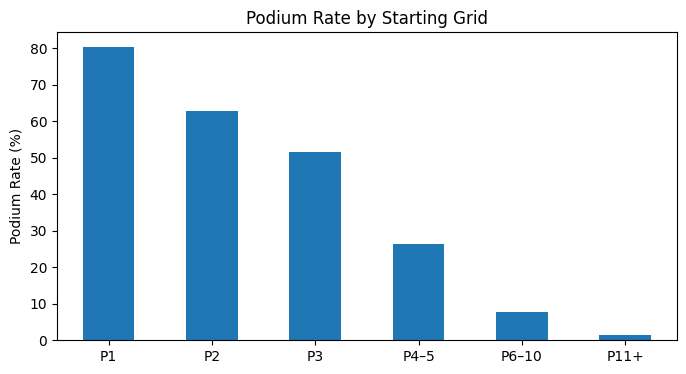

,podium_rate_pct
qual_bucket,
1–3,63.854167
4–6,24.479167
7–10,5.407524
11+,1.283840


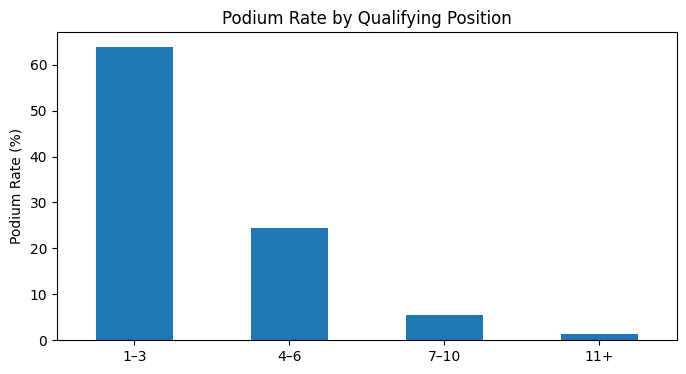

,podium_rate_pct
constructor_standing_bucket,
1st,58.910891
2nd,39.933993
3rd,26.237624
4th–5th,7.431874
6th+,1.890694


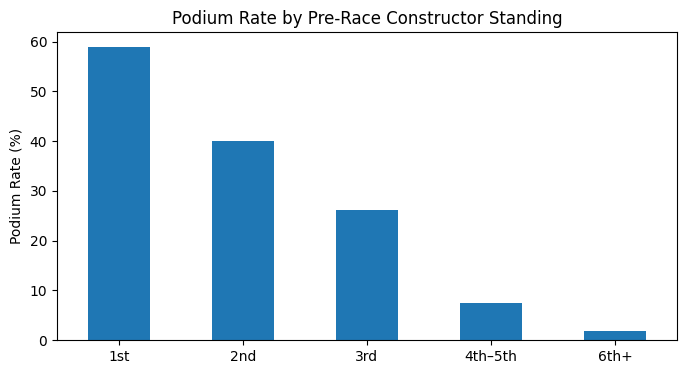

,podium_rate_pct
driver_form_bucket,
0%,2.924610
>0–20%,20.177665
>20–50%,39.919355
>50%,56.848485


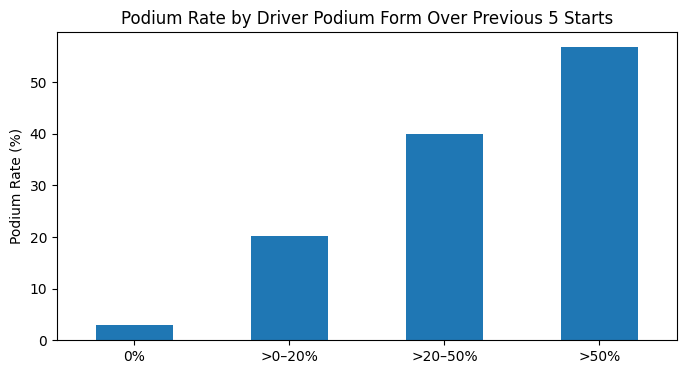

In [46]:
# ============================================================
# 8.7 FEATURE-SELECTION EVIDENCE
# ============================================================

selection_df = train_df.copy()

selection_df["grid_bucket"] = pd.cut(selection_df["grid"], bins=[0,1,2,3,5,10,np.inf], labels=["P1","P2","P3","P4–5","P6–10","P11+"])
selection_df["qual_bucket"] = pd.cut(selection_df["qualifying_position"], bins=[0,3,6,10,np.inf], labels=["1–3","4–6","7–10","11+"])
selection_df["constructor_standing_bucket"] = pd.cut(selection_df["constructor_position_before"], bins=[0,1,2,3,5,np.inf], labels=["1st","2nd","3rd","4th–5th","6th+"])
selection_df["driver_form_bucket"] = pd.cut(selection_df["driver_podium_last5"], bins=[-0.001,0,0.2,0.5,1], labels=["0%",">0–20%",">20–50%",">50%"], include_lowest=True)

def plot_rate(column,title):
    rates = selection_df.groupby(column, observed=True)["podium"].mean()*100
    display(rates.rename("podium_rate_pct").to_frame())
    rates.plot(kind="bar", figsize=(8,4))
    plt.title(title)
    plt.xlabel("")
    plt.ylabel("Podium Rate (%)")
    plt.xticks(rotation=0)
    plt.show()

plot_rate("grid_bucket","Podium Rate by Starting Grid")
plot_rate("qual_bucket","Podium Rate by Qualifying Position")
plot_rate("constructor_standing_bucket","Podium Rate by Pre-Race Constructor Standing")
plot_rate("driver_form_bucket","Podium Rate by Driver Podium Form Over Previous 5 Starts")

,correlation_with_podium
driver_points_share,0.565100
constructor_points_share,0.556461
driver_podium_last5,0.548671
constructor_podium_last5,0.548544
qualifying_position,-0.492147
grid,-0.484963
driver_position_before,-0.465817
driver_avg_finish_last5,-0.462024
constructor_position_before,-0.441179
q3_recorded,0.346498


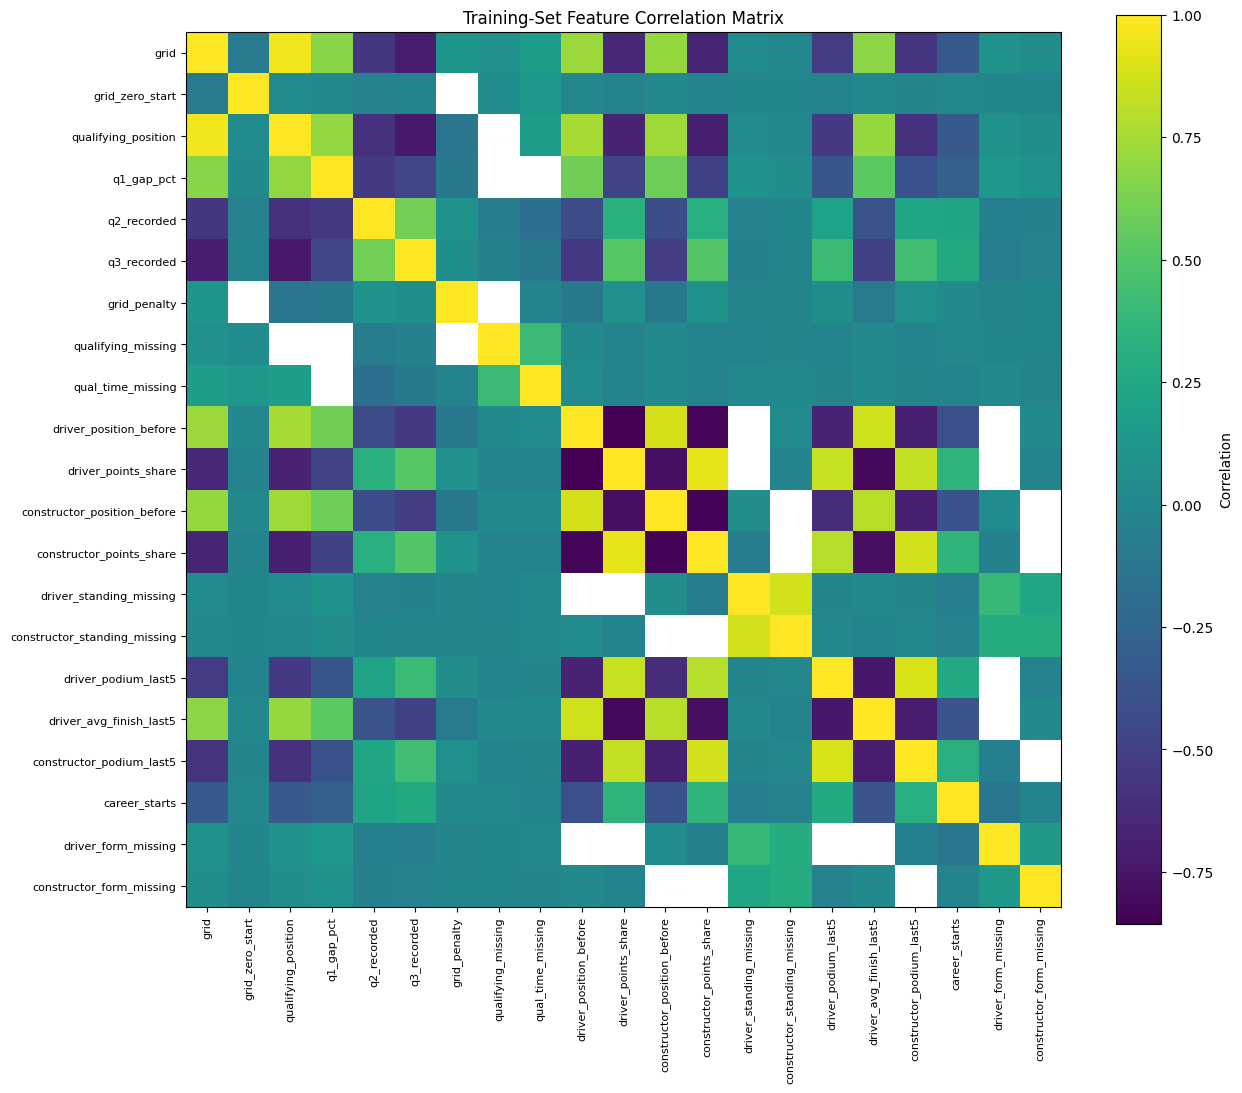

In [47]:
# ============================================================
# 8.8 FEATURE CORRELATIONS
# ============================================================

target_corr = train_df[FEATURES+["podium"]].corr(numeric_only=True)["podium"].drop("podium").sort_values(key=abs, ascending=False)
display(target_corr.rename("correlation_with_podium").to_frame())

corr = train_df[FEATURES].corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(13,11))
im = ax.imshow(corr)
ax.set_xticks(range(len(corr.columns)))
ax.set_yticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=90, fontsize=8)
ax.set_yticklabels(corr.columns, fontsize=8)
fig.colorbar(im, ax=ax, label="Correlation")
ax.set_title("Training-Set Feature Correlation Matrix")
plt.tight_layout()
plt.show()

### Feature Selection Decision

All four feature groups are retained for the initial models.

Grid position shows the strongest direct relationship with podium probability. Qualifying features
provide additional information about pre-race pace and changes between qualifying and the final
grid. Pre-race standings capture accumulated driver and constructor strength, while rolling form
features capture recent performance and experience using past races only.

Some features, especially grid and qualifying position, are strongly correlated. They are retained
at this stage because correlation alone does not establish redundancy.

`grid_penalty` has very weak linear correlation with podium outcome (approximately 0.01), but it is
retained because its effect may be contextual or non-linear; for example, a driver qualifying near
the front and being moved many places backward represents information not captured by the raw
correlation coefficient. The later feature-group ablation will determine whether qualifying features
add predictive value beyond grid position.

Driver and constructor IDs are excluded from the predictor set, as are variables that become
known only during or after the current race.

# 9. Data Pre-processing

The selected features contain different numerical scales and some legitimate missing values.

For Logistic Regression and the neural network:

- missing numerical values are imputed using the median of the **training set only**;
- features are standardized using the mean and standard deviation of the **training set only**;
- the fitted preprocessing objects are then applied unchanged to validation and test data.

The existing missing-value indicator features are retained so the models can distinguish an
imputed value from a genuinely observed value.

Tree-based models will later use the imputed values without requiring standardization.

In [48]:
# ============================================================
# 9.1 PREPARE MODEL INPUTS
# ============================================================

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score, precision_score, recall_score

X_train = train_df[FEATURES].copy()
X_val = val_df[FEATURES].copy()
X_test = test_df[FEATURES].copy()

y_train = train_df["podium"].astype(int).copy()
y_val = val_df["podium"].astype(int).copy()
y_test = test_df["podium"].astype(int).copy()

print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)
print("\nMissing values before preprocessing:")
print("Train:", X_train.isna().sum().sum())
print("Validation:", X_val.isna().sum().sum())
print("Test:", X_test.isna().sum().sum())

Train: (6800, 21) (6800,)
Validation: (778, 21) (778,)
Test: (1353, 21) (1353,)

Missing values before preprocessing:
Train: 2112
Validation: 211
Test: 324


In [49]:
# ============================================================
# 9.2 TRAIN-ONLY IMPUTATION AND SCALING
# ============================================================

imputer = SimpleImputer(strategy="median")
scaler = StandardScaler()

X_train_imp = imputer.fit_transform(X_train)
X_val_imp = imputer.transform(X_val)
X_test_imp = imputer.transform(X_test)

X_train_scaled = scaler.fit_transform(X_train_imp)
X_val_scaled = scaler.transform(X_val_imp)
X_test_scaled = scaler.transform(X_test_imp)

assert not np.isnan(X_train_imp).any()
assert not np.isnan(X_val_imp).any()
assert not np.isnan(X_test_imp).any()
assert not np.isnan(X_train_scaled).any()
assert not np.isnan(X_val_scaled).any()
assert not np.isnan(X_test_scaled).any()

print("Remaining missing values after imputation: 0")
print("Training scaled mean:", round(X_train_scaled.mean(),6))
print("Training scaled std:", round(X_train_scaled.std(),6))

Remaining missing values after imputation: 0
Training scaled mean: 0.0
Training scaled std: 1.0


In [50]:
# ============================================================
# 9.3 EFFECT OF PREPROCESSING
# ============================================================

processed_train = pd.DataFrame(X_train_scaled, columns=FEATURES, index=X_train.index)

check_features = ["grid","qualifying_position","q1_gap_pct","driver_points_share",
                  "constructor_points_share","career_starts"]

before_stats = X_train[check_features].agg(["min","max","mean","std"]).T
after_stats = processed_train[check_features].agg(["min","max","mean","std"]).T

before_stats.columns = ["before_min","before_max","before_mean","before_std"]
after_stats.columns = ["after_min","after_max","after_mean","after_std"]

preprocessing_effect = before_stats.join(after_stats)
display(preprocessing_effect.round(3))

,before_min,before_max,before_mean,before_std,after_min,after_max,after_mean,after_std
grid,0.0,24.000,11.134,6.246,-1.783,2.060,-0.0,1.0
qualifying_position,1.0,24.000,11.160,6.219,-1.636,2.068,-0.0,1.0
q1_gap_pct,0.0,7.596,1.737,1.525,-1.145,3.880,-0.0,1.0
driver_points_share,0.0,1.000,0.255,0.303,-0.833,2.564,0.0,1.0
constructor_points_share,0.0,1.000,0.300,0.336,-0.889,2.161,0.0,1.0
career_starts,0.0,321.000,92.898,79.181,-1.173,2.881,0.0,1.0


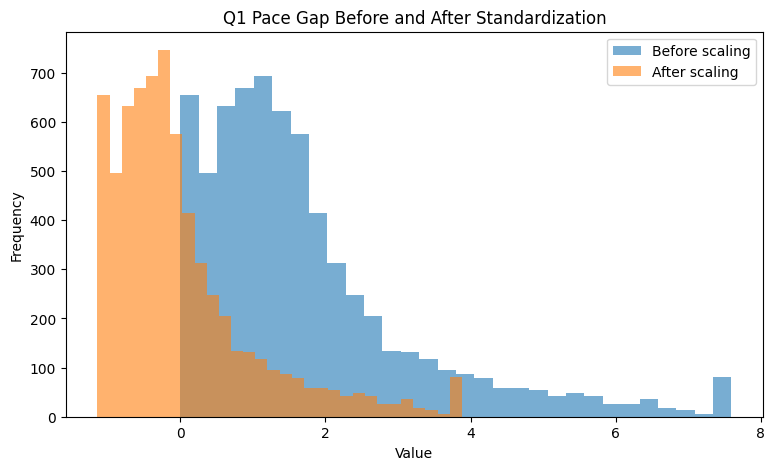

In [51]:
fig, ax = plt.subplots(figsize=(9,5))

ax.hist(X_train["q1_gap_pct"].dropna(), bins=30, alpha=.6, label="Before scaling")
ax.hist(processed_train["q1_gap_pct"], bins=30, alpha=.6, label="After scaling")

ax.set_title("Q1 Pace Gap Before and After Standardization")
ax.set_xlabel("Value")
ax.set_ylabel("Frequency")
ax.legend()

plt.show()

### Preprocessing Effect

Median imputation removes the remaining missing numerical values without using validation or
test information. Standardization changes feature scale but not observation order or underlying
relationships: training-set features are transformed to approximately zero mean and unit variance.

This is particularly important for Logistic Regression and the neural network because features such
as `career_starts`, grid position and points share originally operate on very different numerical
ranges.

In [52]:
# ============================================================
# 9.4 PREPROCESSING-ORDER EXPERIMENTS
# ============================================================

def preprocessing_score(Xtr,Xv,ytr,yv):
    model = LogisticRegression(max_iter=2000,random_state=42)
    model.fit(Xtr,ytr)
    p = model.predict_proba(Xv)[:,1]
    return roc_auc_score(yv,p),average_precision_score(yv,p)

correct_roc,correct_pr = preprocessing_score(X_train_scaled,X_val_scaled,y_train,y_val)

X_trainval = pd.concat([X_train,X_val],axis=0)

# Experiment 1: LEAKY scaler fitted before the train/validation split
trainval_imp = imputer.transform(X_trainval)
leaky_scaler = StandardScaler().fit(trainval_imp)

X_train_leaky_scale = leaky_scaler.transform(imputer.transform(X_train))
X_val_leaky_scale = leaky_scaler.transform(imputer.transform(X_val))
scale_roc,scale_pr = preprocessing_score(X_train_leaky_scale,X_val_leaky_scale,y_train,y_val)

# Experiment 2: LEAKY imputer fitted before the train/validation split
leaky_imputer = SimpleImputer(strategy="median").fit(X_trainval)

X_train_leaky_imp = leaky_imputer.transform(X_train)
X_val_leaky_imp = leaky_imputer.transform(X_val)

imp_scaler = StandardScaler().fit(X_train_leaky_imp)
X_train_leaky_imp = imp_scaler.transform(X_train_leaky_imp)
X_val_leaky_imp = imp_scaler.transform(X_val_leaky_imp)
imp_roc,imp_pr = preprocessing_score(X_train_leaky_imp,X_val_leaky_imp,y_train,y_val)

preprocessing_experiments = pd.DataFrame({
    "Method":["Correct: preprocessing fitted on train only",
              "Leaky: scaler fitted before split",
              "Leaky: imputer fitted before split"],
    "Validation ROC-AUC":[correct_roc,scale_roc,imp_roc],
    "Validation PR-AUC":[correct_pr,scale_pr,imp_pr]
})

display(preprocessing_experiments.round(4))

,Method,Validation ROC-AUC,Validation PR-AUC
0,Correct: preprocessing fitted on train only,0.9316,0.7315
1,Leaky: scaler fitted before split,0.9314,0.7307
2,Leaky: imputer fitted before split,0.9315,0.7310


### Preprocessing Experiment Findings

All missing values were removed using median imputation fitted only on the training data, and
standardization transformed the training features to approximately zero mean and unit variance.

The correct and deliberately leaky preprocessing variants produced practically identical validation
performance, with PR-AUC differences below 0.001. This indicates that preprocessing leakage has
little numerical effect in this particular dataset.

However, fitting either the scaler or imputer before the train/validation split is still
methodologically invalid because validation information influences transformations applied to
training data.

Therefore, all reported models use preprocessing fitted exclusively on the training set.

# 10. Prediction Models

Three model families will be compared using the same rows and feature set:

1. Logistic Regression — interpretable statistical baseline.
2. Gradient Boosting — non-linear statistical machine-learning model.
3. Shallow Feed-Forward Neural Network — 1–2 hidden layers.

Model and threshold selection use only training and validation data. Test labels and test
performance are not used until the final frozen configurations are evaluated.

## 10.1 Logistic Regression Baseline

Logistic Regression models the log-odds of a podium finish as a weighted linear combination of
the input features.

It provides a simple and interpretable baseline against which more complex models can be compared.

Because podium finishes are the minority class, PR-AUC is treated as the primary model-selection
metric, with ROC-AUC as a secondary ranking metric.

Five metrics are reported for every model: ROC-AUC, PR-AUC and F1 as required by the brief,
plus precision and recall because F1 is the harmonic mean of precision and recall and should be
interpreted alongside both components.

Classification thresholds are selected using validation data only.

In [53]:
# ============================================================
# 10.1.1 LOGISTIC REGRESSION BASELINE
# ============================================================

logreg = LogisticRegression(max_iter=3000, random_state=42)
logreg.fit(X_train_scaled, y_train)

train_prob = logreg.predict_proba(X_train_scaled)[:,1]
val_prob = logreg.predict_proba(X_val_scaled)[:,1]

print("Training ROC-AUC:", round(roc_auc_score(y_train,train_prob),4))
print("Training PR-AUC:", round(average_precision_score(y_train,train_prob),4))
print("Validation ROC-AUC:", round(roc_auc_score(y_val,val_prob),4))
print("Validation PR-AUC:", round(average_precision_score(y_val,val_prob),4))

Training ROC-AUC: 0.9296
Training PR-AUC: 0.689
Validation ROC-AUC: 0.9316
Validation PR-AUC: 0.7315


In [54]:
# ============================================================
# 10.1.2 VALIDATION THRESHOLD SELECTION
# ============================================================

thresholds = np.arange(0.05,0.96,0.01)
threshold_rows = []

for t in thresholds:
    pred = (val_prob>=t).astype(int)
    threshold_rows.append({
        "threshold":t,
        "f1":f1_score(y_val,pred,zero_division=0),
        "precision":precision_score(y_val,pred,zero_division=0),
        "recall":recall_score(y_val,pred,zero_division=0)
    })

threshold_results = pd.DataFrame(threshold_rows)
best_row = threshold_results.loc[threshold_results["f1"].idxmax()]
best_threshold = best_row["threshold"]

display(best_row.to_frame().T.round(4))
print(f"Selected validation threshold: {best_threshold:.2f}")

,threshold,f1,precision,recall
39,0.44,0.6953,0.6983,0.6923


Selected validation threshold: 0.44


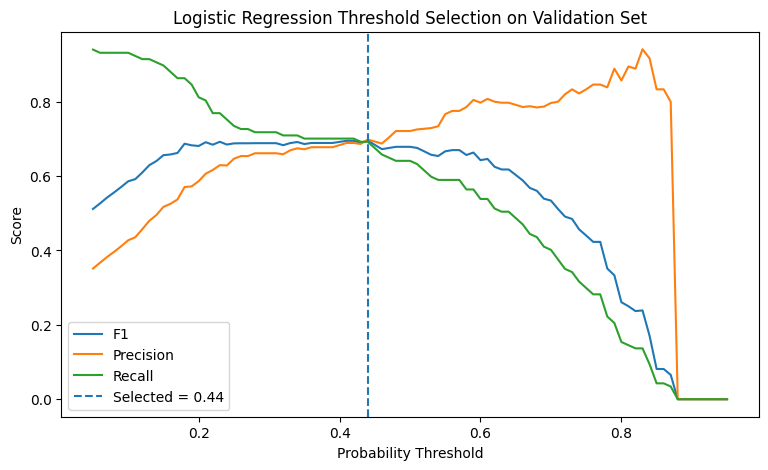

In [55]:
plt.figure(figsize=(9,5))
plt.plot(threshold_results["threshold"],threshold_results["f1"],label="F1")
plt.plot(threshold_results["threshold"],threshold_results["precision"],label="Precision")
plt.plot(threshold_results["threshold"],threshold_results["recall"],label="Recall")
plt.axvline(best_threshold,linestyle="--",label=f"Selected = {best_threshold:.2f}")

plt.title("Logistic Regression Threshold Selection on Validation Set")
plt.xlabel("Probability Threshold")
plt.ylabel("Score")
plt.legend()
plt.show()

In [56]:
# ============================================================
# 10.1.3 MODEL EVALUATION FUNCTION
# ============================================================

def evaluate_predictions(y_true,prob,threshold):
    pred = (prob>=threshold).astype(int)
    return {
        "ROC-AUC":roc_auc_score(y_true,prob),
        "PR-AUC":average_precision_score(y_true,prob),
        "F1":f1_score(y_true,pred,zero_division=0),
        "Precision":precision_score(y_true,pred,zero_division=0),
        "Recall":recall_score(y_true,pred,zero_division=0)
    }

logreg_train_metrics = evaluate_predictions(y_train,train_prob,best_threshold)
logreg_val_metrics = evaluate_predictions(y_val,val_prob,best_threshold)

logreg_results = pd.DataFrame([logreg_train_metrics,logreg_val_metrics],index=["Train","Validation"])
display(logreg_results.round(4))

,ROC-AUC,PR-AUC,F1,Precision,Recall
Train,0.9296,0.6890,0.6523,0.6589,0.6459
Validation,0.9316,0.7315,0.6953,0.6983,0.6923


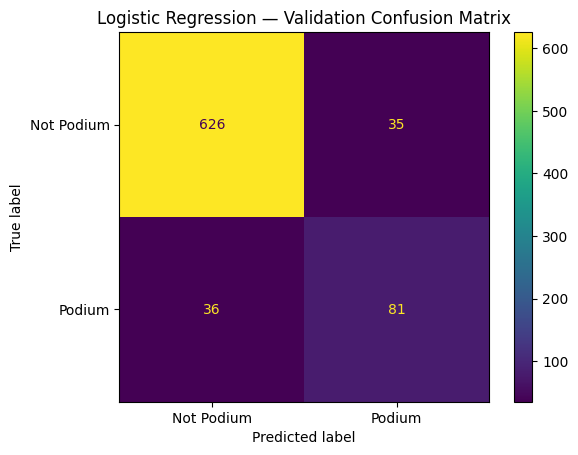

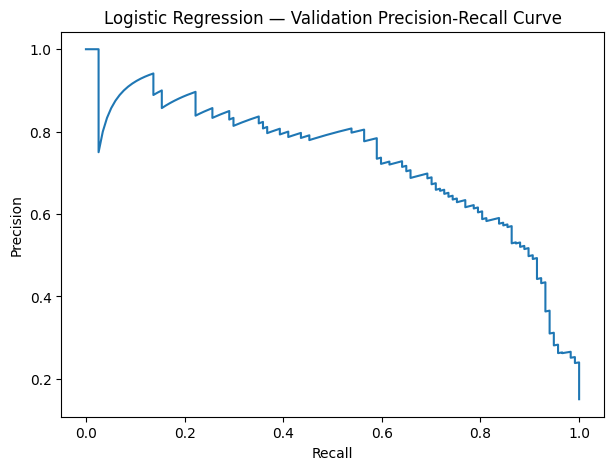

In [57]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, precision_recall_curve

val_pred = (val_prob>=best_threshold).astype(int)

cm = confusion_matrix(y_val,val_pred)
ConfusionMatrixDisplay(cm,display_labels=["Not Podium","Podium"]).plot()
plt.title("Logistic Regression — Validation Confusion Matrix")
plt.show()

precision_curve,recall_curve,_ = precision_recall_curve(y_val,val_prob)

plt.figure(figsize=(7,5))
plt.plot(recall_curve,precision_curve)
plt.title("Logistic Regression — Validation Precision-Recall Curve")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.show()

### Logistic Regression Limitations

Logistic Regression assumes that each numerical feature has an approximately linear relationship
with the log-odds of a podium finish. Formula 1 performance contains strong interactions and
non-linear effects; for example, the difference between grid positions 1 and 2 may matter more than
the difference between positions 15 and 16.

The model can also be affected by correlated predictors such as grid and qualifying position.
Regularization reduces this problem but does not remove the linearity assumption.

For these reasons, Logistic Regression is used as the baseline rather than assumed to be the final
best-performing model.

### Logistic Regression Results

Logistic Regression achieved a training ROC-AUC of 0.9296 and PR-AUC of 0.6890, compared
with a validation ROC-AUC of 0.9316 and PR-AUC of 0.7315.

The similar training and validation performance indicates that the baseline generalizes well and
does not show evidence of overfitting.

Using the validation set only, the F1-optimal classification threshold was 0.44. At this threshold,
validation F1 was 0.6953, with precision of 0.6983 and recall of 0.6923. The similar precision and
recall values indicate a balanced trade-off between false podium predictions and missed podiums.

PR-AUC is treated as the primary ranking metric because podium finishes form the minority class,
while ROC-AUC is reported as a secondary metric.

## 10.2 Gradient Boosting

Gradient Boosting builds a sequence of shallow decision trees, where each new tree focuses on
correcting errors made by the previous trees.

Unlike Logistic Regression, it can naturally learn non-linear relationships and interactions between
features. This is useful for Formula 1 because the effect of variables such as grid position,
qualifying pace and constructor form is unlikely to be purely linear.

The model uses the same rows and feature set as Logistic Regression. Median imputation is retained,
but scaling is unnecessary for tree-based models.

In [58]:
# ============================================================
# 10.2.1 GRADIENT BOOSTING BASELINE
# ============================================================

from sklearn.ensemble import GradientBoostingClassifier

gb_base = GradientBoostingClassifier(random_state=42)
gb_base.fit(X_train_imp,y_train)

gb_base_train_prob = gb_base.predict_proba(X_train_imp)[:,1]
gb_base_val_prob = gb_base.predict_proba(X_val_imp)[:,1]

print("Training ROC-AUC:", round(roc_auc_score(y_train,gb_base_train_prob),4))
print("Training PR-AUC:", round(average_precision_score(y_train,gb_base_train_prob),4))
print("Validation ROC-AUC:", round(roc_auc_score(y_val,gb_base_val_prob),4))
print("Validation PR-AUC:", round(average_precision_score(y_val,gb_base_val_prob),4))

Training ROC-AUC: 0.9548
Training PR-AUC: 0.8048
Validation ROC-AUC: 0.9229
Validation PR-AUC: 0.6476


In [59]:
# ============================================================
# 10.2.2 GRADIENT BOOSTING HYPERPARAMETER EXPERIMENT
# ============================================================

gb_configs = [
    {"name":"GB1","n_estimators":100,"learning_rate":0.10,"max_depth":2},
    {"name":"GB2","n_estimators":150,"learning_rate":0.05,"max_depth":2},
    {"name":"GB3","n_estimators":100,"learning_rate":0.05,"max_depth":3},
    {"name":"GB4","n_estimators":200,"learning_rate":0.03,"max_depth":2}
]

gb_rows = []
gb_models = {}

for cfg in gb_configs:
    model = GradientBoostingClassifier(n_estimators=cfg["n_estimators"],learning_rate=cfg["learning_rate"],
                                       max_depth=cfg["max_depth"],random_state=42)
    model.fit(X_train_imp,y_train)
    train_p = model.predict_proba(X_train_imp)[:,1]
    val_p = model.predict_proba(X_val_imp)[:,1]

    gb_rows.append({
        "Model":cfg["name"],
        "n_estimators":cfg["n_estimators"],
        "learning_rate":cfg["learning_rate"],
        "max_depth":cfg["max_depth"],
        "Train ROC-AUC":roc_auc_score(y_train,train_p),
        "Train PR-AUC":average_precision_score(y_train,train_p),
        "Validation ROC-AUC":roc_auc_score(y_val,val_p),
        "Validation PR-AUC":average_precision_score(y_val,val_p)
    })
    gb_models[cfg["name"]] = model

gb_experiments = pd.DataFrame(gb_rows)
display(gb_experiments.round(4))

,Model,n_estimators,learning_rate,max_depth,Train ROC-AUC,Train PR-AUC,Validation ROC-AUC,Validation PR-AUC
0,GB1,100,0.10,2,0.9434,0.7462,0.9274,0.6920
1,GB2,150,0.05,2,0.9415,0.7367,0.9278,0.6990
2,GB3,100,0.05,3,0.9462,0.7622,0.9280,0.7020
3,GB4,200,0.03,2,0.9403,0.7293,0.9279,0.7083


In [60]:
best_gb_name = gb_experiments.loc[gb_experiments["Validation PR-AUC"].idxmax(),"Model"]
best_gb = gb_models[best_gb_name]

gb_train_prob = best_gb.predict_proba(X_train_imp)[:,1]
gb_val_prob = best_gb.predict_proba(X_val_imp)[:,1]

print("Selected model:", best_gb_name)
display(gb_experiments[gb_experiments["Model"]==best_gb_name].round(4))

Selected model: GB4


,Model,n_estimators,learning_rate,max_depth,Train ROC-AUC,Train PR-AUC,Validation ROC-AUC,Validation PR-AUC
3,GB4,200,0.03,2,0.9403,0.7293,0.9279,0.7083


In [61]:
gb_threshold_rows = []

for t in thresholds:
    pred = (gb_val_prob>=t).astype(int)
    gb_threshold_rows.append({
        "threshold":t,
        "f1":f1_score(y_val,pred,zero_division=0),
        "precision":precision_score(y_val,pred,zero_division=0),
        "recall":recall_score(y_val,pred,zero_division=0)
    })

gb_threshold_results = pd.DataFrame(gb_threshold_rows)
gb_best_row = gb_threshold_results.loc[gb_threshold_results["f1"].idxmax()]
gb_best_threshold = gb_best_row["threshold"]

display(gb_best_row.to_frame().T.round(4))
print(f"Selected Gradient Boosting threshold: {gb_best_threshold:.2f}")

,threshold,f1,precision,recall
30,0.35,0.6967,0.6693,0.7265


Selected Gradient Boosting threshold: 0.35


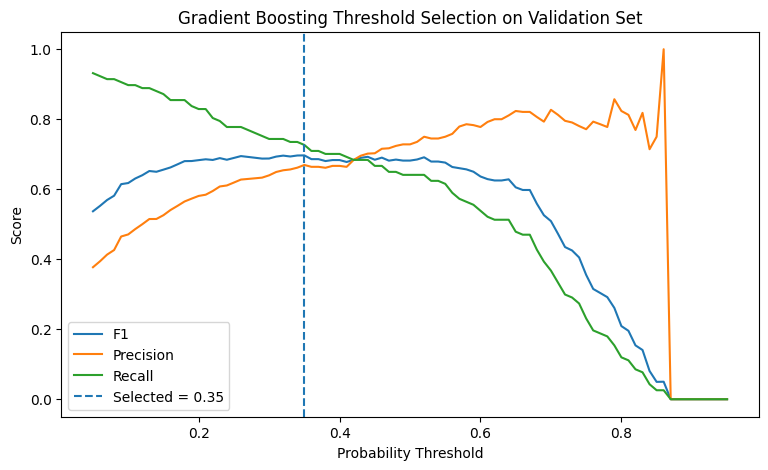

In [62]:
plt.figure(figsize=(9,5))
plt.plot(gb_threshold_results["threshold"],gb_threshold_results["f1"],label="F1")
plt.plot(gb_threshold_results["threshold"],gb_threshold_results["precision"],label="Precision")
plt.plot(gb_threshold_results["threshold"],gb_threshold_results["recall"],label="Recall")
plt.axvline(gb_best_threshold,linestyle="--",label=f"Selected = {gb_best_threshold:.2f}")
plt.title("Gradient Boosting Threshold Selection on Validation Set")
plt.xlabel("Probability Threshold")
plt.ylabel("Score")
plt.legend()
plt.show()

In [63]:
gb_train_metrics = evaluate_predictions(y_train,gb_train_prob,gb_best_threshold)
gb_val_metrics = evaluate_predictions(y_val,gb_val_prob,gb_best_threshold)

gb_results = pd.DataFrame([gb_train_metrics,gb_val_metrics],index=["Train","Validation"])
display(gb_results.round(4))

,ROC-AUC,PR-AUC,F1,Precision,Recall
Train,0.9403,0.7293,0.6938,0.6310,0.7705
Validation,0.9279,0.7083,0.6967,0.6693,0.7265


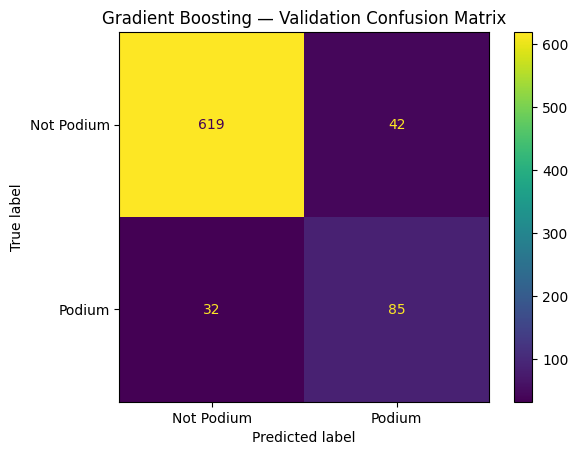

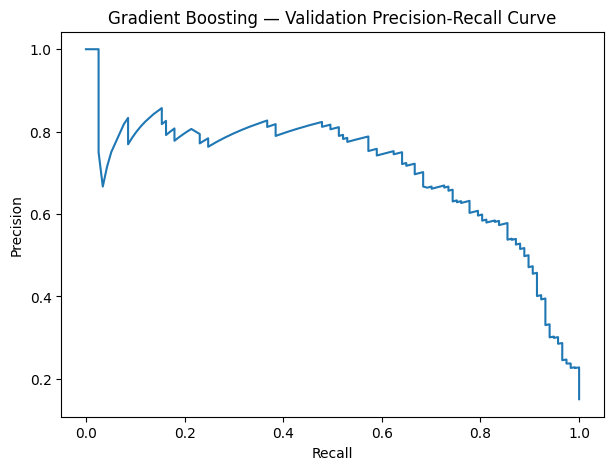

In [64]:
gb_val_pred = (gb_val_prob>=gb_best_threshold).astype(int)

ConfusionMatrixDisplay(confusion_matrix(y_val,gb_val_pred),display_labels=["Not Podium","Podium"]).plot()
plt.title("Gradient Boosting — Validation Confusion Matrix")
plt.show()

gb_precision,gb_recall,_ = precision_recall_curve(y_val,gb_val_prob)

plt.figure(figsize=(7,5))
plt.plot(gb_recall,gb_precision)
plt.title("Gradient Boosting — Validation Precision-Recall Curve")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.show()

In [65]:
model_comparison_val = pd.DataFrame({
    "Logistic Regression":logreg_val_metrics,
    "Gradient Boosting":gb_val_metrics
}).T

display(model_comparison_val.round(4))

,ROC-AUC,PR-AUC,F1,Precision,Recall
Logistic Regression,0.9316,0.7315,0.6953,0.6983,0.6923
Gradient Boosting,0.9279,0.7083,0.6967,0.6693,0.7265


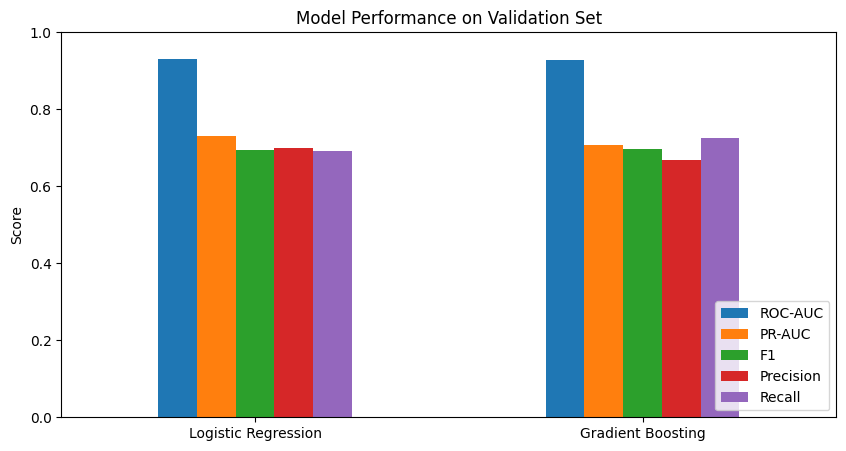

In [66]:
model_comparison_val.plot(kind="bar",figsize=(10,5))
plt.title("Model Performance on Validation Set")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.ylim(0,1)
plt.legend(loc="lower right")
plt.show()

### Gradient Boosting Limitations

Gradient Boosting can model non-linear effects and feature interactions more naturally than Logistic
Regression, but it is also more prone to overfitting. Training and validation performance must
therefore be compared when selecting tree depth, learning rate and number of estimators.

The model is also less directly interpretable than Logistic Regression. Feature importance values
do not themselves describe causal effects, so dedicated explainability methods will later be used.

Finally, the model is trained on historical Formula 1 eras and may lose accuracy when regulations,
teams or competitive patterns shift substantially.

### Gradient Boosting Results

The default Gradient Boosting model showed noticeably higher training than validation performance,
particularly for PR-AUC (0.8048 training versus 0.6476 validation), indicating overfitting.

A small validation-based hyperparameter experiment therefore tested shallower trees, lower learning
rates and different numbers of estimators. GB4, using 200 estimators, a learning rate of 0.03 and
maximum tree depth of 2, achieved the best validation PR-AUC of 0.7083.

Using the validation set only, its F1-optimal probability threshold was 0.35. At this threshold,
Gradient Boosting achieved validation F1 = 0.6967, precision = 0.6693 and recall = 0.7265.

Compared with Logistic Regression, Gradient Boosting achieved slightly higher F1 and recall, but
lower ROC-AUC, PR-AUC and precision. Since PR-AUC is the primary model-selection metric,
Logistic Regression currently remains the stronger model overall.

The results also show that the additional non-linear flexibility of Gradient Boosting did not
automatically improve ranking performance for this dataset.

## 10.3 Shallow Feed-Forward Neural Network

A feed-forward neural network passes the standardized feature values through one or more hidden
layers before producing a podium probability using a sigmoid output unit.

Unlike Logistic Regression, hidden layers can learn non-linear combinations and interactions among
features such as grid position, qualifying pace, standings and recent form.

The network is intentionally shallow, using only one or two hidden layers, as required by the
project. The same 21 features and the same training, validation and test rows are used as for the
other models.

Training uses the scaled and imputed data. Architecture selection and early stopping use the validation set only; test labels and test performance are not used during model selection.

In [67]:
# ============================================================
# 10.3.1 SHALLOW FFNN SETUP
# ============================================================

import logging
import tensorflow as tf

tf.get_logger().setLevel(logging.FATAL)
tf.autograph.set_verbosity(0)

try:
    from absl import logging as absl_logging
    absl_logging.set_verbosity(absl_logging.FATAL)
except ImportError:
    pass

from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input,Dense
from tensorflow.keras.callbacks import EarlyStopping

tf.keras.utils.set_random_seed(42)
tf.config.experimental.enable_op_determinism()

In [68]:
def build_ffnn(hidden_layers,learning_rate=0.001,input_dim=None):
    if input_dim is None:
        input_dim = X_train_scaled.shape[1]

    model = Sequential([Input(shape=(input_dim,))])

    for units in hidden_layers:
        model.add(Dense(units,activation="relu"))

    model.add(Dense(1,activation="sigmoid"))

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss="binary_crossentropy",
        metrics=[
            tf.keras.metrics.AUC(name="roc_auc"),
            tf.keras.metrics.AUC(name="pr_auc",curve="PR")
        ]
    )

    return model

In [69]:
# ============================================================
# 10.3.2 FFNN ARCHITECTURE EXPERIMENT
# ============================================================

nn_configs = [
    {"name":"NN1","layers":[32],"learning_rate":0.001},
    {"name":"NN2","layers":[32,16],"learning_rate":0.001},
    {"name":"NN3","layers":[64,32],"learning_rate":0.001}
]

nn_models = {}
nn_histories = {}
nn_rows = []

for cfg in nn_configs:
    tf.keras.utils.set_random_seed(42)

    model = build_ffnn(cfg["layers"], cfg["learning_rate"])

    early_stop = EarlyStopping(
        monitor="val_pr_auc",
        mode="max",
        patience=15,
        restore_best_weights=True
    )

    history = model.fit(
        X_train_scaled, y_train,
        validation_data=(X_val_scaled,y_val),
        epochs=150,
        batch_size=64,
        callbacks=[early_stop],
        verbose=0
    )

    train_p = model.predict(X_train_scaled,verbose=0).ravel()
    val_p = model.predict(X_val_scaled,verbose=0).ravel()

    nn_rows.append({
        "Model":cfg["name"],
        "Hidden layers":str(cfg["layers"]),
        "Epochs":len(history.history["loss"]),
        "Train ROC-AUC":roc_auc_score(y_train,train_p),
        "Train PR-AUC":average_precision_score(y_train,train_p),
        "Validation ROC-AUC":roc_auc_score(y_val,val_p),
        "Validation PR-AUC":average_precision_score(y_val,val_p)
    })

    nn_models[cfg["name"]] = model
    nn_histories[cfg["name"]] = history

nn_experiments = pd.DataFrame(nn_rows)
display(nn_experiments.round(4))

,Model,Hidden layers,Epochs,Train ROC-AUC,Train PR-AUC,Validation ROC-AUC,Validation PR-AUC
0,NN1,[32],50,0.9394,0.7083,0.9297,0.7354
1,NN2,"[32, 16]",34,0.9401,0.7055,0.9285,0.7285
2,NN3,"[64, 32]",21,0.9366,0.7025,0.9232,0.7164


### FFNN Architecture Selection

The single-hidden-layer NN1 architecture `[32]` achieved the best validation PR-AUC (0.7354).
Increasing network depth or width did not improve generalization: NN2 achieved 0.7285 and NN3
0.7164 validation PR-AUC.

The simpler NN1 is therefore retained. This suggests that the available Formula 1 dataset does
not benefit from additional network complexity, and larger architectures begin to lose validation
performance despite having greater representational capacity.

In [70]:
# ============================================================
# 10.3.3 SELECT BEST FFNN
# ============================================================

best_nn_name = nn_experiments.loc[nn_experiments["Validation PR-AUC"].idxmax(),"Model"]
best_nn = nn_models[best_nn_name]
best_nn_history = nn_histories[best_nn_name]

nn_train_prob = best_nn.predict(X_train_scaled,verbose=0).ravel()
nn_val_prob = best_nn.predict(X_val_scaled,verbose=0).ravel()

print("Selected neural network:",best_nn_name)
display(nn_experiments[nn_experiments["Model"]==best_nn_name].round(4))

Selected neural network: NN1


,Model,Hidden layers,Epochs,Train ROC-AUC,Train PR-AUC,Validation ROC-AUC,Validation PR-AUC
0,NN1,[32],50,0.9394,0.7083,0.9297,0.7354


In [71]:
# ============================================================
# 10.3.3A NN1 SEED ROBUSTNESS
# ============================================================

NN_SEEDS = [7,21,42,84,123]
nn_seed_rows = []

for seed in NN_SEEDS:
    tf.keras.utils.set_random_seed(seed)

    model = build_ffnn([32],0.001)
    stop = EarlyStopping(monitor="val_pr_auc",mode="max",patience=15,restore_best_weights=True)

    history = model.fit(
        X_train_scaled,y_train,
        validation_data=(X_val_scaled,y_val),
        epochs=150,batch_size=64,callbacks=[stop],verbose=0
    )

    train_p = model.predict(X_train_scaled,verbose=0).ravel()
    val_p = model.predict(X_val_scaled,verbose=0).ravel()

    nn_seed_rows.append({
        "Seed":seed,
        "Epochs":len(history.history["loss"]),
        "Train ROC-AUC":roc_auc_score(y_train,train_p),
        "Train PR-AUC":average_precision_score(y_train,train_p),
        "Validation ROC-AUC":roc_auc_score(y_val,val_p),
        "Validation PR-AUC":average_precision_score(y_val,val_p)
    })

nn_seed_results = pd.DataFrame(nn_seed_rows)
display(nn_seed_results.round(4))

nn_seed_summary = pd.DataFrame({
    "Mean":[nn_seed_results["Validation ROC-AUC"].mean(),nn_seed_results["Validation PR-AUC"].mean()],
    "Std":[nn_seed_results["Validation ROC-AUC"].std(),nn_seed_results["Validation PR-AUC"].std()]
},index=["Validation ROC-AUC","Validation PR-AUC"])

display(nn_seed_summary.round(4))
print(f"Logistic Regression validation PR-AUC: {logreg_val_metrics['PR-AUC']:.4f}")

,Seed,Epochs,Train ROC-AUC,Train PR-AUC,Validation ROC-AUC,Validation PR-AUC
0,7,68,0.9409,0.7079,0.9286,0.7321
1,21,32,0.9363,0.7032,0.9247,0.7244
2,42,50,0.9394,0.7083,0.9297,0.7354
3,84,45,0.9381,0.7092,0.9301,0.7396
4,123,37,0.9379,0.7032,0.9259,0.7358


,Mean,Std
Validation ROC-AUC,0.9278,0.0024
Validation PR-AUC,0.7334,0.0057


Logistic Regression validation PR-AUC: 0.7315


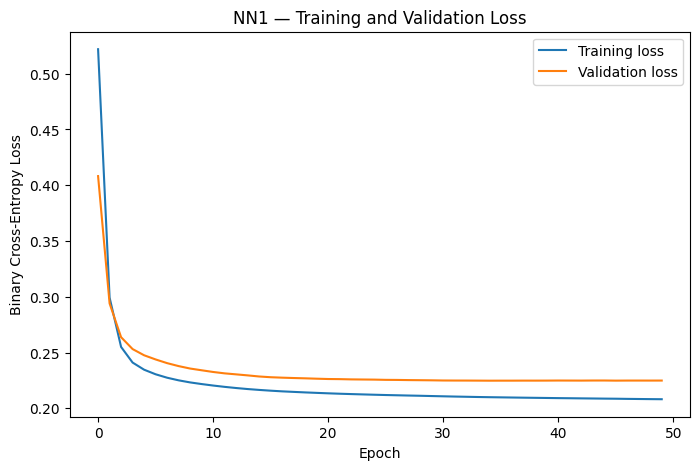

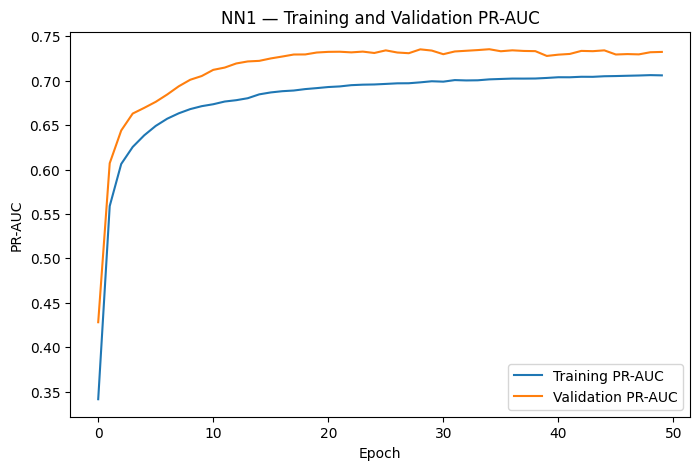

In [72]:
# ============================================================
# 10.3.4 FFNN TRAINING CURVES
# ============================================================

history_df = pd.DataFrame(best_nn_history.history)

plt.figure(figsize=(8,5))
plt.plot(history_df["loss"],label="Training loss")
plt.plot(history_df["val_loss"],label="Validation loss")
plt.title(f"{best_nn_name} — Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.legend()
plt.show()

plt.figure(figsize=(8,5))
plt.plot(history_df["pr_auc"],label="Training PR-AUC")
plt.plot(history_df["val_pr_auc"],label="Validation PR-AUC")
plt.title(f"{best_nn_name} — Training and Validation PR-AUC")
plt.xlabel("Epoch")
plt.ylabel("PR-AUC")
plt.legend()
plt.show()

In [73]:
# ============================================================
# 10.3.5 FFNN THRESHOLD SELECTION
# ============================================================

nn_threshold_rows = []

for t in thresholds:
    pred = (nn_val_prob>=t).astype(int)
    nn_threshold_rows.append({
        "threshold":t,
        "f1":f1_score(y_val,pred,zero_division=0),
        "precision":precision_score(y_val,pred,zero_division=0),
        "recall":recall_score(y_val,pred,zero_division=0)
    })

nn_threshold_results = pd.DataFrame(nn_threshold_rows)
nn_best_row = nn_threshold_results.loc[nn_threshold_results["f1"].idxmax()]
nn_best_threshold = nn_best_row["threshold"]

display(nn_best_row.to_frame().T.round(4))
print(f"Selected FFNN threshold: {nn_best_threshold:.2f}")

,threshold,f1,precision,recall
29,0.34,0.7054,0.6855,0.7265


Selected FFNN threshold: 0.34


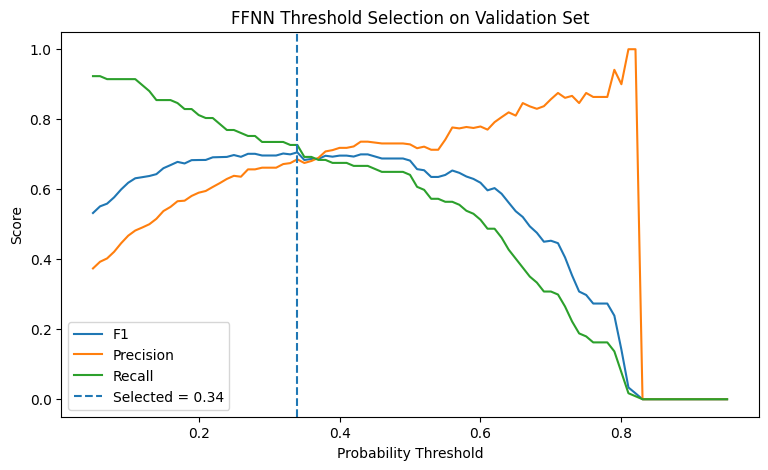

In [74]:
plt.figure(figsize=(9,5))
plt.plot(nn_threshold_results["threshold"],nn_threshold_results["f1"],label="F1")
plt.plot(nn_threshold_results["threshold"],nn_threshold_results["precision"],label="Precision")
plt.plot(nn_threshold_results["threshold"],nn_threshold_results["recall"],label="Recall")
plt.axvline(nn_best_threshold,linestyle="--",label=f"Selected = {nn_best_threshold:.2f}")
plt.title("FFNN Threshold Selection on Validation Set")
plt.xlabel("Probability Threshold")
plt.ylabel("Score")
plt.legend()
plt.show()

In [75]:
# ============================================================
# 10.3.6 FFNN PERFORMANCE
# ============================================================

nn_train_metrics = evaluate_predictions(y_train,nn_train_prob,nn_best_threshold)
nn_val_metrics = evaluate_predictions(y_val,nn_val_prob,nn_best_threshold)

nn_results = pd.DataFrame(
    [nn_train_metrics,nn_val_metrics],
    index=["Train","Validation"]
)

display(nn_results.round(4))

,ROC-AUC,PR-AUC,F1,Precision,Recall
Train,0.9394,0.7083,0.6801,0.6319,0.7362
Validation,0.9297,0.7354,0.7054,0.6855,0.7265


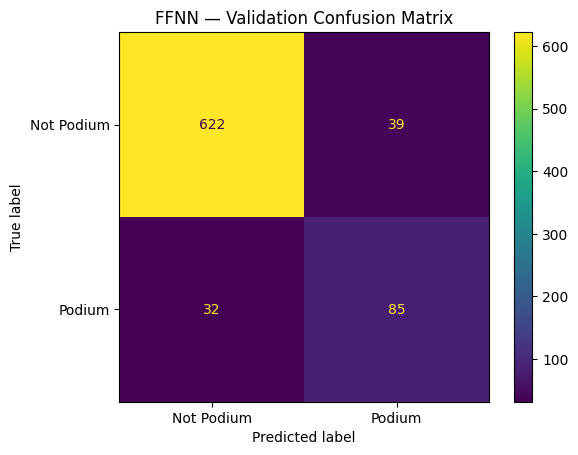

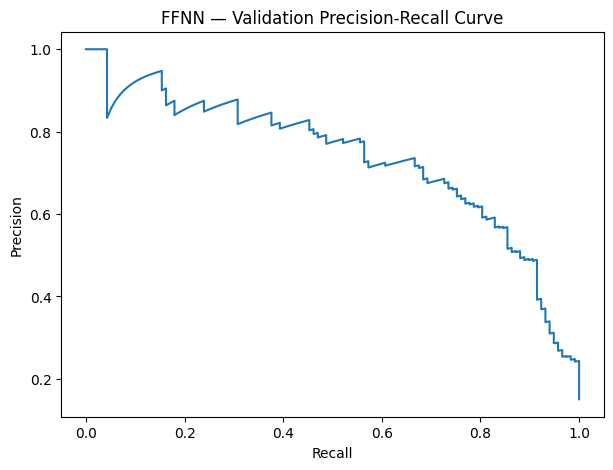

In [76]:
nn_val_pred = (nn_val_prob>=nn_best_threshold).astype(int)

ConfusionMatrixDisplay(
    confusion_matrix(y_val,nn_val_pred),
    display_labels=["Not Podium","Podium"]
).plot()

plt.title("FFNN — Validation Confusion Matrix")
plt.show()

nn_precision,nn_recall,_ = precision_recall_curve(y_val,nn_val_prob)

plt.figure(figsize=(7,5))
plt.plot(nn_recall,nn_precision)
plt.title("FFNN — Validation Precision-Recall Curve")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.show()

In [77]:
# ============================================================
# 10.3.7 VALIDATION MODEL COMPARISON
# ============================================================

def evaluate_grid_baseline(df,y_true):
    grid = df["grid"].astype(float).copy()
    worst_grid = grid[grid>0].max()+1
    effective_grid = grid.where(grid>0,worst_grid)

    ranking_score = -effective_grid.to_numpy()

    pred = grid.between(1,3).astype(int).to_numpy()

    return {
        "ROC-AUC":roc_auc_score(y_true,ranking_score),
        "PR-AUC":average_precision_score(y_true,ranking_score),
        "F1":f1_score(y_true,pred,zero_division=0),
        "Precision":precision_score(y_true,pred,zero_division=0),
        "Recall":recall_score(y_true,pred,zero_division=0)
    }

grid_train_metrics = evaluate_grid_baseline(train_df,y_train)
grid_val_metrics = evaluate_grid_baseline(val_df,y_val)

model_comparison_val = pd.DataFrame({
    "Grid Baseline":grid_val_metrics,
    "Logistic Regression":logreg_val_metrics,
    "Gradient Boosting":gb_val_metrics,
    "Shallow FFNN":nn_val_metrics
}).T

display(model_comparison_val.round(4))

,ROC-AUC,PR-AUC,F1,Precision,Recall
Grid Baseline,0.9092,0.6386,0.6923,0.6923,0.6923
Logistic Regression,0.9316,0.7315,0.6953,0.6983,0.6923
Gradient Boosting,0.9279,0.7083,0.6967,0.6693,0.7265
Shallow FFNN,0.9297,0.7354,0.7054,0.6855,0.7265


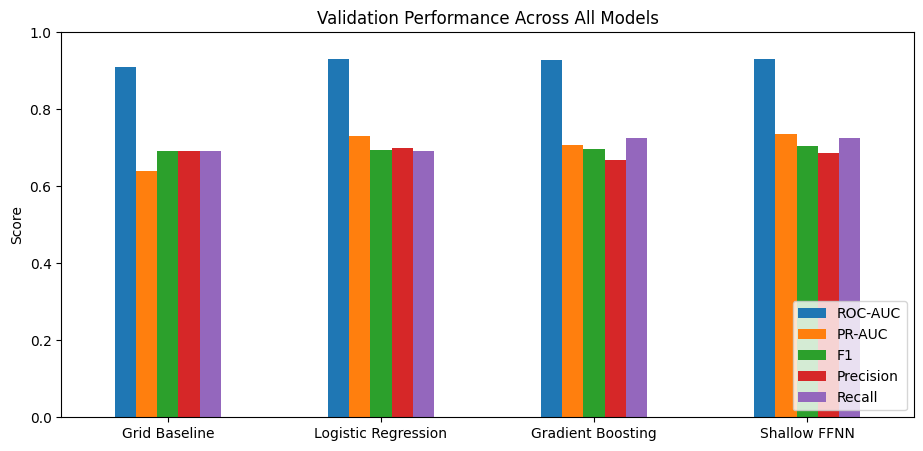

In [78]:
model_comparison_val.plot(kind="bar",figsize=(11,5))
plt.title("Validation Performance Across All Models")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.ylim(0,1)
plt.legend(loc="lower right")
plt.show()

### Validation Model Comparison

Logistic Regression achieved validation PR-AUC = 0.7315, while NN1 achieved a mean validation
PR-AUC of 0.7334 across five random seeds with a standard deviation of 0.0057.

The difference between their central values is only 0.0019, which is smaller than the neural
network's variation across random initializations. Therefore, Logistic Regression and NN1 should
be considered effectively tied on validation PR-AUC rather than treating the single seed-42 NN
result of 0.7354 as a clear improvement.

The seed-42 NN1 run is retained as the representative neural-network model for the remaining
evaluation because the architecture and seed were fixed before test evaluation. Gradient Boosting
had lower validation PR-AUC (0.7083), although it achieved relatively high recall.

Overall, the validation results show that additional model complexity did not produce a clear
advantage over Logistic Regression.

### Shallow FFNN Limitations

The neural network can learn non-linear relationships and feature interactions but is less directly
interpretable than Logistic Regression.

Early stopping is the only regularization mechanism used. Training stops when validation PR-AUC
fails to improve for 15 epochs and the best validation weights are restored. Dropout and L2 weight
penalties were not added because the network is intentionally shallow and the architecture
experiment already showed that increasing model complexity did not improve validation performance.

NN performance also depends on random initialization. Therefore, NN1 is additionally evaluated
across five random seeds rather than relying only on one initialization.

The relatively small Formula 1 dataset limits how much a neural network can learn, and the model
may also be sensitive to distribution shifts between regulation eras.

# 11. Feature-Group Ablation

Feature-group ablation measures the predictive contribution of the four engineered feature groups.

Starting from the selected NN1 model, one complete feature group is removed at a time:

- Grid
- Qualifying
- Standings
- Form

For every experiment, imputation and scaling are refitted using only the remaining training features.
The NN1 architecture and training settings are kept fixed so that differences in validation
performance can be attributed to the removed feature group rather than additional model tuning.

PR-AUC is the primary ablation metric because it was also used for model selection.

In [79]:
# ============================================================
# 11.1 FEATURE-GROUP ABLATION — NN1, MULTIPLE SEEDS
# ============================================================

def run_nn_ablation(features,seed):
    Xtr = train_df[features].copy()
    Xv = val_df[features].copy()

    imp = SimpleImputer(strategy="median")
    sc = StandardScaler()

    Xtr = sc.fit_transform(imp.fit_transform(Xtr))
    Xv = sc.transform(imp.transform(Xv))

    tf.keras.utils.set_random_seed(seed)

    model = build_ffnn([32],0.001,input_dim=Xtr.shape[1])
    stop = EarlyStopping(monitor="val_pr_auc",mode="max",patience=15,restore_best_weights=True)

    history = model.fit(
        Xtr,y_train,validation_data=(Xv,y_val),
        epochs=150,batch_size=64,callbacks=[stop],verbose=0
    )

    train_p = model.predict(Xtr,verbose=0).ravel()
    val_p = model.predict(Xv,verbose=0).ravel()

    return {
        "Epochs":len(history.history["loss"]),
        "Train PR-AUC":average_precision_score(y_train,train_p),
        "Validation ROC-AUC":roc_auc_score(y_val,val_p),
        "Validation PR-AUC":average_precision_score(y_val,val_p)
    }

experiments = {"All features":FEATURES}
for group,group_features in FEATURE_GROUPS.items():
    experiments[f"Without {group}"] = [f for f in FEATURES if f not in group_features]

ablation_seed_rows = []

for name,features in experiments.items():
    for seed in NN_SEEDS:
        print(f"{name} | seed {seed}")
        result = run_nn_ablation(features,seed)
        result.update({"Experiment":name,"Features":len(features),"Seed":seed})
        ablation_seed_rows.append(result)

ablation_seed_results = pd.DataFrame(ablation_seed_rows)

full_by_seed = (ablation_seed_results[ablation_seed_results["Experiment"]=="All features"]
                [["Seed","Validation PR-AUC"]]
                .rename(columns={"Validation PR-AUC":"Full PR-AUC"}))

ablation_seed_results = ablation_seed_results.merge(full_by_seed,on="Seed",how="left")
ablation_seed_results["PR-AUC change vs full"] = (
    ablation_seed_results["Validation PR-AUC"]-ablation_seed_results["Full PR-AUC"]
)

ablation_results = (ablation_seed_results.groupby(["Experiment","Features"],sort=False)
                    .agg(Epochs_mean=("Epochs","mean"),
                         Train_PR_AUC_mean=("Train PR-AUC","mean"),
                         Validation_ROC_AUC_mean=("Validation ROC-AUC","mean"),
                         Validation_PR_AUC_mean=("Validation PR-AUC","mean"),
                         Validation_PR_AUC_std=("Validation PR-AUC","std"),
                         PR_AUC_change_mean=("PR-AUC change vs full","mean"),
                         PR_AUC_change_std=("PR-AUC change vs full","std"))
                    .reset_index())

display(ablation_results.round(4))

All features | seed 7
All features | seed 21
All features | seed 42
All features | seed 84
All features | seed 123
Without grid | seed 7
Without grid | seed 21
Without grid | seed 42
Without grid | seed 84
Without grid | seed 123
Without qualifying | seed 7
Without qualifying | seed 21
Without qualifying | seed 42
Without qualifying | seed 84
Without qualifying | seed 123
Without standings | seed 7
Without standings | seed 21
Without standings | seed 42
Without standings | seed 84
Without standings | seed 123
Without form | seed 7
Without form | seed 21
Without form | seed 42
Without form | seed 84
Without form | seed 123


,Experiment,Features,Epochs_mean,Train_PR_AUC_mean,Validation_ROC_AUC_mean,Validation_PR_AUC_mean,Validation_PR_AUC_std,PR_AUC_change_mean,PR_AUC_change_std
0,All features,21,46.4,0.7064,0.9278,0.7334,0.0057,0.0000,0.0000
1,Without grid,19,46.8,0.7095,0.9262,0.7172,0.0137,-0.0162,0.0143
2,Without qualifying,14,63.2,0.7049,0.9243,0.7176,0.0080,-0.0158,0.0126
3,Without standings,15,44.4,0.7035,0.9266,0.7225,0.0115,-0.0110,0.0113
4,Without form,15,27.6,0.6818,0.9260,0.7290,0.0034,-0.0044,0.0081


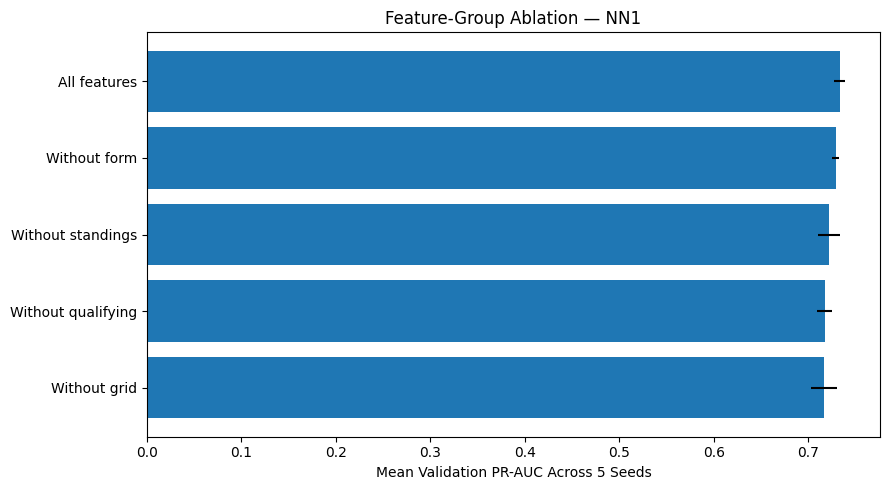

In [80]:
plot_ablation = ablation_results.sort_values("Validation_PR_AUC_mean",ascending=True)

plt.figure(figsize=(9,5))
plt.barh(plot_ablation["Experiment"],plot_ablation["Validation_PR_AUC_mean"],
         xerr=plot_ablation["Validation_PR_AUC_std"])
plt.xlabel("Mean Validation PR-AUC Across 5 Seeds")
plt.title("Feature-Group Ablation — NN1")
plt.tight_layout()
plt.show()

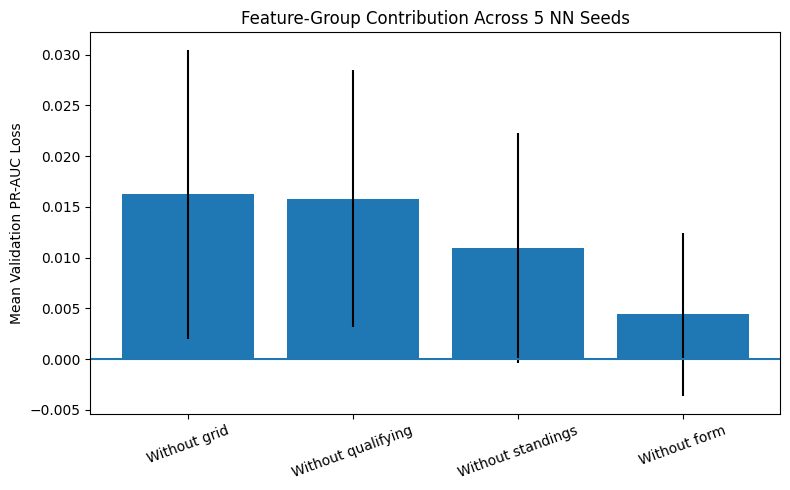

In [81]:
drop_plot = ablation_results[ablation_results["Experiment"]!="All features"].copy()
drop_plot["Mean PR-AUC loss"] = -drop_plot["PR_AUC_change_mean"]

plt.figure(figsize=(8,5))
plt.bar(drop_plot["Experiment"],drop_plot["Mean PR-AUC loss"],
        yerr=drop_plot["PR_AUC_change_std"])
plt.axhline(0)
plt.ylabel("Mean Validation PR-AUC Loss")
plt.title("Feature-Group Contribution Across 5 NN Seeds")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [82]:
# ============================================================
# 11.2 LOGISTIC REGRESSION ABLATION SANITY CHECK
# ============================================================

lr_ablation_rows = []

for name,features in experiments.items():
    imp = SimpleImputer(strategy="median")
    sc = StandardScaler()

    Xtr = sc.fit_transform(imp.fit_transform(train_df[features]))
    Xv = sc.transform(imp.transform(val_df[features]))

    model = LogisticRegression(max_iter=3000,random_state=42)
    model.fit(Xtr,y_train)

    prob = model.predict_proba(Xv)[:,1]

    lr_ablation_rows.append({
        "Experiment":name,
        "Validation ROC-AUC":roc_auc_score(y_val,prob),
        "Validation PR-AUC":average_precision_score(y_val,prob)
    })

lr_ablation = pd.DataFrame(lr_ablation_rows)
lr_full_pr = lr_ablation.loc[lr_ablation["Experiment"]=="All features","Validation PR-AUC"].iloc[0]
lr_ablation["PR-AUC change vs full"] = lr_ablation["Validation PR-AUC"] - lr_full_pr

display(lr_ablation.round(4))

,Experiment,Validation ROC-AUC,Validation PR-AUC,PR-AUC change vs full
0,All features,0.9316,0.7315,0.0000
1,Without grid,0.9305,0.7296,-0.0019
2,Without qualifying,0.9231,0.7078,-0.0237
3,Without standings,0.9305,0.7203,-0.0112
4,Without form,0.9305,0.7276,-0.0039


### Feature-Group Ablation Findings

The five-seed NN1 ablation shows that grid and qualifying produced the largest average decreases
in validation PR-AUC when removed: approximately 0.0162 and 0.0158 respectively. Removing
standings reduced PR-AUC by approximately 0.0110, while removing form produced the smallest
average reduction at approximately 0.0044.

However, the standard deviations across random seeds are relatively large compared with these
average drops. The neural-network ablation should therefore be interpreted as evidence of broad
feature-group contribution rather than a precise ranking of feature importance.

The deterministic Logistic Regression ablation provides complementary evidence. For Logistic
Regression, removing qualifying caused the largest PR-AUC decrease (-0.0237), followed by
standings (-0.0112), while grid and form had smaller incremental effects.

The difference between models is expected because correlated groups such as grid and qualifying
can substitute for one another differently in linear and non-linear models.

All four feature groups are retained because each contains valid pre-race information and provides
predictive value or complementary information in at least one model.

# 12. Final Evaluation on the Unseen Test Set

All model choices, hyperparameters and classification thresholds were selected using only the
training and validation sets.

The 2022–2024 test set has not been used for model selection. It is evaluated only now to provide
an unbiased estimate of performance on future Formula 1 seasons.

The following configurations are frozen before testing:

- Logistic Regression with its validation-selected threshold.
- GB4 Gradient Boosting with its validation-selected threshold.
- NN1 shallow FFNN with its validation-selected threshold.

No model, feature, hyperparameter or threshold is changed based on test performance.

In [83]:
# ============================================================
# 12.1 UNSEEN TEST PREDICTIONS
# ============================================================

logreg_test_prob = logreg.predict_proba(X_test_scaled)[:,1]
gb_test_prob = best_gb.predict_proba(X_test_imp)[:,1]
nn_test_prob = best_nn.predict(X_test_scaled,verbose=0).ravel()
grid_test_score = test_df["grid"].between(1,3).astype(float).to_numpy()

logreg_test_metrics = evaluate_predictions(y_test,logreg_test_prob,best_threshold)
gb_test_metrics = evaluate_predictions(y_test,gb_test_prob,gb_best_threshold)
nn_test_metrics = evaluate_predictions(y_test,nn_test_prob,nn_best_threshold)
# grid_test_metrics = evaluate_predictions(y_test,grid_test_score,0.5)
grid_test_metrics = evaluate_grid_baseline(test_df,y_test)

test_results = pd.DataFrame({
    "Grid Baseline":grid_test_metrics,
    "Logistic Regression":logreg_test_metrics,
    "Gradient Boosting":gb_test_metrics,
    "Shallow FFNN":nn_test_metrics
}).T

display(test_results.round(4))

,ROC-AUC,PR-AUC,F1,Precision,Recall
Grid Baseline,0.9135,0.6474,0.6486,0.6502,0.6471
Logistic Regression,0.9362,0.7088,0.6442,0.6851,0.6078
Gradient Boosting,0.9397,0.7243,0.6968,0.6471,0.7549
Shallow FFNN,0.9360,0.6938,0.6682,0.6425,0.6961


In [84]:
# ============================================================
# 12.2 VALIDATION VS TEST GENERALIZATION
# ============================================================

comparison_rows = []

for model_name,val_metrics,test_metrics in [
    ("Grid Baseline",grid_val_metrics,grid_test_metrics),
    ("Logistic Regression",logreg_val_metrics,logreg_test_metrics),
    ("Gradient Boosting",gb_val_metrics,gb_test_metrics),
    ("Shallow FFNN",nn_val_metrics,nn_test_metrics)
]:
    comparison_rows.append({
        "Model":model_name,
        "Validation ROC-AUC":val_metrics["ROC-AUC"],
        "Test ROC-AUC":test_metrics["ROC-AUC"],
        "Validation PR-AUC":val_metrics["PR-AUC"],
        "Test PR-AUC":test_metrics["PR-AUC"],
        "Validation F1":val_metrics["F1"],
        "Test F1":test_metrics["F1"],
        "Validation Precision":val_metrics["Precision"],
        "Test Precision":test_metrics["Precision"],
        "Validation Recall":val_metrics["Recall"],
        "Test Recall":test_metrics["Recall"],
        "PR-AUC change":test_metrics["PR-AUC"]-val_metrics["PR-AUC"]
    })

generalization_results = pd.DataFrame(comparison_rows)
display(generalization_results.round(4))

,Model,Validation ROC-AUC,Test ROC-AUC,Validation PR-AUC,Test PR-AUC,Validation F1,Test F1,Validation Precision,Test Precision,Validation Recall,Test Recall,PR-AUC change
0,Grid Baseline,0.9092,0.9135,0.6386,0.6474,0.6923,0.6486,0.6923,0.6502,0.6923,0.6471,0.0088
1,Logistic Regression,0.9316,0.9362,0.7315,0.7088,0.6953,0.6442,0.6983,0.6851,0.6923,0.6078,-0.0228
2,Gradient Boosting,0.9279,0.9397,0.7083,0.7243,0.6967,0.6968,0.6693,0.6471,0.7265,0.7549,0.0160
3,Shallow FFNN,0.9297,0.9360,0.7354,0.6938,0.7054,0.6682,0.6855,0.6425,0.7265,0.6961,-0.0416


In [85]:
# ============================================================
# 12.2.1 COMPLETE MODEL COMPARISON TABLE
# ============================================================

all_metrics = {
    "Grid Baseline":{"Train":grid_train_metrics,"Validation":grid_val_metrics,"Test":grid_test_metrics},
    "Logistic Regression":{"Train":logreg_train_metrics,"Validation":logreg_val_metrics,"Test":logreg_test_metrics},
    "Gradient Boosting":{"Train":gb_train_metrics,"Validation":gb_val_metrics,"Test":gb_test_metrics},
    "Shallow FFNN":{"Train":nn_train_metrics,"Validation":nn_val_metrics,"Test":nn_test_metrics}
}

combined_rows = []

for model_name,splits in all_metrics.items():
    for split_name,metrics in splits.items():
        combined_rows.append({
            "Model":model_name,"Split":split_name,
            "ROC-AUC":metrics["ROC-AUC"],"PR-AUC":metrics["PR-AUC"],
            "F1":metrics["F1"],"Precision":metrics["Precision"],"Recall":metrics["Recall"]
        })

complete_model_table = pd.DataFrame(combined_rows)
display(complete_model_table.round(4))

,Model,Split,ROC-AUC,PR-AUC,F1,Precision,Recall
0,Grid Baseline,Train,0.9087,0.6277,0.6472,0.6486,0.6459
1,Grid Baseline,Validation,0.9092,0.6386,0.6923,0.6923,0.6923
2,Grid Baseline,Test,0.9135,0.6474,0.6486,0.6502,0.6471
3,Logistic Regression,Train,0.9296,0.6890,0.6523,0.6589,0.6459
4,Logistic Regression,Validation,0.9316,0.7315,0.6953,0.6983,0.6923
5,Logistic Regression,Test,0.9362,0.7088,0.6442,0.6851,0.6078
6,Gradient Boosting,Train,0.9403,0.7293,0.6938,0.6310,0.7705
7,Gradient Boosting,Validation,0.9279,0.7083,0.6967,0.6693,0.7265
8,Gradient Boosting,Test,0.9397,0.7243,0.6968,0.6471,0.7549
9,Shallow FFNN,Train,0.9394,0.7083,0.6801,0.6319,0.7362


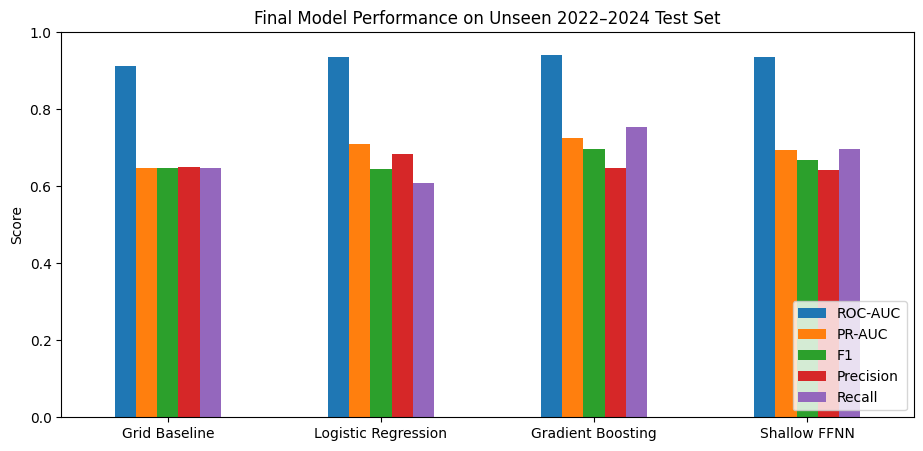

In [86]:
test_results.plot(kind="bar",figsize=(11,5))
plt.title("Final Model Performance on Unseen 2022–2024 Test Set")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.ylim(0,1)
plt.legend(loc="lower right")
plt.show()

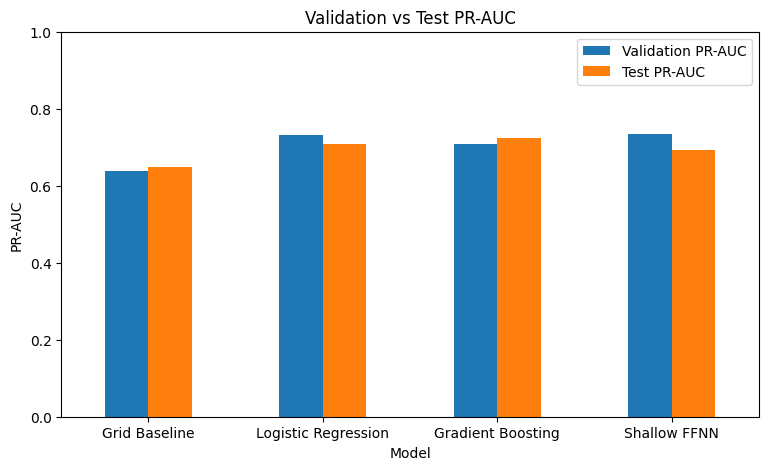

In [87]:
pr_compare = generalization_results.set_index("Model")[["Validation PR-AUC","Test PR-AUC"]]

pr_compare.plot(kind="bar",figsize=(9,5))
plt.title("Validation vs Test PR-AUC")
plt.ylabel("PR-AUC")
plt.xticks(rotation=0)
plt.ylim(0,1)
plt.show()

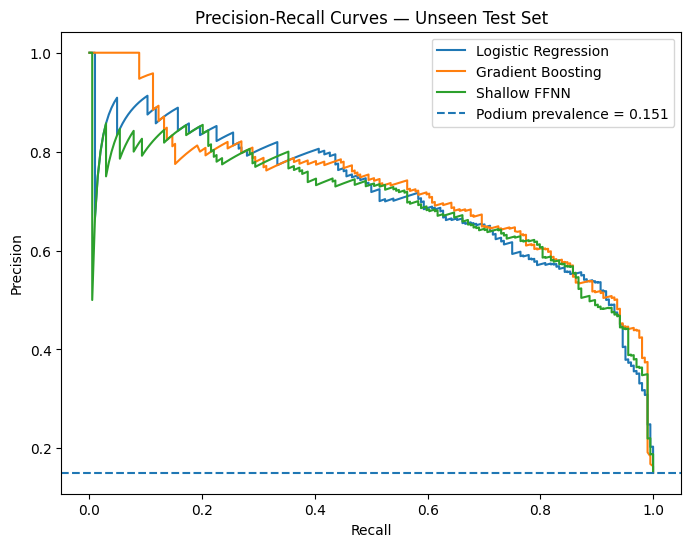

In [88]:
# ============================================================
# 12.4 TEST PRECISION-RECALL CURVES
# ============================================================

plt.figure(figsize=(8,6))

for name,prob in [
    ("Logistic Regression",logreg_test_prob),
    ("Gradient Boosting",gb_test_prob),
    ("Shallow FFNN",nn_test_prob)
]:
    p,r,_ = precision_recall_curve(y_test,prob)
    plt.plot(r,p,label=name)

plt.axhline(y_test.mean(),linestyle="--",label=f"Podium prevalence = {y_test.mean():.3f}")
plt.title("Precision-Recall Curves — Unseen Test Set")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend()
plt.show()

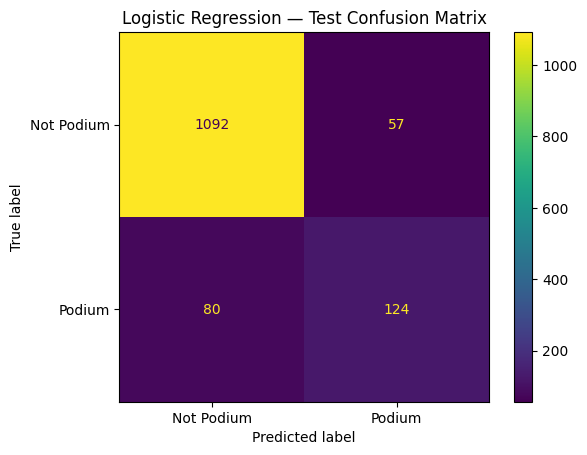

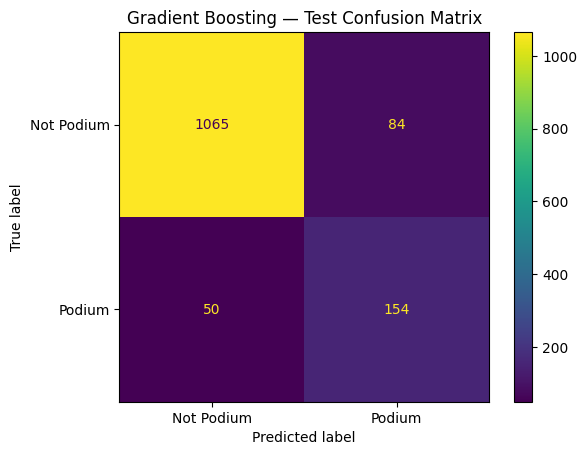

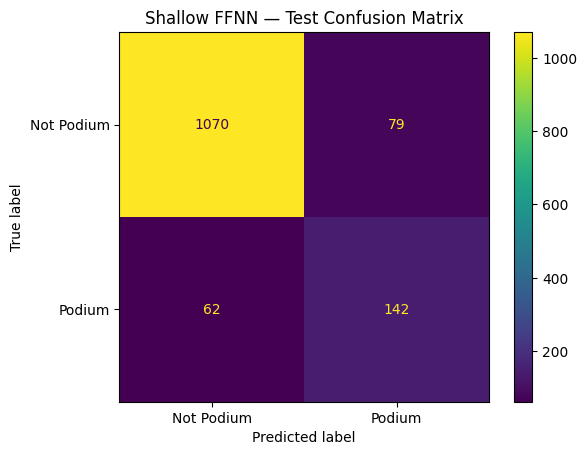

In [89]:
# ============================================================
# 12.5 TEST CONFUSION MATRICES
# ============================================================

test_predictions = {
    "Logistic Regression":(logreg_test_prob>=best_threshold).astype(int),
    "Gradient Boosting":(gb_test_prob>=gb_best_threshold).astype(int),
    "Shallow FFNN":(nn_test_prob>=nn_best_threshold).astype(int)
}

for name,pred in test_predictions.items():
    ConfusionMatrixDisplay(confusion_matrix(y_test,pred),display_labels=["Not Podium","Podium"]).plot()
    plt.title(f"{name} — Test Confusion Matrix")
    plt.show()

### Final Evaluation Interpretation

Validation robustness analysis showed that Logistic Regression and NN1 were effectively tied:
Logistic Regression achieved PR-AUC = 0.7315, while NN1 averaged 0.7334 ± 0.0057 across five
random seeds. The seed-42 NN1 model was retained as the representative neural-network run rather
than claiming that it clearly outperformed Logistic Regression.

On the unseen 2022–2024 test period, Gradient Boosting achieved the strongest overall performance,
with ROC-AUC = 0.9397, PR-AUC = 0.7243 and F1 = 0.6968. Its test PR-AUC was 0.0160 higher
than its validation PR-AUC.

Logistic Regression achieved test ROC-AUC = 0.9362 and PR-AUC = 0.7088. Its F1 fell to 0.6442
because the fixed validation-selected threshold produced lower recall in the test period.

NN1 achieved test ROC-AUC = 0.9360, PR-AUC = 0.6938 and F1 = 0.6682. Its test PR-AUC was
lower than its validation performance, illustrating that the apparent small validation advantage of
one NN initialization did not reliably transfer to the new regulation era.

The grid baseline achieved test PR-AUC = 0.6474 and F1 = 0.6486. Its ROC-AUC and PR-AUC use actual grid position as a ranking score, while its hard classification predicts podium for drivers starting P1–P3. Logistic Regression improved test PR-AUC to 0.7088, although its fixed classification threshold produced slightly lower F1 (0.6442). Gradient Boosting achieved the strongest improvement over the baseline, with test PR-AUC = 0.7243 and F1 = 0.6968. This shows that starting grid alone is already a strong predictor, while the engineered features provide additional ranking performance.

No model, threshold or feature choice was changed in response to test performance.

# 13. Explainable AI (XAI)

Explainability is applied to the representative NN1 model carried forward from validation.

Three complementary methods are used:

1. **Permutation importance** measures how much validation PR-AUC falls when one feature is shuffled.
2. **SHAP** explains how features contribute to predictions globally across many observations.
3. **LIME** explains one individual prediction locally.

These explanations describe how the trained model uses its inputs. They are not evidence that a
feature causally produces a podium finish.

In [90]:
# ============================================================
# 13.1 PERMUTATION IMPORTANCE — NN1
# ============================================================

rng = np.random.default_rng(42)
baseline_pr = average_precision_score(y_val,nn_val_prob)
perm_rows = []

for j,feature in enumerate(FEATURES):
    drops = []

    for _ in range(10):
        X_perm = X_val_scaled.copy()
        X_perm[:,j] = rng.permutation(X_perm[:,j])

        perm_prob = best_nn.predict(X_perm,verbose=0).ravel()
        perm_pr = average_precision_score(y_val,perm_prob)
        drops.append(baseline_pr-perm_pr)

    perm_rows.append({
        "Feature":feature,
        "PR-AUC drop":np.mean(drops),
        "Std":np.std(drops)
    })

permutation_importance_df = pd.DataFrame(perm_rows).sort_values("PR-AUC drop",ascending=False)

print(f"Baseline validation PR-AUC: {baseline_pr:.4f}")
display(permutation_importance_df.round(4))

Baseline validation PR-AUC: 0.7354


,Feature,PR-AUC drop,Std
0,grid,0.1488,0.0269
2,qualifying_position,0.1483,0.0266
15,driver_podium_last5,0.0712,0.0229
10,driver_points_share,0.0681,0.0171
13,driver_standing_missing,0.0255,0.0111
1,grid_zero_start,0.0249,0.0166
12,constructor_points_share,0.0235,0.0148
4,q2_recorded,0.0170,0.0136
16,driver_avg_finish_last5,0.0153,0.0121
14,constructor_standing_missing,0.0143,0.0064


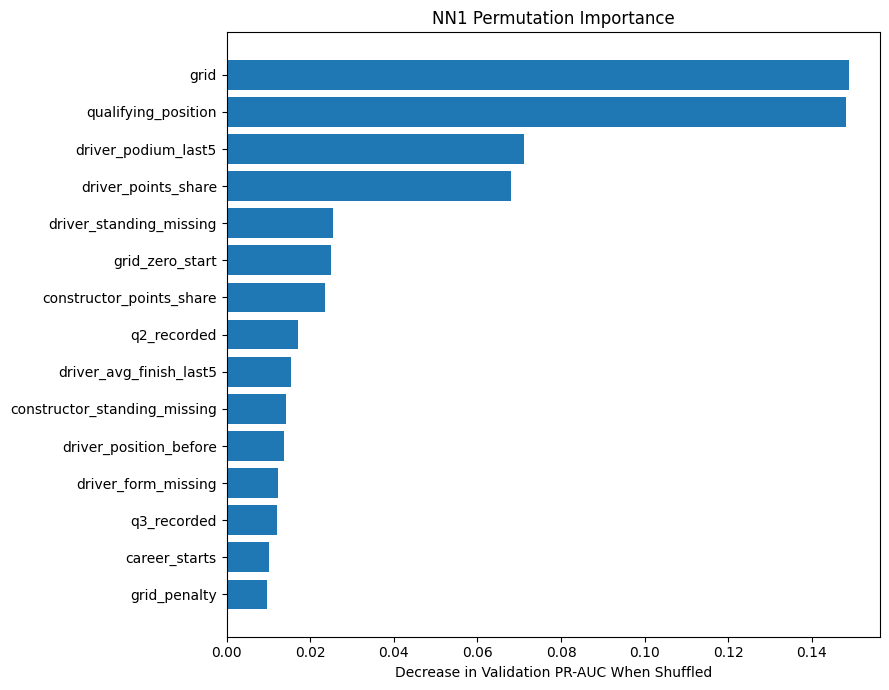

In [91]:
plot_perm = permutation_importance_df.head(15).sort_values("PR-AUC drop")

plt.figure(figsize=(9,7))
plt.barh(plot_perm["Feature"],plot_perm["PR-AUC drop"])
plt.xlabel("Decrease in Validation PR-AUC When Shuffled")
plt.title("NN1 Permutation Importance")
plt.tight_layout()
plt.show()

In [92]:
# ============================================================
# 13.2 SHAP GLOBAL EXPLANATION
# ============================================================

import shap

# Small representative samples to keep SHAP computationally manageable
X_train_shap = pd.DataFrame(X_train_scaled,columns=FEATURES).sample(50,random_state=42)
X_val_shap = pd.DataFrame(X_val_scaled,columns=FEATURES).sample(100,random_state=42)

def nn_predict_shap(x):
    x = np.asarray(x,dtype=np.float32)
    return best_nn.predict(x,verbose=0).ravel()

masker = shap.maskers.Independent(X_train_shap)

explainer = shap.Explainer(
    nn_predict_shap,
    masker,
    algorithm="permutation"
)

shap_values = explainer(
    X_val_shap,
    max_evals=2*len(FEATURES)+1
)

print("SHAP rows explained:",len(X_val_shap))
print("SHAP features:",len(FEATURES))

PermutationExplainer explainer: 101it [00:33,  2.58it/s]                         

SHAP rows explained: 100
SHAP features: 21


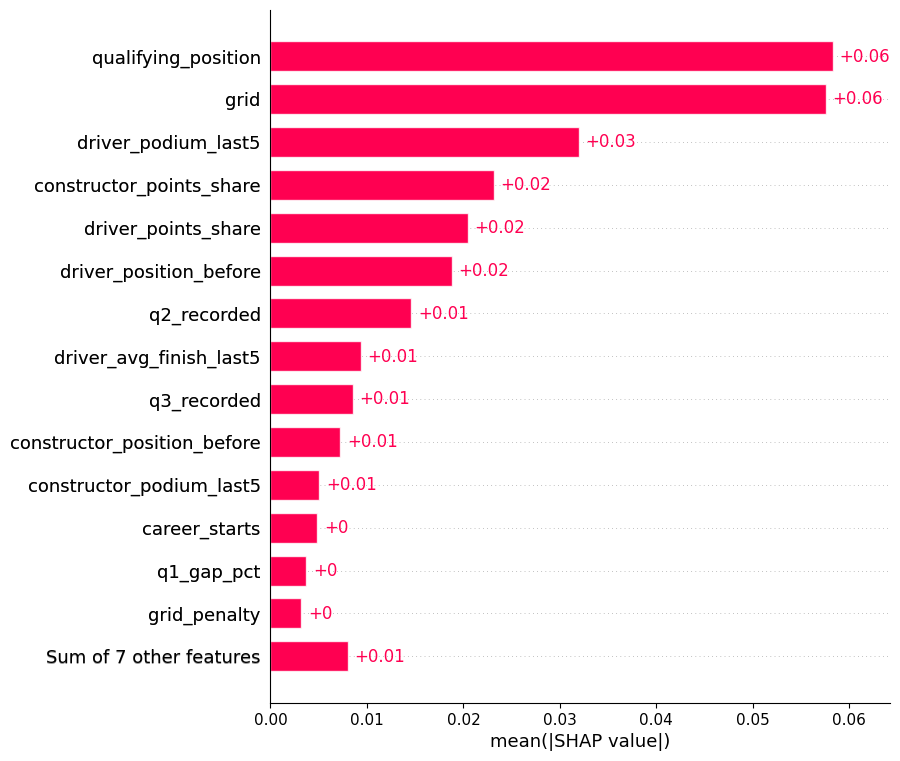

In [93]:
shap.plots.bar(shap_values,max_display=15)

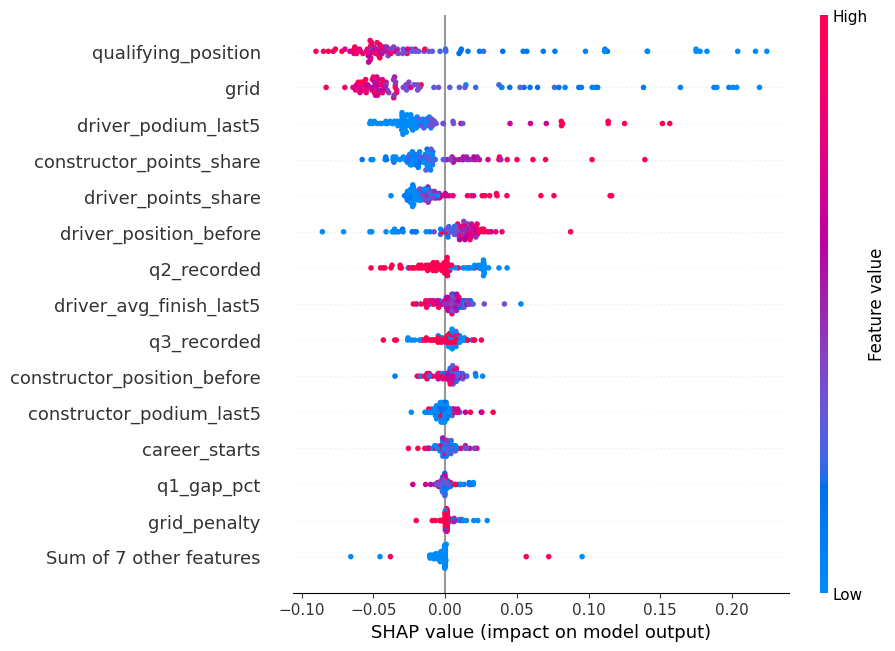

In [94]:
shap.plots.beeswarm(shap_values,max_display=15)

### Global XAI Findings

Permutation importance and SHAP consistently show that starting position and qualifying performance
are the strongest inputs used by NN1.

Permutation importance produced the largest validation PR-AUC decreases when `grid` (0.1488) and
`qualifying_position` (0.1483) were shuffled. Recent driver podium form (0.0712) and driver
championship points share (0.0681) were the next strongest contributors.

The global SHAP analysis gives a similar ranking. Qualifying position and grid have the largest
average absolute SHAP values, followed by recent driver podium form, constructor points share,
driver points share and pre-race driver championship position.

The SHAP beeswarm also shows sensible directional patterns. Better starting and qualifying
positions generally push the prediction toward a podium, while stronger recent podium form and
higher driver or constructor championship points shares also tend to increase the predicted podium
probability.

The agreement between permutation importance and SHAP strengthens the conclusion that NN1 relies
primarily on grid/qualifying information together with recent performance and championship
strength. These explanations describe associations learned by the model and must not be interpreted
as causal effects.

In [95]:
# ============================================================
# 13.3 LIME LOCAL EXPLANATION
# ============================================================

from lime.lime_tabular import LimeTabularExplainer

# Human-readable feature values after train-fitted median imputation,
# but BEFORE standardization
X_train_lime = pd.DataFrame(X_train_imp,columns=FEATURES)
X_val_lime = pd.DataFrame(X_val_imp,columns=FEATURES)

# LIME perturbs values in the original feature scale.
# The wrapper applies the already-fitted scaler before NN prediction.
def nn_predict_proba_lime(x):
    x = np.asarray(x,dtype=float)
    x_scaled = scaler.transform(x)
    podium_prob = best_nn.predict(x_scaled,verbose=0).ravel()
    return np.column_stack([1-podium_prob,podium_prob])

lime_explainer = LimeTabularExplainer(
    X_train_lime.values,
    feature_names=FEATURES,
    class_names=["Not Podium","Podium"],
    mode="classification",
    discretize_continuous=True,
    random_state=42
)

In [96]:
val_explain = val_df[["year","round","raceId","driverId","grid","podium"]].copy()
val_explain["predicted_probability"] = nn_val_prob
val_explain["predicted_class"] = (nn_val_prob>=nn_best_threshold).astype(int)

candidates = val_explain[
    (val_explain["podium"]==1) &
    (val_explain["predicted_class"]==1)
].copy()

candidates["distance_from_threshold"] = abs(
    candidates["predicted_probability"]-nn_best_threshold
)

local_idx = candidates.sort_values("distance_from_threshold").index[0]
local_pos = X_val.index.get_loc(local_idx)

display(val_explain.loc[[local_idx]])

,year,round,raceId,driverId,grid,podium,predicted_probability,predicted_class
23012,2021,9,1060,822,5,1,0.34097,1


In [97]:
lime_exp = lime_explainer.explain_instance(
    X_val_lime.iloc[local_pos].values,
    nn_predict_proba_lime,
    labels=[1],
    num_features=10
)

print("Top LIME contributions:")
for item in lime_exp.as_list(label=1):
    print(item)

Top LIME contributions:
('qual_time_missing <= 0.00', -0.16887465704993213)
('constructor_standing_missing <= 0.00', -0.11322629030203457)
('grid <= 6.00', 0.1118642953763681)
('qualifying_position <= 6.00', 0.10335179608389643)
('grid_zero_start <= 0.00', 0.09399185592438625)
('qualifying_missing <= 0.00', 0.08531975647545907)
('driver_podium_last5 > 0.20', 0.08183459210982527)
('constructor_points_share > 0.47', 0.06511795200587875)
('driver_form_missing <= 0.00', -0.05400691570304999)
('driver_standing_missing <= 0.00', -0.04588263573305451)


In [98]:
lime_exp.show_in_notebook(show_table=True)

### Local LIME Explanation

LIME was applied to a correctly predicted podium case close to the NN1 decision boundary.

The driver actually finished on the podium and NN1 assigned a podium probability of 0.3410,
just above the validation-selected classification threshold of 0.34. This makes the example useful
because the prediction was not an obvious high-confidence case.

The strongest positive local contributions were a starting grid position within the top six,
a qualifying position within the top six, a normal non-zero grid start, recent driver podium form,
and strong constructor championship performance.

For this observation, the driver started and qualified 5th, had reached the podium in 40% of the
previous five races, and drove for a constructor holding approximately 84% of the championship
leader's points. These factors collectively pushed the prediction toward the podium class.

Several missingness-indicator features received negative local LIME weights even though the
corresponding data were present. These coefficients should be interpreted cautiously because LIME
fits a local surrogate model and correlated features can redistribute contribution weights in
non-intuitive ways.

The explanation describes how NN1 formed this particular prediction and does not imply that any
feature causally produced the podium result.

In [99]:
local_record = val_df.loc[local_idx,FEATURES+["year","round","podium"]]
display(local_record.to_frame("Value"))

print(f"NN1 predicted podium probability: {nn_val_prob[local_pos]:.4f}")
print(f"NN1 classification threshold: {nn_best_threshold:.2f}")

,Value
grid,5
grid_zero_start,0
qualifying_position,5.0
q1_gap_pct,0.488724
q2_recorded,1
q3_recorded,1
grid_penalty,0.0
qualifying_missing,0
qual_time_missing,0
driver_position_before,5.0


NN1 predicted podium probability: 0.3410
NN1 classification threshold: 0.34


# 14. Podium Prediction Inference

The final inference function accepts one pre-race driver record and returns NN1's predicted
probability of finishing on the podium.

The function applies exactly the same processing used during model development:

1. arrange the input into the same 21-feature structure;
2. derive missing-value indicators and grid-related features where possible;
3. apply the Q1 pace cap learned from the training set;
4. apply the median imputer fitted on the training set;
5. apply the scaler fitted on the training set;
6. generate an NN1 podium probability;
7. convert the probability to a class using the validation-selected threshold.

No preprocessing object is refitted during inference. Missing values can therefore be handled using
only information learned from the original training data.

In [100]:
# ============================================================
# 14.1 PODIUM INFERENCE FUNCTION
# ============================================================

def predict_podium(record):
    row = {f:record.get(f,np.nan) for f in FEATURES}

    # Derive flags exactly as during feature engineering
    row["grid_zero_start"] = int(row["grid"]==0) if pd.notna(row["grid"]) else np.nan
    row["qualifying_missing"] = int(pd.isna(row["qualifying_position"]))
    row["qual_time_missing"] = int(pd.isna(row["q1_gap_pct"]))
    row["driver_standing_missing"] = int(pd.isna(row["driver_position_before"]))
    row["constructor_standing_missing"] = int(pd.isna(row["constructor_position_before"]))
    row["driver_form_missing"] = int(pd.isna(row["driver_podium_last5"]))
    row["constructor_form_missing"] = int(pd.isna(row["constructor_podium_last5"]))

    # Derive grid change from qualifying where possible
    if pd.notna(row["grid"]) and pd.notna(row["qualifying_position"]) and row["grid"]>0:
        row["grid_penalty"] = row["grid"]-row["qualifying_position"]
    else:
        row["grid_penalty"] = np.nan

    # Apply training-fitted Q1 outlier cap
    if pd.notna(row["q1_gap_pct"]):
        row["q1_gap_pct"] = min(row["q1_gap_pct"],Q1_GAP_CAP)

    input_df = pd.DataFrame([row],columns=FEATURES)

    # Use existing training-fitted preprocessing only
    input_imp = imputer.transform(input_df)
    input_scaled = scaler.transform(input_imp)

    probability = float(best_nn.predict(input_scaled,verbose=0).ravel()[0])
    predicted_class = int(probability>=nn_best_threshold)

    return {
        "podium_probability":probability,
        "predicted_class":predicted_class,
        "prediction":"Podium" if predicted_class==1 else "Not Podium",
        "threshold":float(nn_best_threshold),
        "missing_features":int(input_df.isna().sum(axis=1).iloc[0])
    }

In [101]:
# ============================================================
# 14.2 COMPLETE-RECORD EXAMPLE
# ============================================================

complete_candidates = test_df.dropna(subset=FEATURES)
complete_idx = complete_candidates.index[0]

complete_record = test_df.loc[complete_idx,FEATURES].to_dict()
complete_result = predict_podium(complete_record)

complete_metadata = test_df.loc[complete_idx,["year","round","raceId","driverId","grid","podium"]]

print("Complete input example:")
display(complete_metadata.to_frame("Value"))

print("\nPrediction:")
display(pd.DataFrame([complete_result]))

print(f"\nActual podium outcome: {int(complete_metadata['podium'])}")

Complete input example:


,Value
year,2022
round,2
raceId,1075
driverId,830
grid,4
podium,1



Prediction:


,podium_probability,predicted_class,prediction,threshold,missing_features
0,0.513366,1,Podium,0.34,0



Actual podium outcome: 1


In [102]:
# ============================================================
# 14.3 PARTIALLY-MISSING RECORD EXAMPLE
# ============================================================

partial_record = complete_record.copy()

# Simulate unavailable pre-race information
partial_record["q1_gap_pct"] = np.nan
partial_record["driver_position_before"] = np.nan
partial_record["driver_points_share"] = np.nan
partial_record["driver_podium_last5"] = np.nan
partial_record["driver_avg_finish_last5"] = np.nan

partial_result = predict_podium(partial_record)

missing_demo = pd.DataFrame({
    "Feature":["q1_gap_pct","driver_position_before","driver_points_share",
               "driver_podium_last5","driver_avg_finish_last5"],
    "Complete value":[complete_record["q1_gap_pct"],complete_record["driver_position_before"],
                      complete_record["driver_points_share"],complete_record["driver_podium_last5"],
                      complete_record["driver_avg_finish_last5"]],
    "Partial value":[np.nan,np.nan,np.nan,np.nan,np.nan]
})

display(missing_demo)

print("Prediction with partially missing input:")
display(pd.DataFrame([partial_result]))

,Feature,Complete value,Partial value
0,q1_gap_pct,0.082156,NaN
1,driver_position_before,19.000000,NaN
2,driver_points_share,0.000000,NaN
3,driver_podium_last5,0.800000,NaN
4,driver_avg_finish_last5,5.200000,NaN


Prediction with partially missing input:


,podium_probability,predicted_class,prediction,threshold,missing_features
0,0.911633,1,Podium,0.34,5


In [103]:
# ============================================================
# 14.4 COMPLETE VS PARTIAL INFERENCE
# ============================================================

inference_comparison = pd.DataFrame([
    {
        "Input":"Complete record",
        "Podium probability":complete_result["podium_probability"],
        "Prediction":complete_result["prediction"],
        "Missing features":complete_result["missing_features"]
    },
    {
        "Input":"Partially missing record",
        "Podium probability":partial_result["podium_probability"],
        "Prediction":partial_result["prediction"],
        "Missing features":partial_result["missing_features"]
    }
])

display(inference_comparison.round(4))

,Input,Podium probability,Prediction,Missing features
0,Complete record,0.5134,Podium,0
1,Partially missing record,0.9116,Podium,5


### Inference Demonstration Findings

The inference function successfully generated predictions for both a complete pre-race record and
a partially missing record without fitting any new preprocessing parameters.

For the complete example, all 21 model features were available. NN1 assigned a podium probability
of 0.5134, above the validation-selected threshold of 0.34, and correctly predicted a podium finish.

For the partially missing version of the same observation, five inputs were deliberately removed:
Q1 pace gap, driver championship position, driver points share, recent driver podium rate and recent
average finish. The inference pipeline used the median imputer fitted on the original training data
and updated the corresponding missingness indicators before applying the existing scaler and NN1.

The partially missing record received a higher podium probability of 0.9116. This increase should
not be interpreted as evidence that missing information improves podium chances. Removing features
changes both the imputed values and the missingness indicators presented to the model, so the
resulting prediction can shift substantially.

This demonstrates that the inference pipeline remains operational when pre-race information is
incomplete, while also showing that predictions based on missing information should be interpreted
with greater caution.

Post-race variables such as finishing position, race status, fastest lap, laps completed and race
points are never accepted as predictors.